# Business Understanding

### Background
Maritime transport is a major component of global trade, connecting economies through shipping routes, ports and logistics networks. Understanding how trade volumes, shipping capacity, connectivity and port activity interact is important for analysing the performance and evolution of the global maritime system.

### Problem Statement
Maritime trade data is distributed across multiple sources covering different aspects of the shipping system. Analysing these indicators separately limits the understanding of their relationships, emerging patterns and changes during major disruptions. An integrated analytical approach can provide broader insights into global maritime trade and its future trends.

### Objectives
**General Objective:**  
To analyse global maritime trade patterns, relationships and emerging trends using data analytics, statistical analysis and machine learning.

**Specific Objectives:**
1. Examine historical trends in global maritime trade and related indicators.
2. Investigate relationships among trade, shipping capacity, connectivity and port activity.
3. Analyse the effects of major disruptions on maritime trade and shipping activity.
4. Assess maritime resilience through disruption impact, recovery and stability.
5. Identify unusual port activity and group ports by operational patterns.
6. Develop exploratory forecasts of annual seaborne trade by cargo type and geographical region, where data permits.

### Research Questions
1. How have global maritime trade patterns evolved over time?
2. What relationships exist among trade, shipping capacity, connectivity and port activity?
3. How have major disruptions affected maritime trade and shipping activity?
4. How does the maritime system respond and recover from disruptions?
5. What similarities and unusual activity patterns can be identified across ports?
6. What future trends in seaborne trade by cargo type and region can be estimated?

### Scope and Expected Outcomes
The project uses eight datasets covering seaborne trade, container throughput, merchant fleets, connectivity, port calls, port performance, daily port activity and chokepoint transits.

Expected outcomes include insights into maritime trade patterns, relationships, disruption impacts, port activity and exploratory trade forecasts. Forecasts will be evaluated against a naïve baseline. Findings describe associations rather than establish causation, and forecasts are subject to data coverage and limitations.


# Data Understanding

In [100]:
!pip install pycountry

# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from statsmodels.tsa.arima.model import ARIMA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (r2_score,mean_absolute_error,mean_squared_error,mean_absolute_percentage_error,silhouette_score,davies_bouldin_score,calinski_harabasz_score)
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
from pathlib import Path
import pycountry

PROC = Path("Datasets/processed")
PROC.mkdir(parents=True, exist_ok=True)

In [101]:
# load daily ports
portwatch = pd.read_csv("/content/daily_ports_all.csv")
print(portwatch.shape)
portwatch.head()

(116752, 30)


,date,year,month,day,portid,portname,country,ISO3,portcalls_container,portcalls_dry_bulk,...,import_cargo,import,export_container,export_dry_bulk,export_general_cargo,export_roro,export_tanker,export_cargo,export,ObjectId
0,2021-03-11,2021,3,11,port1325,Tsuruga,Japan,JPN,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2020-02-05,2020,2,5,port1325,Tsuruga,Japan,JPN,0,0,...,160.0,160.0,0.0,0.0,0.0,543.0,0.0,543.0,543.0,2.0
2,2021-03-12,2021,3,12,port1325,Tsuruga,Japan,JPN,0,1,...,242.0,242.0,0.0,1754.0,0.0,0.0,0.0,1754.0,1754.0,3.0
3,2021-03-13,2021,3,13,port1325,Tsuruga,Japan,JPN,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
4,2021-03-14,2021,3,14,port1325,Tsuruga,Japan,JPN,0,1,...,320.0,320.0,0.0,2670.0,0.0,1087.0,0.0,3758.0,3758.0,5.0


In [102]:
portwatch.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116752 entries, 0 to 116751
Data columns (total 30 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   date                     116752 non-null  object 
 1   year                     116752 non-null  int64  
 2   month                    116752 non-null  int64  
 3   day                      116752 non-null  int64  
 4   portid                   116752 non-null  object 
 5   portname                 116752 non-null  object 
 6   country                  116752 non-null  object 
 7   ISO3                     116752 non-null  object 
 8   portcalls_container      116752 non-null  int64  
 9   portcalls_dry_bulk       116752 non-null  int64  
 10  portcalls_general_cargo  116752 non-null  int64  
 11  portcalls_roro           116752 non-null  int64  
 12  portcalls_tanker         116751 non-null  float64
 13  portcalls_cargo          116751 non-null  float64
 14  port

In [103]:
portwatch.describe()

,year,month,day,portcalls_container,portcalls_dry_bulk,portcalls_general_cargo,portcalls_roro,portcalls_tanker,portcalls_cargo,portcalls,...,import_cargo,import,export_container,export_dry_bulk,export_general_cargo,export_roro,export_tanker,export_cargo,export,ObjectId
count,116752.000000,116752.000000,116752.00000,116752.000000,116752.000000,116752.000000,116752.000000,116751.000000,116751.000000,116751.000000,...,1.167510e+05,1.167510e+05,1.167510e+05,116751.000000,116751.000000,116751.000000,116751.000000,1.167510e+05,1.167510e+05,116751.000000
mean,2022.429577,6.433594,15.68899,1.096898,1.207996,1.269409,0.104127,1.786931,3.678452,5.465384,...,4.026027e+04,4.780021e+04,1.362203e+04,17464.779197,1074.138303,29.675121,5440.618590,3.219079e+04,3.763154e+04,58376.000000
std,2.270586,3.411897,8.80271,3.479044,2.138999,2.371296,0.358142,3.838881,5.743654,7.952048,...,1.261466e+05,1.435959e+05,8.270045e+04,64961.602834,2466.994589,245.412190,20379.574989,1.053617e+05,1.097574e+05,33703.254976
min,2019.000000,1.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,1.000000
25%,2020.000000,3.000000,8.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,29188.500000
50%,2022.000000,6.000000,16.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,...,1.600000e+02,6.240000e+02,0.000000e+00,0.000000,0.000000,0.000000,0.000000,1.420000e+02,7.700000e+02,58376.000000
75%,2024.000000,9.000000,23.00000,1.000000,2.000000,1.000000,0.000000,2.000000,5.000000,8.000000,...,1.187450e+04,2.130850e+04,0.000000e+00,1202.500000,988.000000,0.000000,770.000000,8.944000e+03,1.745700e+04,87563.500000
max,2026.000000,12.000000,31.00000,37.000000,20.000000,22.000000,5.000000,36.000000,60.000000,67.000000,...,3.396441e+06,3.706936e+06,1.311657e+06,853257.000000,41336.000000,10061.000000,594381.000000,1.315137e+06,1.365073e+06,116751.000000


In [104]:
## check portwatch mising values
portwatch.isnull().sum()

,0
date,0
year,0
month,0
day,0
portid,0
portname,0
country,0
ISO3,0
portcalls_container,0
portcalls_dry_bulk,0


In [105]:
portwatch.duplicated().sum()

np.int64(0)

In [106]:
# load us seaborne
seaborne = pd.read_csv('/content/US.SeaborneTrade_20261110_095251 (1).csv')
print(seaborne.shape)
seaborne.head()

(333, 77)


,Economy_Label,CargoType_Label,2000_Metric_tons_in_thousands_Value,2000_Metric_tons_Footnote,2000_Metric_tons_MissingValue,2001_Metric_tons_in_thousands_Value,2001_Metric_tons_Footnote,2001_Metric_tons_MissingValue,2002_Metric_tons_in_thousands_Value,2002_Metric_tons_Footnote,...,2021_Metric_tons_MissingValue,2022_Metric_tons_in_thousands_Value,2022_Metric_tons_Footnote,2022_Metric_tons_MissingValue,2023_Metric_tons_in_thousands_Value,2023_Metric_tons_Footnote,2023_Metric_tons_MissingValue,2024_Metric_tons_in_thousands_Value,2024_Metric_tons_Footnote,2024_Metric_tons_MissingValue
0,World,Crude oil loaded,1812768.0,NaN,NaN,1819232.0,NaN,NaN,1788715.0,NaN,...,NaN,2029559.0,NaN,NaN,2071488.0,NaN,NaN,2042568.0,NaN,NaN
1,World,Other tanker trade loaded,1171172.0,NaN,NaN,1162476.0,NaN,NaN,1196826.0,NaN,...,NaN,2290940.0,NaN,NaN,2288012.0,NaN,NaN,2284711.0,NaN,NaN
2,World,Dry cargo loaded,3361790.0,NaN,NaN,3416510.0,NaN,NaN,3591200.0,NaN,...,NaN,7433784.0,NaN,NaN,7239276.0,NaN,NaN,7726790.0,NaN,NaN
3,World,Total goods loaded,6345730.0,NaN,NaN,6398217.0,NaN,NaN,6576741.0,NaN,...,NaN,11754284.0,NaN,NaN,11598777.0,NaN,NaN,12054069.0,NaN,NaN
4,World,Crude oil discharged,1812768.0,NaN,NaN,1819232.0,NaN,NaN,1788715.0,NaN,...,NaN,2029559.0,NaN,NaN,2071488.0,NaN,NaN,2042568.0,NaN,NaN


In [107]:
seaborne.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 77 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Economy_Label                        333 non-null    object 
 1   CargoType_Label                      333 non-null    object 
 2   2000_Metric_tons_in_thousands_Value  323 non-null    float64
 3   2000_Metric_tons_Footnote            0 non-null      float64
 4   2000_Metric_tons_MissingValue        9 non-null      object 
 5   2001_Metric_tons_in_thousands_Value  322 non-null    float64
 6   2001_Metric_tons_Footnote            0 non-null      float64
 7   2001_Metric_tons_MissingValue        9 non-null      object 
 8   2002_Metric_tons_in_thousands_Value  324 non-null    float64
 9   2002_Metric_tons_Footnote            0 non-null      float64
 10  2002_Metric_tons_MissingValue        9 non-null      object 
 11  2003_Metric_tons_in_thousands_Va

In [108]:
seaborne.describe()

,2000_Metric_tons_in_thousands_Value,2000_Metric_tons_Footnote,2001_Metric_tons_in_thousands_Value,2001_Metric_tons_Footnote,2002_Metric_tons_in_thousands_Value,2002_Metric_tons_Footnote,2003_Metric_tons_in_thousands_Value,2003_Metric_tons_Footnote,2004_Metric_tons_in_thousands_Value,2004_Metric_tons_Footnote,...,2020_Metric_tons_in_thousands_Value,2020_Metric_tons_Footnote,2021_Metric_tons_in_thousands_Value,2021_Metric_tons_Footnote,2022_Metric_tons_in_thousands_Value,2022_Metric_tons_Footnote,2023_Metric_tons_in_thousands_Value,2023_Metric_tons_Footnote,2024_Metric_tons_in_thousands_Value,2024_Metric_tons_Footnote
count,3.230000e+02,0.0,3.220000e+02,0.0,3.240000e+02,0.0,3.220000e+02,0.0,3.230000e+02,0.0,...,3.230000e+02,0.0,3.240000e+02,0.0,3.240000e+02,0.0,3.240000e+02,0.0,3.240000e+02,0.0
mean,9.871586e+05,NaN,9.974137e+05,NaN,1.019340e+06,NaN,1.080934e+06,NaN,1.166356e+06,NaN,...,1.830849e+06,NaN,1.900331e+06,NaN,1.906340e+06,NaN,1.883756e+06,NaN,1.966969e+06,NaN
std,1.533092e+06,NaN,1.545379e+06,NaN,1.585122e+06,NaN,1.669515e+06,NaN,1.801689e+06,NaN,...,2.829516e+06,NaN,2.939173e+06,NaN,2.938670e+06,NaN,2.901268e+06,NaN,3.051610e+06,NaN
min,1.000000e+00,NaN,0.000000e+00,NaN,1.000000e+00,NaN,0.000000e+00,NaN,1.000000e+00,NaN,...,0.000000e+00,NaN,0.000000e+00,NaN,0.000000e+00,NaN,0.000000e+00,NaN,0.000000e+00,NaN
25%,6.204950e+04,NaN,6.161550e+04,NaN,5.827925e+04,NaN,6.325275e+04,NaN,6.363000e+04,NaN,...,1.232500e+05,NaN,1.228542e+05,NaN,1.261062e+05,NaN,1.285468e+05,NaN,1.338748e+05,NaN
50%,4.190540e+05,NaN,4.285210e+05,NaN,4.487830e+05,NaN,4.721545e+05,NaN,5.050890e+05,NaN,...,7.404920e+05,NaN,7.616535e+05,NaN,7.510270e+05,NaN,7.722395e+05,NaN,7.890845e+05,NaN
75%,1.215596e+06,NaN,1.215856e+06,NaN,1.232880e+06,NaN,1.314100e+06,NaN,1.405542e+06,NaN,...,2.205966e+06,NaN,2.326580e+06,NaN,2.314270e+06,NaN,2.308013e+06,NaN,2.404866e+06,NaN
max,1.269146e+07,NaN,1.279643e+07,NaN,1.315348e+07,NaN,1.386194e+07,NaN,1.498393e+07,NaN,...,2.263529e+07,NaN,2.354976e+07,NaN,2.350857e+07,NaN,2.319755e+07,NaN,2.410814e+07,NaN


In [109]:
# missing values in seaborne
seaborne.isnull().sum()

,0
Economy_Label,0
CargoType_Label,0
2000_Metric_tons_in_thousands_Value,10
2000_Metric_tons_Footnote,333
2000_Metric_tons_MissingValue,324
...,...
2023_Metric_tons_Footnote,333
2023_Metric_tons_MissingValue,324
2024_Metric_tons_in_thousands_Value,9
2024_Metric_tons_Footnote,333


In [110]:
seaborne.duplicated().sum()

np.int64(0)

In [111]:
# load merchant fleet
fleet = pd.read_csv('/content/US_MerchantFleet.csv')
print(fleet.shape)
fleet.head()

(63896, 23)


,Year,Economy,Economy Label,ShipType,ShipType Label,Dead weight tons in thousands,Dead weight tons in thousands Footnote,Dead weight tons in thousands Missing value,Percentage of total world,Percentage of total world Footnote,...,Percentage of total fleet Missing value,Number of ships,Number of ships Footnote,Number of ships Missing value,Gross Tonnage in thousands,Gross Tonnage in thousands Footnote,Gross Tonnage in thousands Missing value,Average age of vessels (years),Average age of vessels (years) Footnote,Average age of vessels (years) Missing value
0,1980,0000,World,0,Total fleet,672192.465,NaN,NaN,100.0,NaN,...,NaN,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected
1,1980,0000,World,1,Oil tankers,337945.534,NaN,NaN,100.0,NaN,...,NaN,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected
2,1980,0000,World,2,Bulk carriers,181880.282,NaN,NaN,100.0,NaN,...,NaN,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected
3,1980,0000,World,3,General cargo,112840.897,NaN,NaN,100.0,NaN,...,NaN,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected
4,1980,0000,World,4,Container ships,10290.114,NaN,NaN,100.0,NaN,...,NaN,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected,NaN,NaN,No value reported or collected


In [112]:
fleet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63896 entries, 0 to 63895
Data columns (total 23 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Year                                          63896 non-null  int64  
 1   Economy                                       63896 non-null  object 
 2   Economy Label                                 63896 non-null  object 
 3   ShipType                                      63896 non-null  int64  
 4   ShipType Label                                63896 non-null  object 
 5   Dead weight tons in thousands                 58814 non-null  float64
 6   Dead weight tons in thousands Footnote        24 non-null     object 
 7   Dead weight tons in thousands Missing value   5082 non-null   object 
 8   Percentage of total world                     58814 non-null  float64
 9   Percentage of total world Footnote            24 non-null    

In [113]:
fleet.describe()

,Year,ShipType,Dead weight tons in thousands,Percentage of total world,Percentage of total fleet,Number of ships,Gross Tonnage in thousands,Average age of vessels (years)
count,63896.000000,63896.000000,5.881400e+04,58814.000000,58814.000000,24600.000000,2.460000e+04,20023.000000
mean,2004.610852,2.457759,2.174818e+04,5.397872,37.797279,1506.377154,2.017613e+04,24.460755
std,13.783127,1.748450,8.731343e+04,12.848273,37.409220,5927.114144,7.814213e+04,11.648492
min,1980.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,1993.000000,1.000000,1.753525e+01,0.008471,5.930415,2.000000,2.652000e+00,16.080000
50%,2006.000000,2.000000,4.118255e+02,0.188330,22.924635,35.000000,1.707100e+02,23.290000
75%,2017.000000,4.000000,6.420298e+03,3.591282,66.899630,543.250000,4.086645e+03,30.906500
max,2026.000000,5.000000,2.528788e+06,100.000000,100.000000,115649.000000,1.737514e+06,109.920000


In [114]:
fleet.isnull().sum()

,0
Year,0
Economy,0
Economy Label,0
ShipType,0
ShipType Label,0
Dead weight tons in thousands,5082
Dead weight tons in thousands Footnote,63872
Dead weight tons in thousands Missing value,58814
Percentage of total world,5082
Percentage of total world Footnote,63872


In [115]:
fleet.duplicated().sum()

np.int64(0)

In [116]:
# load lsci
lsci = pd.read_csv('/content/US.LSCI_20261121_091634.csv')
print(lsci.shape)
lsci.head()

(15013, 5)


,Economy_Label,Quarter_Label,Index_average_Q1_2023__100_Value,Index_average_Q1_2023__100_Footnote,Index_average_Q1_2023__100_MissingValue
0,Albania,Q4 2006,5.01,NaN,NaN
1,Albania,Q1 2007,5.48,NaN,NaN
2,Albania,Q2 2007,5.48,NaN,NaN
3,Albania,Q3 2007,5.04,NaN,NaN
4,Albania,Q4 2007,5.19,NaN,NaN


In [117]:
lsci.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15013 entries, 0 to 15012
Data columns (total 5 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Economy_Label                            15013 non-null  object 
 1   Quarter_Label                            15013 non-null  object 
 2   Index_average_Q1_2023__100_Value         14724 non-null  float64
 3   Index_average_Q1_2023__100_Footnote      0 non-null      float64
 4   Index_average_Q1_2023__100_MissingValue  289 non-null    object 
dtypes: float64(2), object(3)
memory usage: 586.6+ KB


In [118]:
lsci.describe()

,Index_average_Q1_2023__100_Value,Index_average_Q1_2023__100_Footnote
count,14724.000000,0.0
mean,96.932643,NaN
std,133.808579,NaN
min,2.500000,NaN
25%,22.792500,NaN
50%,47.060000,NaN
75%,106.880000,NaN
max,1341.970000,NaN


In [119]:
lsci.isnull().sum()

,0
Economy_Label,0
Quarter_Label,0
Index_average_Q1_2023__100_Value,289
Index_average_Q1_2023__100_Footnote,15013
Index_average_Q1_2023__100_MissingValue,14724


In [120]:
lsci.duplicated().sum()

np.int64(0)

In [121]:
# load container throughput
teu = pd.read_csv('/content/US_ContPortThroughput.csv')
print(teu.shape)
teu.head()

(3030, 6)


,Year,Economy,Economy Label,TEU (Twenty foot Equivalent Unit),TEU (Twenty foot Equivalent Unit) Footnote,TEU (Twenty foot Equivalent Unit) Missing value
0,2010,0,World,545520944.0,NaN,NaN
1,2010,5100,Africa,23416816.0,NaN,NaN
2,2010,5110,Northern Africa,12024778.0,NaN,NaN
3,2010,5120,Sub-Saharan Africa,11392038.0,NaN,NaN
4,2010,5121,Eastern Africa,2297961.0,NaN,NaN


In [122]:
teu.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3030 entries, 0 to 3029
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Year                                             3030 non-null   int64  
 1   Economy                                          3030 non-null   int64  
 2   Economy Label                                    3030 non-null   object 
 3   TEU (Twenty foot Equivalent Unit)                2900 non-null   float64
 4   TEU (Twenty foot Equivalent Unit) Footnote       19 non-null     object 
 5   TEU (Twenty foot Equivalent Unit) Missing value  130 non-null    object 
dtypes: float64(1), int64(2), object(3)
memory usage: 142.2+ KB


In [123]:
teu.describe()

,Year,Economy,TEU (Twenty foot Equivalent Unit)
count,3030.000000,3030.000000,2.900000e+03
mean,2017.000000,1431.004950,4.752831e+07
std,4.321207,1819.965223,1.193780e+08
min,2010.000000,0.000000,9.500000e+03
25%,2013.000000,308.000000,4.678590e+05
50%,2017.000000,612.000000,3.420179e+06
75%,2021.000000,1530.000000,2.146032e+07
max,2024.000000,5706.000000,9.203008e+08


In [124]:
teu.isnull().sum()

,0
Year,0
Economy,0
Economy Label,0
TEU (Twenty foot Equivalent Unit),130
TEU (Twenty foot Equivalent Unit) Footnote,3011
TEU (Twenty foot Equivalent Unit) Missing value,2900


In [125]:
teu.duplicated().sum()

np.int64(0)

In [126]:
# load chokepoints
choke = pd.read_csv('/content/Daily_Chokepoints_Data.csv')
print(choke.shape)
choke.head()

(80528, 21)


,date,year,month,day,portid,portname,n_container,n_dry_bulk,n_general_cargo,n_roro,...,n_cargo,n_total,capacity_container,capacity_dry_bulk,capacity_general_cargo,capacity_roro,capacity_tanker,capacity_cargo,capacity,ObjectId
0,2019/01/01,2019,1,1,chokepoint1,Suez Canal,15,15,9,4,...,43,61,1018466,618654,112660,21900,1279775,1771682,3051458,1
1,2021/03/11,2021,3,11,chokepoint1,Suez Canal,16,12,3,2,...,33,56,964354,351621,20733,10326,1021116,1347035,2368151,2
2,2019/01/02,2019,1,2,chokepoint1,Suez Canal,24,4,6,6,...,40,50,1534924,227315,8536,37934,518306,1808711,2327017,3
3,2019/01/03,2019,1,3,chokepoint1,Suez Canal,13,14,9,2,...,38,62,555097,977689,39398,10829,868092,1583014,2451107,4
4,2021/03/12,2021,3,12,chokepoint1,Suez Canal,22,15,3,2,...,42,54,1372498,752113,2341,11084,670038,2138038,2808077,5


In [127]:
choke.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80528 entries, 0 to 80527
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   date                    80528 non-null  object
 1   year                    80528 non-null  int64 
 2   month                   80528 non-null  int64 
 3   day                     80528 non-null  int64 
 4   portid                  80528 non-null  object
 5   portname                80528 non-null  object
 6   n_container             80528 non-null  int64 
 7   n_dry_bulk              80528 non-null  int64 
 8   n_general_cargo         80528 non-null  int64 
 9   n_roro                  80528 non-null  int64 
 10  n_tanker                80528 non-null  int64 
 11  n_cargo                 80528 non-null  int64 
 12  n_total                 80528 non-null  int64 
 13  capacity_container      80528 non-null  int64 
 14  capacity_dry_bulk       80528 non-null  int64 
 15  ca

In [128]:
choke.describe()

,year,month,day,n_container,n_dry_bulk,n_general_cargo,n_roro,n_tanker,n_cargo,n_total,capacity_container,capacity_dry_bulk,capacity_general_cargo,capacity_roro,capacity_tanker,capacity_cargo,capacity,ObjectId
count,80528.000000,80528.000000,80528.000000,80528.000000,80528.000000,80528.000000,80528.000000,80528.000000,80528.000000,80528.000000,8.052800e+04,8.052800e+04,80528.000000,80528.000000,8.052800e+04,8.052800e+04,8.052800e+04,80528.000000
mean,2022.443672,6.440542,15.688804,14.387666,21.664167,11.469278,2.315766,20.811072,49.836877,70.647949,3.667380e+05,1.097857e+06,38229.182036,5440.079053,5.997501e+05,1.508265e+06,2.108016e+06,40264.500000
std,2.265885,3.413100,8.800194,20.696034,23.221566,15.890087,3.221351,22.203804,51.798241,71.148095,5.214239e+05,1.282904e+06,48834.982214,8670.923652,8.209306e+05,1.581379e+06,2.105823e+06,23246.575576
min,2019.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
25%,2020.000000,3.000000,8.000000,1.000000,4.000000,1.000000,0.000000,4.000000,12.000000,16.000000,1.158750e+04,1.355515e+05,3470.000000,0.000000,3.459850e+04,2.281238e+05,2.912115e+05,20132.750000
50%,2022.000000,6.000000,16.000000,6.000000,13.000000,4.000000,1.000000,12.000000,32.000000,46.000000,1.007985e+05,5.545225e+05,17303.500000,0.000000,2.563505e+05,8.743895e+05,1.406020e+06,40264.500000
75%,2024.000000,9.000000,23.000000,17.000000,32.000000,17.000000,3.000000,30.000000,66.000000,95.000000,5.417912e+05,1.732328e+06,55880.250000,7942.500000,8.677295e+05,2.327564e+06,3.258355e+06,60396.250000
max,2026.000000,12.000000,31.000000,172.000000,245.000000,149.000000,23.000000,148.000000,352.000000,472.000000,4.016066e+06,1.317163e+07,388902.000000,83176.000000,6.596353e+06,1.434564e+07,1.632013e+07,80528.000000


In [129]:
choke.isnull().sum()

,0
date,0
year,0
month,0
day,0
portid,0
portname,0
n_container,0
n_dry_bulk,0
n_general_cargo,0
n_roro,0


In [130]:
choke.duplicated().sum()

np.int64(0)

In [131]:
# load port calls
calls = pd.read_csv('/content/US_PortCallsArrivals_S.csv')
print(calls.shape)
calls.head()

(9300, 9)


,Period,Period Label,Economy,Economy Label,CommercialMarket,CommercialMarket Label,Number of port calls,Number of port calls Footnote,Number of port calls Missing value
0,2018S01,S1 2018,1,Individual economies,0,All ships,NaN,NaN,Not applicable
1,2018S01,S1 2018,1,Individual economies,2,Liquid bulk carriers,NaN,NaN,Not applicable
2,2018S01,S1 2018,1,Individual economies,7,Liquefied petroleum gas carriers,NaN,NaN,Not applicable
3,2018S01,S1 2018,1,Individual economies,8,Liquefied natural gas carriers,NaN,NaN,Not applicable
4,2018S01,S1 2018,1,Individual economies,5,Dry bulk carriers,NaN,NaN,Not applicable


In [132]:
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9300 entries, 0 to 9299
Data columns (total 9 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Period                              9300 non-null   object 
 1   Period Label                        9300 non-null   object 
 2   Economy                             9300 non-null   int64  
 3   Economy Label                       9300 non-null   object 
 4   CommercialMarket                    9300 non-null   int64  
 5   CommercialMarket Label              9300 non-null   object 
 6   Number of port calls                8810 non-null   float64
 7   Number of port calls Footnote       0 non-null      float64
 8   Number of port calls Missing value  490 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 654.0+ KB


In [133]:
calls.describe()

,Economy,CommercialMarket,Number of port calls,Number of port calls Footnote
count,9300.000000,9300.000000,8.810000e+03,0.0
mean,2821.193011,3.962903,6.490234e+04,NaN
std,2112.189066,2.568352,1.991938e+05,NaN
min,0.000000,0.000000,1.100000e+01,NaN
25%,842.000000,2.000000,1.380500e+03,NaN
50%,1640.000000,4.000000,7.185000e+03,NaN
75%,5221.000000,6.000000,4.047450e+04,NaN
max,5900.000000,8.000000,2.461711e+06,NaN


In [134]:
choke.isnull().sum()

,0
date,0
year,0
month,0
day,0
portid,0
portname,0
n_container,0
n_dry_bulk,0
n_general_cargo,0
n_roro,0


In [135]:
choke.duplicated().sum()

np.int64(0)

In [136]:
# load cppi
cppi = pd.read_excel('/content/CPPI 2020-2025.xlsx')
print(cppi.shape)
cppi.head()

(426, 20)


,Port,UN/LOCODE,Territory,World Bank Region,Region average CPPI,World Bank Income Group,Income Group average CPPI,Maritime services region,Region's average cppi,CPPI 2020,CPPI 2021,CPPI 2022,CPPI 2023,CPPI 2024,CPPI 2025,Rank 2025,Berth hours in % of port hours,Statistical Index,Administrative Index,Number of calls in sample
0,Aarhus,DKAAR,Denmark,ECA,-8.086595,HI,1.362073,North Europe,-7.718713,73.0,38.0,22.0,60.0,99.0,86.634702,33.0,0.856896,47.61,125.659404,292.0
1,Abidjan,CIABJ,Côte d’Ivoire,SSA,-71.972350,LMI,-8.954771,West Africa,-66.152693,19.0,-153.0,-144.0,-38.0,-51.0,-127.472673,381.0,0.595764,-70.25,-184.695347,407.0
2,Acajutla,SVAQJ,El Salvador,LAC,-14.986492,UMI,1.615451,Caribbean & Central America,-19.239499,0.0,-7.0,-30.0,-89.0,-98.0,-207.620361,393.0,0.479969,-143.38,-271.860723,71.0
3,Adelaide,AUADL,Australia,EAP,30.729639,HI,1.362073,Australasia & Oceania,-11.011090,-20.0,-2.0,-24.0,-39.0,-8.0,-18.214819,297.0,0.833064,-11.43,-24.999638,213.0
4,Aden,YEADE,Yemen,MENAAP,18.958816,LI,-23.905865,Red Sea,63.164190,NaN,-21.0,-13.0,4.0,-24.0,NaN,NaN,NaN,NaN,NaN,NaN


In [137]:
cppi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426 entries, 0 to 425
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Port                            424 non-null    object 
 1   UN/LOCODE                       419 non-null    object 
 2   Territory                       419 non-null    object 
 3   World Bank Region               419 non-null    object 
 4   Region average CPPI             419 non-null    float64
 5   World Bank Income Group         419 non-null    object 
 6   Income Group average CPPI       419 non-null    float64
 7   Maritime services region        419 non-null    object 
 8   Region's average cppi           419 non-null    float64
 9   CPPI 2020                       326 non-null    float64
 10  CPPI 2021                       352 non-null    float64
 11  CPPI 2022                       340 non-null    float64
 12  CPPI 2023                       391 

In [138]:
cppi.describe()

,Region average CPPI,Income Group average CPPI,Region's average cppi,CPPI 2020,CPPI 2021,CPPI 2022,CPPI 2023,CPPI 2024,CPPI 2025,Rank 2025,Berth hours in % of port hours,Statistical Index,Administrative Index,Number of calls in sample
count,419.000000,419.000000,419.000000,326.000000,352.000000,340.000000,391.000000,403.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,-1.341200,-1.359779,-0.973744,37.710675,5.373509,-2.009647,6.866905,0.012407,-1.288518,200.500000,0.756255,-1.871100,-0.705937,449.247500
std,29.907600,6.021963,36.738435,48.038120,80.082824,78.582603,68.823008,71.335361,64.520553,115.614301,0.136932,38.801558,90.544433,782.571439
min,-71.972350,-25.469787,-98.080938,-108.000000,-665.000000,-675.000000,-519.000000,-721.000000,-302.583415,1.000000,0.369475,-176.720000,-428.446829,24.000000
25%,-14.986492,1.362073,-19.239499,6.000000,-7.000000,-16.000000,-12.500000,-16.500000,-19.752567,100.750000,0.673786,-12.080000,-25.612862,81.750000
50%,-8.086595,1.362073,-7.718713,24.000000,12.000000,7.860000,6.000000,4.000000,1.371539,200.500000,0.785014,1.000000,2.509513,194.000000
75%,30.729639,1.615451,17.910438,68.000000,39.000000,34.000000,39.000000,27.000000,24.013080,300.250000,0.860420,13.542500,33.262400,457.000000
max,34.424249,1.615451,103.168045,170.000000,152.000000,139.000000,152.000000,146.000000,144.638476,400.000000,0.983194,83.550000,209.356951,7385.000000


In [139]:
cppi.isnull().sum()

,0
Port,2
UN/LOCODE,7
Territory,7
World Bank Region,7
Region average CPPI,7
World Bank Income Group,7
Income Group average CPPI,7
Maritime services region,7
Region's average cppi,7
CPPI 2020,100


In [140]:
cppi.duplicated().sum()

np.int64(1)

# Data Preparation.

####  IMF Portwatch

In [141]:
portwatch.isnull().sum()

,0
date,0
year,0
month,0
day,0
portid,0
portname,0
country,0
ISO3,0
portcalls_container,0
portcalls_dry_bulk,0


In [142]:
# Inspect
print("Shape:", portwatch.shape)
print("Ports:", portwatch.portid.nunique(), "| countries:", portwatch.country.nunique(), "| ISO3:", portwatch.ISO3.nunique())
print("Missing values:", int(portwatch.isnull().sum().sum()))
print("Duplicate port-day records:", portwatch.duplicated(["portid", "date"]).sum(), "| fully duplicated rows:", portwatch.duplicated().sum())

Shape: (116752, 30)
Ports: 42 | countries: 14 | ISO3: 14
Missing values: 18
Duplicate port-day records: 0 | fully duplicated rows: 0


In [143]:
# Dates
portwatch["date"] = pd.to_datetime(portwatch["date"])
parts_match = (portwatch.date.dt.year.eq(portwatch.year) & portwatch.date.dt.month.eq(portwatch.month) & portwatch.date.dt.day.eq(portwatch.day)).mean()
print("year, month, day agree with date:", round(parts_match, 4))
print("period:", portwatch.date.min().date(), "-", portwatch.date.max().date())

year, month, day agree with date: 1.0
period: 2019-01-01 - 2026-11-13


In [144]:
# Panel completeness: every port should have every day
days = portwatch.date.nunique()
per_port = portwatch.groupby("portid").date.agg(["min", "max", "nunique"])
print("days in period:", days, "| ports with every day:", int((per_port["nunique"] == days).sum()), "of", len(per_port))
print("expected rows if complete:", len(per_port) * days, "| actual:", len(portwatch))
print(per_port["nunique"].describe().round(0).to_dict())


days in period: 2874 | ports with every day: 40 of 42
expected rows if complete: 120708 | actual: 116752
{'count': 42.0, 'mean': 2780.0, 'std': 463.0, 'min': 77.0, '25%': 2874.0, '50%': 2874.0, '75%': 2874.0, 'max': 2874.0}


In [145]:
# One name and one country per port
meta = portwatch.groupby("portid")[["portname", "country", "ISO3"]].nunique()
print("ports with more than one name / country / ISO3:", (meta > 1).sum().to_dict())
print("ports without ISO3:", int(portwatch.drop_duplicates("portid").ISO3.isna().sum()))

ports with more than one name / country / ISO3: {'portname': 0, 'country': 0, 'ISO3': 0}
ports without ISO3: 0


In [146]:
# How the totals are built
types5 = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]
types4 = ["container", "dry_bulk", "general_cargo", "roro"]
for prefix in ["portcalls", "import", "export"]:
    five = portwatch[[f"{prefix}_{t}" for t in types5]].sum(axis=1)
    four = portwatch[[f"{prefix}_{t}" for t in types4]].sum(axis=1)
    print(f"{prefix:10} total = 5 types: {(portwatch[prefix] == five).mean():.4f} | cargo = 4 types (no tankers): {(portwatch[prefix + '_cargo'] == four).mean():.4f} | cargo = total: {(portwatch[prefix + '_cargo'] == portwatch[prefix]).mean():.4f}")

portcalls  total = 5 types: 1.0000 | cargo = 4 types (no tankers): 1.0000 | cargo = total: 0.5957
import     total = 5 types: 0.7431 | cargo = 4 types (no tankers): 0.8419 | cargo = total: 0.6721
export     total = 5 types: 0.7563 | cargo = 4 types (no tankers): 0.8469 | cargo = total: 0.6955


In [147]:
# Values
num = portwatch.select_dtypes("number").drop(columns=["year", "month", "day", "ObjectId"])
print("negative values:", int((num < 0).sum().sum()), "| non-finite:", int((~np.isfinite(num)).sum().sum()))
print("port-days with no calls:", round(float(portwatch.portcalls.eq(0).mean()), 3))
print("portcalls per port-day: max", portwatch.portcalls.max(), "| 99.9th percentile", portwatch.portcalls.quantile(.999))
print(portwatch.nlargest(3, "portcalls")[["date", "portname", "country", "portcalls"]].to_string(index=False))

negative values: 0 | non-finite: 17
port-days with no calls: 0.319
portcalls per port-day: max 67.0 | 99.9th percentile 43.0
      date     portname country  portcalls
2021-11-09 Qingdao Port   China       67.0
2021-08-03 Qingdao Port   China       66.0
2020-05-04 Qingdao Port   China       60.0


In [148]:
# Partial last year and ports with no activity
latest_year = portwatch.date.dt.year.max()
portwatch["partial_year"] = portwatch.date.dt.year.eq(latest_year)
print("partial year:", latest_year, "| last date:", portwatch.date.max().date())

tot = portwatch.groupby("portid").portcalls.sum()
print("ports with no calls in the whole period:", int((tot == 0).sum()))

partial year: 2026 | last date: 2026-11-13
ports with no calls in the whole period: 0


In [149]:
# Tidy and save
portwatch_clean = portwatch.drop(columns=["year", "month", "day", "ObjectId"]).sort_values(["portid", "date"]).reset_index(drop=True)
assert not portwatch_clean.duplicated(["portid", "date"]).any()
print("Cleaned shape:", portwatch_clean.shape)

portwatch_clean.to_parquet(PROC / "portwatch_cleaned.parquet", index=False)
port_list = portwatch_clean.drop_duplicates("portid")[["portid", "portname", "country", "ISO3"]]
port_list.to_csv(PROC / "portwatch_ports.csv", index=False)
print("saved:", portwatch_clean.shape, "| ports:", len(port_list))

Cleaned shape: (116752, 27)
saved: (116752, 27) | ports: 42


First look at the full daily file: size, ports, missing values, duplicate port-days.
`date` converted; year, month and day agree with it.
Each port is checked for a complete run of days.
Each port ID maps to one name, one country and one ISO3.
`portcalls` is the sum of five vessel types; the cargo columns exclude tankers; both are kept.
No negative or non-finite values; the busiest port-days are listed to check they are plausible.
2026 is flagged as a partial year (data ends 13 November); ports with no calls are counted.
Redundant columns dropped, data sorted, duplicates checked, saved as Parquet with a port list.

#### US.Seaborne trade UNCTAD

In [150]:
# Seaborne
seaborne.columns

Index(['Economy_Label', 'CargoType_Label',
       '2000_Metric_tons_in_thousands_Value', '2000_Metric_tons_Footnote',
       '2000_Metric_tons_MissingValue', '2001_Metric_tons_in_thousands_Value',
       '2001_Metric_tons_Footnote', '2001_Metric_tons_MissingValue',
       '2002_Metric_tons_in_thousands_Value', '2002_Metric_tons_Footnote',
       '2002_Metric_tons_MissingValue', '2003_Metric_tons_in_thousands_Value',
       '2003_Metric_tons_Footnote', '2003_Metric_tons_MissingValue',
       '2004_Metric_tons_in_thousands_Value', '2004_Metric_tons_Footnote',
       '2004_Metric_tons_MissingValue', '2005_Metric_tons_in_thousands_Value',
       '2005_Metric_tons_Footnote', '2005_Metric_tons_MissingValue',
       '2006_Metric_tons_in_thousands_Value', '2006_Metric_tons_Footnote',
       '2006_Metric_tons_MissingValue', '2007_Metric_tons_in_thousands_Value',
       '2007_Metric_tons_Footnote', '2007_Metric_tons_MissingValue',
       '2008_Metric_tons_in_thousands_Value', '2008_Metric_tons_F

In [151]:
# Create a copy of the original dataset
seaborne_clean = seaborne.copy()

# Identify the annual trade-value columns
value_cols = [col for col in seaborne_clean.columns
    if col.endswith("_Metric_tons_in_thousands_Value")
]

# Reshape from wide format to long format
seaborne_clean = seaborne_clean.melt(id_vars=["Economy_Label", "CargoType_Label"],value_vars=value_cols,var_name="Year",value_name="Trade_thousand_tonnes")

# Extract year from column names
seaborne_clean["Year"] = (seaborne_clean["Year"].str.extract(r"(\d{4})").astype(int))

# Rename columns
seaborne_clean = seaborne_clean.rename(columns={"Economy_Label": "Economy","CargoType_Label": "Cargo_type"})

# Arrange columns
seaborne_clean = seaborne_clean[["Year", "Economy", "Cargo_type", "Trade_thousand_tonnes"]]

# Convert trade values to numeric
seaborne_clean["Trade_thousand_tonnes"] = pd.to_numeric(seaborne_clean["Trade_thousand_tonnes"],errors="coerce")

print("Standardized columns:")
print(seaborne_clean.columns.tolist())
seaborne_clean.head()

Standardized columns:
['Year', 'Economy', 'Cargo_type', 'Trade_thousand_tonnes']


,Year,Economy,Cargo_type,Trade_thousand_tonnes
0,2000,World,Crude oil loaded,1812768.0
1,2000,World,Other tanker trade loaded,1171172.0
2,2000,World,Dry cargo loaded,3361790.0
3,2000,World,Total goods loaded,6345730.0
4,2000,World,Crude oil discharged,1812768.0


In [152]:
# Clean categorical values
# Preserve official names and meaningful differences between economy groups.
categorical_columns = ["Economy", "Cargo_type"]

for column in categorical_columns:
    seaborne_clean[column] = (seaborne_clean[column].astype("string").str.normalize("NFC").str.replace("\u00a0", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip().replace("", pd.NA))

In [153]:
# Convert numeric columns and handle non-finite values
seaborne_clean["Year"] = pd.to_numeric(seaborne_clean["Year"], errors="coerce")

seaborne_clean["Trade_thousand_tonnes"] = pd.to_numeric(seaborne_clean["Trade_thousand_tonnes"], errors="coerce")

seaborne_clean = seaborne_clean.replace([np.inf, -np.inf], np.nan)

print("Missing values before removal:")
seaborne_clean.isna().sum()

Missing values before removal:


,0
Year,0
Economy,0
Cargo_type,0
Trade_thousand_tonnes,241


In [154]:
# Remove rows containing missing values
# Do not replace missing trade values with zero.

rows_before = len(seaborne_clean)

seaborne_clean = seaborne_clean.dropna(subset=["Year", "Economy", "Cargo_type", "Trade_thousand_tonnes"]).copy()

print("Rows removed:", rows_before - len(seaborne_clean))

Rows removed: 241


In [155]:
# Validate years and trade values
invalid_rows = (
    ~seaborne_clean["Year"].between(2000, 2024)
    | seaborne_clean["Year"].mod(1).ne(0)
    | seaborne_clean["Trade_thousand_tonnes"].lt(0)
)

print("Invalid rows:", invalid_rows.sum())

seaborne_clean = seaborne_clean.loc[~invalid_rows].copy()

# Zero trade values are valid and are retained.
seaborne_clean["Year"] = seaborne_clean["Year"].astype("int16")

seaborne_clean["Trade_thousand_tonnes"] = (seaborne_clean["Trade_thousand_tonnes"].astype("float64"))

Invalid rows: 0


In [156]:
# Remove duplicate records
key_columns = ["Year", "Economy", "Cargo_type"]

rows_before = len(seaborne_clean)

# Check whether duplicate keys have conflicting trade values
conflicts = (seaborne_clean.groupby(key_columns)["Trade_thousand_tonnes"].nunique())

if conflicts.gt(1).any():
    print("Warning: Duplicate keys have different trade values.")
    print(seaborne_clean[seaborne_clean.duplicated(key_columns, keep=False)].sort_values(key_columns))
else:
    seaborne_clean = seaborne_clean.drop_duplicates(subset=key_columns,keep="first").copy()

    print("Duplicate rows removed:", rows_before - len(seaborne_clean))

Duplicate rows removed: 0


In [157]:
# Detect potential outliers within each economy and cargo type
# A global Z-score would mix economies of different sizes.
# Use group-specific Z-scores for review only.

grouped_values = seaborne_clean.groupby(["Economy", "Cargo_type"])["Trade_thousand_tonnes"]

group_mean = grouped_values.transform("mean")
group_std = grouped_values.transform("std").replace(0, np.nan)

z_scores = (seaborne_clean["Trade_thousand_tonnes"] - group_mean) / group_std

potential_outliers = (seaborne_clean.loc[z_scores.abs().gt(3)].assign(z_score=z_scores.loc[z_scores.abs().gt(3)]).sort_values("z_score",key=lambda values: values.abs(),ascending=False))

print("Potential outliers requiring review:", len(potential_outliers))
print(potential_outliers.to_string(index=False))

Potential outliers requiring review: 6
 Year                                           Economy                Cargo_type  Trade_thousand_tonnes  z_score
 2024 SIDS (Small island developing States) (UN-OHRLLS)          Crude oil loaded                33922.0 3.721186
 2008                           LDCs: Islands and Haiti      Crude oil discharged                   75.0 3.701860
 2024                                   SIDS: Caribbean          Crude oil loaded                32264.0 3.701154
 2023                                        LDCs: Asia      Crude oil discharged                 1948.0 3.130640
 2008                                            Africa Other tanker trade loaded               142454.0 3.113817
 2008                      Developing economies: Africa Other tanker trade loaded               142412.0 3.113583


In [158]:
# Finalize categorical data types and sort
for column in categorical_columns:
    seaborne_clean[column] = seaborne_clean[column].astype("category")

seaborne_clean = (seaborne_clean.sort_values(["Economy", "Cargo_type", "Year"]).reset_index(drop=True))

In [159]:
# Validate the cleaned dataset
key_columns = ["Year", "Economy", "Cargo_type"]

assert seaborne_clean.notna().all().all()
assert not seaborne_clean.duplicated(subset=key_columns).any()
assert seaborne_clean["Year"].between(2000, 2024).all()
assert seaborne_clean["Trade_thousand_tonnes"].ge(0).all()
assert np.isfinite(seaborne_clean["Trade_thousand_tonnes"]).all()

print("Final shape:", seaborne_clean.shape)

print("\nData types:")
print(seaborne_clean.dtypes)

print("\nMissing values:")
print(seaborne_clean.isna().sum())

Final shape: (8084, 4)

Data types:
Year                        int16
Economy                  category
Cargo_type               category
Trade_thousand_tonnes     float64
dtype: object

Missing values:
Year                     0
Economy                  0
Cargo_type               0
Trade_thousand_tonnes    0
dtype: int64


In [160]:
# Save cleaned dataset in processed folder
seaborne_clean.to_csv("Datasets/processed/SeaborneTrade_Cleaned.csv",index=False)

print("Saved: Datasets/processed/SeaborneTrade_Cleaned.csv")

Saved: Datasets/processed/SeaborneTrade_Cleaned.csv


Raw file: 333 rows (37 economies × 9 cargo types) with one wide column per year, 2000–2024. The file has no footnotes.
Reshaped from wide to long so each row is one economy, cargo type and year (8,325 rows); columns renamed to `Year`, `Economy`, `Cargo_type` and `Trade_thousand_tonnes`.
Text cleaned (spaces and hidden characters) without changing the official names, since groupings such as "LDCs: Asia" and "SIDS: Caribbean" differ in meaning.
Year and trade values set to numbers; infinite values would be treated as missing. 241 values are missing.
The 241 missing rows are removed, never filled with zero. 225 belong to "Individual economies", a placeholder row marked "Not applicable", and the other 16 are in two island groupings (LDCs: Islands and Haiti and SIDS: Atlantic and Indian Ocean).
Years run only from 2000 to 2024 and no value is negative. Zero trade is a valid value and is kept.
No duplicate economy-year-cargo records, so nothing is dropped.
Outliers are checked within each economy and cargo type (|z| above 3), not globally, so large and small economies are not mixed: 6 values flagged, all in island or small groupings, such as crude oil loaded by the SIDS group in 2024. They look like real changes, so they are kept.
Economy and cargo type set to categories and the data sorted.
All checks pass: no missing values, no duplicates, years 2000–2024, no negative values. Final table: 8,084 rows, 36 economies.
Saved as `SeaborneTrade_Cleaned.csv`.

#### US.MerchantFleet

In [161]:
# merchant fleet
fleet.isnull().sum()

,0
Year,0
Economy,0
Economy Label,0
ShipType,0
ShipType Label,0
Dead weight tons in thousands,5082
Dead weight tons in thousands Footnote,63872
Dead weight tons in thousands Missing value,58814
Percentage of total world,5082
Percentage of total world Footnote,63872


In [162]:
# Inspect
fleet_raw = fleet.copy()
print("Shape:", fleet_raw.shape)
print("Years:", fleet_raw["Year"].min(), "-", fleet_raw["Year"].max())
print("Economies:", fleet_raw["Economy"].nunique(), "| ship types:", fleet_raw["ShipType Label"].unique().tolist())
print("Duplicate economy-year-type records:", fleet_raw.duplicated(["Year", "Economy", "ShipType"]).sum())
print(fleet_raw.isnull().sum().to_string())

Shape: (63896, 23)
Years: 1980 - 2026
Economies: 291 | ship types: ['Total fleet', 'Oil tankers', 'Bulk carriers', 'General cargo', 'Container ships', 'Other types of ships']
Duplicate economy-year-type records: 0
Year                                                0
Economy                                             0
Economy Label                                       0
ShipType                                            0
ShipType Label                                      0
Dead weight tons in thousands                    5082
Dead weight tons in thousands Footnote          63872
Dead weight tons in thousands Missing value     58814
Percentage of total world                        5082
Percentage of total world Footnote              63872
Percentage of total world Missing value         58814
Percentage of total fleet                        5082
Percentage of total fleet Footnote              63872
Percentage of total fleet Missing value         58814
Number of ships               

In [163]:
# Short column names
MEASURES = {"DWT_k": "Dead weight tons in thousands", "Share_world": "Percentage of total world",
            "Share_fleet": "Percentage of total fleet", "Ships": "Number of ships",
            "GT_k": "Gross Tonnage in thousands", "Age": "Average age of vessels (years)"}

rename = {"Economy": "Code", "Economy Label": "Economy", "ShipType": "ShipTypeCode", "ShipType Label": "ShipType"}
for short, long in MEASURES.items():
    rename[long] = short
    rename[long + " Footnote"] = short + "_footnote"
    rename[long + " Missing value"] = short + "_missing"

fleet = fleet_raw.rename(columns=rename)
print(fleet[list(MEASURES)].dtypes.to_string())

DWT_k          float64
Share_world    float64
Share_fleet    float64
Ships          float64
GT_k           float64
Age            float64


In [164]:
# Series breaks (the only footnote in the file)
for m in MEASURES:
    fleet["break_" + m] = fleet[m + "_footnote"].eq("Break")
fleet["series_break"] = fleet[["break_" + m for m in MEASURES]].any(axis=1)
print(fleet[fleet.series_break].groupby("Economy").Year.unique().to_string())

Economy
France                  [2011]
United Kingdom          [1995]
United States     [2002, 2011]


In [165]:
# Missing values: every gap has a reason
for m in MEASURES:
    v, r = fleet[m], fleet[m + "_missing"]
    print(f"{m:12} value with a reason: {(v.notna() & r.notna()).sum()} | empty without a reason: {(v.isna() & r.isna()).sum()} | {r.value_counts().to_dict()}")

tf = fleet[fleet.ShipType == "Total fleet"]
print(tf.groupby("Year")[["DWT_k", "Ships", "GT_k", "Age"]].count().loc[[1980, 2010, 2011, 2026]])

DWT_k        value with a reason: 0 | empty without a reason: 0 | {'Not applicable': 5082}
Share_world  value with a reason: 0 | empty without a reason: 0 | {'Not applicable': 5082}
Share_fleet  value with a reason: 0 | empty without a reason: 0 | {'Not applicable': 5082}
Ships        value with a reason: 0 | empty without a reason: 0 | {'No value reported or collected': 34214, 'Not applicable': 5082}
GT_k         value with a reason: 0 | empty without a reason: 0 | {'No value reported or collected': 34214, 'Not applicable': 5082}
Age          value with a reason: 0 | empty without a reason: 0 | {'No value reported or collected': 38791, 'Not applicable': 5082}
      DWT_k  Ships  GT_k  Age
Year                         
1980    227      0     0    0
2010    243      0     0    0
2011    251    251   251  251
2026    267    267   267  267


In [166]:
# Economy level
def level(code):
    try:
        c = int(code)
    except ValueError:
        return "unallocated"
    if c == 0:
        return "world"
    return "grouping" if c == 1 or c >= 1000 else "country"

fleet["level"] = fleet["Code"].map(level)
print(fleet.groupby("level").Economy.nunique().to_dict())

{'country': 221, 'grouping': 68, 'unallocated': 1, 'world': 1}


In [167]:
#%% Step 6. ISO3 for the country rows
# West Germany (280) continues as Germany (276) from 1990, so it takes DEU
CODE_FIX = {280: "DEU"}

def to_iso3(code):
    c = int(code)
    if c in CODE_FIX:
        return CODE_FIX[c]
    hit = pycountry.countries.get(numeric=str(c).zfill(3))
    return hit.alpha_3 if hit else None

cn = fleet.loc[fleet.level == "country", ["Code", "Economy"]].drop_duplicates()
iso = {c: to_iso3(c) for c in cn.Code}
fleet["ISO3"] = [iso.get(c) if l == "country" else None for c, l in zip(fleet.Code, fleet.level)]
former = sorted(cn[cn.Code.map(iso).isna()].Economy)
fleet["former_state"] = fleet.level.eq("country") & fleet.ISO3.isna()
print("countries:", len(cn), "| without ISO3 (dissolved states):", len(former))
print(former)

countries: 221 | without ISO3 (dissolved states): 12
['Czechoslovakia', 'Democratic Republic of Germany', 'Ethiopia (...1991)', 'Indonesia (...2002)', 'Netherlands Antilles', 'Panama, excluding Canal Zone', 'Serbia and Montenegro', 'Sudan (...2011)', 'Union of Soviet Socialist Republics', 'Yemen, Arab Republic', 'Yemen, Democratic', 'Yugoslavia, Soc. Fed. Rep. of']


In [168]:
# Average age: flag, do not delete
fleet["Age_raw"] = fleet["Age"]
fleet["age_odd"] = (fleet.Age <= 0) | (fleet.Age > 60)
fleet["age_small_fleet"] = fleet.Age.notna() & fleet.Ships.le(5)
odd = fleet[fleet.age_odd]
print("odd ages:", len(odd), "| in fleets of 5 ships or fewer:", int(odd.Ships.le(5).sum()), "| levels:", odd.level.value_counts().to_dict())
print(odd.sort_values("Age", ascending=False)[["Year", "Economy", "ShipType", "Ships", "Age"]].head(3).to_string(index=False))
print("age rows flagged small fleet:", int(fleet.age_small_fleet.sum()), "of", int(fleet.Age.notna().sum()))

odd ages: 216 | in fleets of 5 ships or fewer: 203 | levels: {'country': 216}
 Year                  Economy      ShipType  Ships    Age
 2026 Turks and Caicos Islands General cargo    1.0 109.92
 2025 Turks and Caicos Islands General cargo    1.0 108.92
 2024 Turks and Caicos Islands General cargo    1.0 107.92
age rows flagged small fleet: 3242 of 20023


In [169]:
# Ship types add up to the total, one measure at a time
rows, failures = [], []
total_fleet = fleet[fleet.ShipType == "Total fleet"]
parts_fleet = fleet[fleet.ShipType != "Total fleet"]

for m in ("DWT_k", "GT_k", "Ships"):
    total = total_fleet.set_index(["Year", "Code"])[m]
    parts = parts_fleet.groupby(["Year", "Code"])[m].agg(sum=lambda s: s.sum(min_count=1), count="count")
    x = pd.concat([total.rename("total"), parts], axis=1).dropna(subset=["total", "sum"])
    x = x[x.total > 0]
    x["gap_pct"] = (x["sum"] / x.total - 1) * 100
    failures.append(x[x.gap_pct.abs() >= 1].assign(measure=m).reset_index())

    c = total_fleet[total_fleet.level == "country"].groupby("Year")[m].sum(min_count=1)
    w = total_fleet[total_fleet.level == "world"].set_index("Year")[m]
    ratio = (c / w.where(w > 0)).dropna()
    rows.append({"measure": m, "checked": len(x), "all 5 types present": round((x["count"] == 5).mean(), 3),
                 "within 1%": round((x.gap_pct.abs() < 1).mean(), 4), "failures": int((x.gap_pct.abs() >= 1).sum()),
                 "countries / World min": round(ratio.min(), 3), "latest": round(ratio.iloc[-1], 3)})

print(pd.DataFrame(rows).set_index("measure").to_string())
failures = pd.concat(failures, ignore_index=True)
failures.merge(fleet[["Code", "Economy"]].drop_duplicates(), on="Code").round(2)

         checked  all 5 types present  within 1%  failures  countries / World min  latest
measure                                                                                  
DWT_k      11115                0.686     0.9992         9                  0.991   0.991
GT_k        4100                1.000     1.0000         0                  0.992   0.992
Ships       4100                1.000     1.0000         0                  0.979   0.980


,Year,Code,total,sum,count,gap_pct,measure,Economy
0,1990,660,4.00,3.00,1,-25.00,DWT_k,Anguilla
1,1990,230,94.00,93.00,2,-1.06,DWT_k,Ethiopia (...1991)
2,1990,520,45.00,47.00,3,4.44,DWT_k,Nauru
3,1990,768,65.00,66.00,3,1.54,DWT_k,Togo
4,1991,768,78.00,79.00,3,1.28,DWT_k,Togo
5,2006,5420,63203.05,65369.28,5,3.43,DWT_k,Northern Europe
6,2006,826,11662.39,13828.61,5,18.57,DWT_k,United Kingdom
7,2006,3916,165288.65,167454.88,5,1.31,DWT_k,G20 (Group of Twenty)
8,2006,3905,212284.27,214450.50,5,1.02,DWT_k,OECD (Organisation for Economic Cooperation an...


In [170]:
# Analytical subset and coverage
LATEST = int(fleet.Year.max())
fleet["latest_year_flag"] = fleet.Year.eq(LATEST)

fleet_country = fleet[(fleet.level == "country")
                      & fleet.ISO3.notna()
                      & ~fleet.DWT_k_missing.eq("Not applicable")].copy()

cov = (fleet_country[fleet_country.ShipType == "Total fleet"].groupby("Year").DWT_k.sum(min_count=1)
       / fleet[(fleet.level == "world") & (fleet.ShipType == "Total fleet")].set_index("Year").DWT_k)
fleet_country["coverage_world"] = fleet_country.Year.map(cov)

print("latest year:", LATEST, "| flagged rows:", int(fleet.latest_year_flag.sum()))
print("coverage before 1992: %.3f-%.3f | from 1992: %.3f-%.3f" % (cov[cov.index < 1992].min(), cov[cov.index < 1992].max(), cov[cov.index >= 1992].min(), cov[cov.index >= 1992].max()))
print("subset:", fleet_country.shape, "| countries:", fleet_country.ISO3.nunique(),
      "| Ships, GT and Age from", int(fleet_country.dropna(subset=["Ships"]).Year.min()))

latest year: 2026 | flagged rows: 1680
coverage before 1992: 0.897-0.950 | from 1992: 0.991-1.000
subset: (39095, 38) | countries: 208 | Ships, GT and Age from 2011


In [171]:
# Validate and save
assert not fleet.duplicated(["Year", "Code", "ShipType"]).any()
assert not fleet_country.duplicated(["ISO3", "Year", "ShipType"]).any()
assert fleet_country.DWT_k.notna().all()

fleet.to_csv(PROC / "fleet_clean.csv", index=False)
fleet_country.to_csv(PROC / "fleet_country.csv", index=False)
print("saved:", fleet.shape, fleet_country.shape)

saved: (63896, 37) (39095, 38)


Raw file: 63,896 rows, 291 economies, six ship types, 1980–2026, no duplicates.
Columns renamed to short names; footnote and missing-value columns kept.
The only footnote is "Break" (24 rows: France, UK, US); flagged and kept.
Every gap has a reason; ships, tonnage and age exist only from 2011, dead weight from 1980.
Economies split into 221 countries, 68 groupings, world and unallocated.
ISO3 added from UN codes; West Germany maps to Germany; 12 dissolved states have none and are flagged.
216 odd ages are mostly one-ship fleets, so they are kept and flagged, not removed.
Ship types add up to the total within 1% except 9 dead-weight rows (small-fleet rounding and the UK in 2006).
Country subset: 39,095 rows, 208 countries; covers 90–95% of the world fleet before 1992 and 99–100% after.
No duplicates; both tables saved.

#### LSCI

In [172]:
# LSCI
lsci.isnull().sum()

,0
Economy_Label,0
Quarter_Label,0
Index_average_Q1_2023__100_Value,289
Index_average_Q1_2023__100_Footnote,15013
Index_average_Q1_2023__100_MissingValue,14724


In [173]:
lsci.dtypes

,0
Economy_Label,object
Quarter_Label,object
Index_average_Q1_2023__100_Value,float64
Index_average_Q1_2023__100_Footnote,float64
Index_average_Q1_2023__100_MissingValue,object


In [174]:
# Inspect
lsci = pd.read_csv("/content/US.LSCI_20261121_091634.csv")
print("Shape:", lsci.shape)
print(lsci.dtypes.to_string())
print(lsci.isnull().sum().to_string())
print("Duplicate economy-quarter records:", lsci.duplicated(["Economy_Label", "Quarter_Label"]).sum())

Shape: (15013, 5)
Economy_Label                               object
Quarter_Label                               object
Index_average_Q1_2023__100_Value           float64
Index_average_Q1_2023__100_Footnote        float64
Index_average_Q1_2023__100_MissingValue     object
Economy_Label                                  0
Quarter_Label                                  0
Index_average_Q1_2023__100_Value             289
Index_average_Q1_2023__100_Footnote        15013
Index_average_Q1_2023__100_MissingValue    14724
Duplicate economy-quarter records: 0


In [175]:
# Short column names
lsci_clean = lsci.rename(columns={
    "Economy_Label": "Economy", "Quarter_Label": "Quarter",
    "Index_average_Q1_2023__100_Value": "LSCI",
    "Index_average_Q1_2023__100_MissingValue": "LSCI_missing"}).copy()

print("footnotes present:", int(lsci_clean["Index_average_Q1_2023__100_Footnote"].notna().sum()))
lsci_clean = lsci_clean.drop(columns=["Index_average_Q1_2023__100_Footnote"])
lsci_clean["Economy"] = lsci_clean["Economy"].astype("string").str.strip()

footnotes present: 0


In [176]:
# Quarter, year and a sortable date
print("quarter labels in the form Qn yyyy:", bool(lsci_clean.Quarter.str.match(r"^Q[1-4] \d{4}$").all()))
lsci_clean["Year"] = lsci_clean.Quarter.str[-4:].astype(int)
lsci_clean["Quarter_Number"] = lsci_clean.Quarter.str[1].astype(int)
lsci_clean["Date"] = pd.to_datetime({"year": lsci_clean.Year, "month": (lsci_clean.Quarter_Number - 1) * 3 + 1, "day": 1})

lsci_clean = lsci_clean.sort_values(["Economy", "Date"]).reset_index(drop=True)
print("period:", lsci_clean.Quarter[lsci_clean.Date.idxmin()], "-", lsci_clean.Quarter[lsci_clean.Date.idxmax()], "| quarters:", lsci_clean.Date.nunique())

quarter labels in the form Qn yyyy: True
period: Q1 2006 - Q3 2026 | quarters: 83


In [177]:
# Panel coverage
n_econ, n_q = lsci_clean.Economy.nunique(), lsci_clean.Date.nunique()
per = lsci_clean.groupby("Economy").Date.nunique()
print("economies:", n_econ, "| rows if complete:", n_econ * n_q, "| actual rows:", len(lsci_clean), "| economy-quarters with no row:", n_econ * n_q - len(lsci_clean))
print("quarters per economy:", per.value_counts().sort_index().to_dict())

economies: 191 | rows if complete: 15853 | actual rows: 15013 | economy-quarters with no row: 840
quarters per economy: {7: 1, 8: 1, 11: 1, 13: 1, 28: 1, 36: 2, 37: 1, 38: 1, 42: 1, 43: 3, 45: 1, 60: 1, 67: 2, 73: 1, 75: 1, 76: 3, 79: 1, 80: 2, 81: 2, 83: 164}


In [178]:
# Missing values
print(lsci_clean.LSCI_missing.value_counts(dropna=False).to_string())
print("empty without a reason:", int((lsci_clean.LSCI.isna() & lsci_clean.LSCI_missing.isna()).sum()), "| value with a reason:", int((lsci_clean.LSCI.notna() & lsci_clean.LSCI_missing.notna()).sum()))
gaps = lsci_clean[lsci_clean.LSCI.isna()].groupby("Economy").agg(rows=("Quarter", "size"), first=("Year", "min"), last=("Year", "max"))
print(gaps.sort_values("rows", ascending=False).head(6).to_string())

LSCI_missing
NaN               14724
Not applicable      289
empty without a reason: 0 | value with a reason: 0
                                  rows  first  last
Economy                                            
Serbia and Montenegro               75   2008  2026
Netherlands Antilles                63   2011  2026
Sudan (...2011)                     59   2012  2026
Sudan                               24   2006  2011
Bonaire, Sint Eustatius and Saba    20   2006  2010
Curacao                             20   2006  2010


In [179]:
# ISO3
ALIAS = {"China, Hong Kong SAR": "HKG", "China, Taiwan Province of": "TWN", "Cote d'Ivoire": "CIV", "Curacao": "CUW",
         "Dem. People's Rep. of Korea": "PRK", "Dem. Rep. of the Congo": "COD", "Iran (Islamic Republic of)": "IRN",
         "Micronesia (Federated States of)": "FSM", "Netherlands (Kingdom of the)": "NLD", "Republic of Korea": "KOR",
         "Reunion": "REU", "Saint Helena": "SHN", "Turkiye": "TUR", "United States Virgin Islands": "VIR",
         "Venezuela (Bolivarian Rep. of)": "VEN", "Wallis and Futuna Islands": "WLF"}

def to_iso3(name):
    if name in ALIAS:
        return ALIAS[name]
    try:
        return pycountry.countries.lookup(name).alpha_3
    except LookupError:
        return None

names = lsci_clean.Economy.unique()
iso = {n: to_iso3(n) for n in names}
lsci_clean["ISO3"] = lsci_clean.Economy.map(iso)
print("economies without ISO3 (dissolved):", [n for n in names if iso[n] is None])
print("ISO3 shared by two economies:", int(pd.Series(list(iso.values())).dropna().duplicated().sum()))

economies without ISO3 (dissolved): ['Netherlands Antilles', 'Serbia and Montenegro', 'Sudan (...2011)']
ISO3 shared by two economies: 0


In [180]:
# Values and the base quarter
print(lsci_clean.LSCI.describe().round(1).to_dict())
print("zero or negative:", int((lsci_clean.LSCI <= 0).sum()))
print(lsci_clean.nlargest(3, "LSCI")[["Economy", "Quarter", "LSCI"]].to_string(index=False))
print(lsci_clean.nsmallest(3, "LSCI")[["Economy", "Quarter", "LSCI"]].to_string(index=False))

base = lsci_clean[lsci_clean.Quarter == "Q1 2023"].LSCI
print("base quarter Q1 2023: economies", int(base.count()), "| mean", round(base.mean(), 1), "| median", round(base.median(), 1))

lsci_clean["change"] = lsci_clean.groupby("Economy").LSCI.pct_change()
print("quarter-on-quarter changes above 100%:", int((lsci_clean.change.abs() > 1).sum()), "| economies:", lsci_clean[lsci_clean.change.abs() > 1].Economy.nunique())
print("largest economies' index in the latest quarter:", lsci_clean[lsci_clean.Quarter == "Q3 2026"].nlargest(3, "LSCI")[["Economy", "LSCI"]].values.tolist())

{'count': 14724.0, 'mean': 96.9, 'std': 133.8, 'min': 2.5, '25%': 22.8, '50%': 47.1, '75%': 106.9, 'max': 1342.0}
zero or negative: 0
Economy Quarter    LSCI
  China Q3 2026 1341.97
  China Q1 2026 1322.63
  China Q2 2026 1319.46
       Economy Quarter  LSCI
Norfolk Island Q4 2018   2.5
Norfolk Island Q1 2019   2.5
Norfolk Island Q2 2019   2.5
base quarter Q1 2023: economies 176 | mean 100.5 | median 48.0
quarter-on-quarter changes above 100%: 15 | economies: 13
largest economies' index in the latest quarter: [['China', 1341.97], ['Republic of Korea', 634.62], ['Singapore', 625.67]]


In [181]:

# Economies that appear or disappear
lsci_clean["quarters_available"] = lsci_clean.groupby("Economy").LSCI.transform("count")
cover = lsci_clean.dropna(subset=["LSCI"]).groupby("Economy").agg(first=("Date", "min"), last=("Date", "max"), n=("LSCI", "size"))
print("economies with all", n_q, "quarters:", int((cover.n == n_q).sum()), "| with fewer:", int((cover.n < n_q).sum()))
print(cover[cover.n < n_q].sort_values("n").head(6).assign(first=lambda d: d["first"].dt.date, last=lambda d: d["last"].dt.date).to_string())

economies with all 83 quarters: 157 | with fewer: 34
                                  first        last   n
Economy                                                
Cocos (Keeling) Islands      2006-01-01  2007-07-01   7
Falkland Islands (Malvinas)  2009-04-01  2011-01-01   8
Serbia and Montenegro        2006-01-01  2007-10-01   8
Saint Helena                 2024-01-01  2026-07-01  11
Saint Pierre and Miquelon    2023-07-01  2026-07-01  13
Netherlands Antilles         2006-01-01  2010-10-01  20


In [182]:
# Validate and save
assert not lsci_clean.duplicated(["Economy", "Quarter"]).any()
assert lsci_clean.LSCI.dropna().gt(0).all()

lsci_clean = lsci_clean.drop(columns="change")
lsci_clean.to_csv(PROC / "LSCI_quarterly_cleaned.csv", index=False)
print("saved:", lsci_clean.shape)

saved: (15013, 9)


Raw file: 15,013 rows, one index value per economy and quarter, no duplicates.
Columns renamed; the footnote column is completely empty, so it is dropped.
Quarter labels converted to year, quarter number and a real date, and the data sorted. It runs from Q1 2006 to Q3 2026 (83 quarters).
191 economies. A complete panel would have 15,853 rows, so 840 economy-quarters have no row at all (economies that start late or end early).
289 empty values, all "Not applicable" (the economy did not exist or was not covered then); none are set to zero.
ISO3 added by country name with a short list of fixes; three dissolved economies (Netherlands Antilles, Serbia and Montenegro, Sudan before 2012) have none.
No zero or negative values. China is highest (1,342 in Q3 2026). The average in the base quarter Q1 2023 is 100.5, so the index base holds.
164 economies have rows for every quarter; 157 also have a value in every quarter. The rest start late or end early.
No duplicates and every value is positive; table saved.

#### Container port throughput

In [183]:
# port throughout
teu.isnull().sum()

,0
Year,0
Economy,0
Economy Label,0
TEU (Twenty foot Equivalent Unit),130
TEU (Twenty foot Equivalent Unit) Footnote,3011
TEU (Twenty foot Equivalent Unit) Missing value,2900


In [184]:
# Inspect
print("Shape:", teu.shape)
print(teu.dtypes.to_string())
print("Years:", teu["Year"].min(), "-", teu["Year"].max(), "| economies:", teu["Economy"].nunique())
print("Duplicate economy-year records:", teu.duplicated(["Year", "Economy"]).sum())
print(teu.isnull().sum().to_string())

Shape: (3030, 6)
Year                                                 int64
Economy                                              int64
Economy Label                                       object
TEU (Twenty foot Equivalent Unit)                  float64
TEU (Twenty foot Equivalent Unit) Footnote          object
TEU (Twenty foot Equivalent Unit) Missing value     object
Years: 2010 - 2024 | economies: 202
Duplicate economy-year records: 0
Year                                                  0
Economy                                               0
Economy Label                                         0
TEU (Twenty foot Equivalent Unit)                   130
TEU (Twenty foot Equivalent Unit) Footnote         3011
TEU (Twenty foot Equivalent Unit) Missing value    2900


In [185]:
# Short column names
teu_clean = teu.rename(columns={
    "Economy": "Code", "Economy Label": "Economy",
    "TEU (Twenty foot Equivalent Unit)": "TEU",
    "TEU (Twenty foot Equivalent Unit) Footnote": "TEU_footnote",
    "TEU (Twenty foot Equivalent Unit) Missing value": "TEU_missing"}).copy()
teu_clean["Economy"] = teu_clean["Economy"].astype("string").str.strip()

In [186]:
# Economy level
def level(code):
    c = int(code)
    return "world" if c == 0 else ("grouping" if c >= 1000 else "country")

teu_clean["level"] = teu_clean["Code"].map(level)
print(teu_clean.groupby("level").Code.nunique().to_dict())
print(teu_clean[teu_clean.level == "grouping"].Economy.unique().tolist())

{'country': 136, 'grouping': 65, 'world': 1}
['Africa', 'Northern Africa', 'Sub-Saharan Africa', 'Eastern Africa', 'Middle Africa', 'Southern Africa', 'Western Africa', 'Americas', 'Northern America', 'Latin America and the Caribbean', 'Caribbean', 'Central America', 'South America', 'Asia', 'Eastern Asia', 'South-eastern Asia', 'Southern Asia', 'Western Asia', 'Europe', 'Eastern Europe', 'Northern Europe', 'Southern Europe', 'Western Europe', 'Oceania', 'Australia and New Zealand', 'Oceania excluding Australia and New Zealand', 'Asia and Oceania', 'Northern America and Europe', 'Europe, Northern America, Australia and New Zealand', 'Central and Southern Asia', 'Eastern and South-Eastern Asia', 'Western Asia and Northern Africa', 'Developing economies', 'Developing economies: Africa', 'Developing economies: Northern Africa', 'Developing economies: Sub-Saharan Africa', 'Developing economies: Americas', 'Developing economies: Asia and Oceania', 'Developing economies: Asia', 'Developing e

In [187]:
# ISO3 for the country rows
def to_iso3(code):
    hit = pycountry.countries.get(numeric=str(int(code)).zfill(3))
    return hit.alpha_3 if hit else None

cn = teu_clean.loc[teu_clean.level == "country", ["Code", "Economy"]].drop_duplicates()
teu_clean["ISO3"] = teu_clean["Code"].map({c: to_iso3(c) for c in cn.Code}).where(teu_clean.level == "country")
print("countries:", len(cn), "| without ISO3:", cn[cn.Code.map(to_iso3).isna()].Economy.tolist())

countries: 136 | without ISO3: ['Netherlands Antilles', 'Sudan (...2011)']


In [188]:
# Missing values and footnotes
print(teu_clean.TEU_missing.value_counts(dropna=False).to_string())
print(teu_clean.TEU_footnote.value_counts(dropna=False).to_string())
print("empty without a reason:", int((teu_clean.TEU.isna() & teu_clean.TEU_missing.isna()).sum()), "| value with a reason:", int((teu_clean.TEU.notna() & teu_clean.TEU_missing.notna()).sum()))
print(teu_clean[teu_clean.TEU.isna()].groupby(["Economy", "TEU_missing"]).Year.agg(["min", "max", "count"]).to_string())

TEU_missing
NaN                2900
Not publishable      99
Not applicable       31
TEU_footnote
NaN                                                          3011
Estimated                                                      15
Revised more than 20% in relation to the previous update.       4
empty without a reason: 0 | value with a reason: 0
                                                 min   max  count
Economy                        TEU_missing                       
Albania                        Not publishable  2024  2024      1
Algeria                        Not publishable  2021  2021      1
Aruba                          Not publishable  2011  2012      2
Barbados                       Not publishable  2024  2024      1
Belize                         Not publishable  2024  2024      1
Brunei Darussalam              Not publishable  2024  2024      1
Cayman Islands                 Not publishable  2018  2023      5
Cuba                           Not publishable  2024  2024  

In [189]:
# Panel: every economy should have every year
per = teu_clean.groupby("Code").Year.nunique()
print("years per economy:", per.value_counts().to_dict())
print("years:", sorted(teu_clean.Year.unique()))

years per economy: {15: 202}
years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [190]:
# Values
print("zero or negative:", int((teu_clean.TEU <= 0).sum()), "| range:", teu_clean.TEU.min(), "-", teu_clean.TEU.max())
print(teu_clean[teu_clean.level == "country"].nlargest(3, "TEU")[["Year", "Economy", "TEU"]].to_string(index=False))

c = teu_clean[teu_clean.level == "country"].sort_values(["Code", "Year"]).copy()
c["change"] = c.groupby("Code").TEU.pct_change()
print("year-on-year changes above 100%:")
print(c[c.change.abs() > 1][["Year", "Economy", "TEU", "change"]].round(2).to_string(index=False))

zero or negative: 0 | range: 9500.0 - 920300805.0
 Year Economy         TEU
 2024   China 299703800.0
 2023   China 278759834.0
 2022   China 268790000.0
year-on-year changes above 100%:
 Year    Economy      TEU  change
 2019      Libya 265098.0    1.51
 2021 Montenegro  38352.0    1.44
 2015       Togo 905700.0    1.38


In [191]:
# Countries against the World total
world = teu_clean[teu_clean.level == "world"].set_index("Year").TEU
ctry = teu_clean[teu_clean.level == "country"].groupby("Year").TEU.sum(min_count=1)
cov = (ctry / world).round(3)
print("countries / World:", cov.min(), "-", cov.max())
print(cov.to_dict())

countries / World: 0.993 - 1.0
{2010: 0.999, 2011: 0.999, 2012: 1.0, 2013: 1.0, 2014: 1.0, 2015: 0.999, 2016: 0.999, 2017: 0.999, 2018: 1.0, 2019: 0.998, 2020: 0.998, 2021: 0.995, 2022: 0.995, 2023: 0.993, 2024: 0.993}


In [192]:
# Country table and save
teu_country = teu_clean[teu_clean.level == "country"].drop(columns="level").sort_values(["Code", "Year"]).reset_index(drop=True)
assert not teu_country.duplicated(["Code", "Year"]).any()
assert teu_country.TEU.dropna().gt(0).all()

teu_clean.to_csv(PROC / "TEU_clean.csv", index=False)
teu_country.to_csv(PROC / "TEU_country_cleaned.csv", index=False)
print("saved:", teu_clean.shape, teu_country.shape)

saved: (3030, 8) (2040, 7)


Raw file: 3,030 rows, 202 economies, 2010–2024, no duplicates.
Columns renamed and a working copy made.
Economies split into 136 countries, 65 groupings and the world total.
ISO3 added from numeric codes; only two former countries have none.
130 empty values, all with a reason; left empty, never set to zero.
Every economy has all 15 years.
No zero or negative values; the only jump above 100% (Togo 2015) looks real and is kept.
Countries make up 99.3–100% of the World total every year.
Full table and country-only table saved.

#### CPPI

In [193]:
cppi.isnull().sum()

,0
Port,2
UN/LOCODE,7
Territory,7
World Bank Region,7
Region average CPPI,7
World Bank Income Group,7
Income Group average CPPI,7
Maritime services region,7
Region's average cppi,7
CPPI 2020,100


In [194]:
# Inspect
print("Shape:", cppi.shape)
print("Fully duplicated rows:", cppi.duplicated().sum())
print("Rows without a UN/LOCODE:", int(cppi["UN/LOCODE"].isna().sum()))
print(cppi.loc[cppi["UN/LOCODE"].isna(), "Port"].dropna().str[:60].to_string())

Shape: (426, 20)
Fully duplicated rows: 1
Rows without a UN/LOCODE: 7
421    * Yangshan has been incorporated into Shanghai...
422    ** Venezuela, RB classified as an upper-middle...
423    a World Bank Region: EAP = East Asia and Pacif...
424    b World Bank Income Groups: HI = High Income, ...
425    c The share of time at berth in per cent of to...


In [195]:
# Keep port rows only (blank lines and footnotes have no UN/LOCODE)
cppi_clean = cppi[cppi["UN/LOCODE"].notna()].copy()
print("Port rows:", len(cppi_clean), "| fully duplicated:", cppi_clean.duplicated().sum())

Port rows: 419 | fully duplicated: 0


In [196]:
# Column names and text
cppi_clean = cppi_clean.rename(columns={
    "UN/LOCODE": "LOCODE", "Territory": "Country",
    "World Bank Region": "WB_region", "Region average CPPI": "WB_region_avg_CPPI",
    "World Bank Income Group": "Income_group", "Income Group average CPPI": "Income_group_avg_CPPI",
    "Maritime services region": "Maritime_region", "Region's average cppi": "Maritime_region_avg_CPPI",
    "Berth hours in % of port hours": "Berth_share", "Statistical Index": "Statistical_index",
    "Administrative Index": "Administrative_index", "Number of calls in sample": "Calls_in_sample",
    "Rank 2025": "Rank_2025"})

for col in ["Port", "LOCODE", "Country", "WB_region", "Income_group", "Maritime_region"]:
    cppi_clean[col] = cppi_clean[col].astype("string").str.normalize("NFC").str.replace(r"\s+", " ", regex=True).str.strip()
cppi_clean["Country"] = cppi_clean["Country"].str.replace("\u2019", "'", regex=False)
cppi_clean["LOCODE"] = cppi_clean["LOCODE"].str.upper()

In [197]:
# Keys
print("LOCODE length:", cppi_clean.LOCODE.str.len().value_counts().to_dict())
print("duplicate LOCODE:", cppi_clean.LOCODE.duplicated().sum(), "| duplicate port names:", cppi_clean.Port.duplicated().sum())
print("countries:", cppi_clean.Country.nunique(), "| LOCODE prefixes per country:", int((cppi_clean.groupby("Country").LOCODE.apply(lambda s: s.str[:2].nunique()) > 1).sum()), "with more than one")

LOCODE length: {np.int64(5): 419}
duplicate LOCODE: 0 | duplicate port names: 0
countries: 134 | LOCODE prefixes per country: 0 with more than one


In [198]:
# ISO3 from the LOCODE country prefix
def iso3_from_locode(code):
    hit = pycountry.countries.get(alpha_2=code[:2])
    return hit.alpha_3 if hit else None

cppi_clean["ISO3"] = cppi_clean.LOCODE.map(iso3_from_locode)
print("ports without ISO3:", int(cppi_clean.ISO3.isna().sum()), cppi_clean[cppi_clean.ISO3.isna()].LOCODE.tolist())
print(cppi_clean[cppi_clean.Country.isin(["Canary Islands", "Guam", "Taiwan, China", "Hong Kong SAR, China"])][["Port", "Country", "LOCODE", "ISO3"]].drop_duplicates("Country").to_string(index=False))


ports without ISO3: 0 []
                 Port              Country LOCODE ISO3
          Apra Harbor                 Guam  GUAPR  GUM
Arrecife De Lanzarote       Canary Islands  ESACE  ESP
            Hong Kong Hong Kong SAR, China  HKHKG  HKG
            Kaohsiung        Taiwan, China  TWKHH  TWN


In [199]:
# Scores, years available and missing values
score_cols = [f"CPPI {y}" for y in range(2020, 2026)]
cppi_clean["years_available"] = cppi_clean[score_cols].notna().sum(axis=1)
print(cppi_clean.years_available.value_counts().sort_index().to_dict())
print(cppi_clean[score_cols + ["Rank_2025", "Berth_share", "Statistical_index", "Administrative_index", "Calls_in_sample"]].isna().sum().to_string())

no25 = cppi_clean[cppi_clean["CPPI 2025"].isna()]
print("ports without a 2025 score:", len(no25), "| of which have earlier scores:", int((no25.years_available > 0).sum()))

{1: 14, 2: 16, 3: 31, 4: 20, 5: 35, 6: 303}
CPPI 2020               93
CPPI 2021               67
CPPI 2022               79
CPPI 2023               28
CPPI 2024               16
CPPI 2025               19
Rank_2025               19
Berth_share             19
Statistical_index       19
Administrative_index    19
Calls_in_sample         19
ports without a 2025 score: 19 | of which have earlier scores: 19


In [200]:
# Consistency of the 2025 columns
r = cppi_clean.dropna(subset=["Rank_2025"]).sort_values("Rank_2025")
print("ranks:", int(r.Rank_2025.min()), "-", int(r.Rank_2025.max()), "| duplicated ranks:", int(r.Rank_2025.duplicated().sum()), "| ranks match 2025 scores in order:", bool(r["CPPI 2025"].is_monotonic_decreasing))
print("rank and score missing together:", bool(cppi_clean.Rank_2025.isna().equals(cppi_clean["CPPI 2025"].isna())))
print("berth share range:", cppi_clean.Berth_share.min(), "-", cppi_clean.Berth_share.max())
print(cppi_clean[["CPPI 2025", "Statistical_index", "Administrative_index"]].corr().round(3).to_string())

ranks: 1 - 400 | duplicated ranks: 0 | ranks match 2025 scores in order: True
rank and score missing together: True
berth share range: 0.369475357710652 - 0.983193806084482
                      CPPI 2025  Statistical_index  Administrative_index
CPPI 2025                 1.000              0.994                 0.999
Statistical_index         0.994              1.000                 0.989
Administrative_index      0.999              0.989                 1.000


In [201]:
# Extreme scores: inspect, keep
ext = cppi_clean.melt(id_vars=["Port", "Country"], value_vars=score_cols, var_name="Year", value_name="CPPI").dropna()
ext["Year"] = ext.Year.str[-4:].astype(int)
print(ext.nsmallest(6, "CPPI").to_string(index=False))
print(ext.nlargest(3, "CPPI").to_string(index=False))


               Port       Country  Year   CPPI
             Durban  South Africa  2024 -721.0
           Savannah United States  2022 -675.0
         Long Beach United States  2021 -665.0
        Los Angeles United States  2021 -598.0
          Cape Town  South Africa  2023 -519.0
Coega (Ngqura) Port  South Africa  2023 -444.0
              Port      Country  Year  CPPI
          Yokohama        Japan  2020 170.0
King Abdullah Port Saudi Arabia  2020 155.0
King Abdullah Port Saudi Arabia  2021 152.0


In [202]:
# Types and long format
for col in ["Rank_2025", "Calls_in_sample", "years_available"]:
    cppi_clean[col] = cppi_clean[col].astype("Int64")
cppi_clean = cppi_clean.reset_index(drop=True)

# one row per port and year
cppi_long = (cppi_clean.melt(id_vars=["Port", "LOCODE", "Country", "ISO3", "WB_region", "Income_group", "Maritime_region"],
                             value_vars=score_cols, var_name="Year", value_name="CPPI").dropna(subset=["CPPI"]))
cppi_long["Year"] = cppi_long.Year.str[-4:].astype(int)
cppi_long = cppi_long.sort_values(["LOCODE", "Year"]).reset_index(drop=True)
print("long format:", cppi_long.shape, "| ports:", cppi_long.LOCODE.nunique(), "| years:", cppi_long.Year.min(), "-", cppi_long.Year.max())

long format: (2212, 9) | ports: 419 | years: 2020 - 2025


In [203]:
# Validate and save
assert cppi_clean.LOCODE.is_unique
assert not cppi_long.duplicated(["LOCODE", "Year"]).any()
cppi_clean.to_csv(PROC / "CPPI_cleaned.csv", index=False)
cppi_long.to_csv(PROC / "CPPI_long.csv", index=False)
print("saved:", cppi_clean.shape, cppi_long.shape)

saved: (419, 22) (2212, 9)


426 rows, of which 7 are blank lines and footnotes.
Only rows with a UN/LOCODE are kept (419 ports).
Columns renamed, text trimmed, curly apostrophes replaced.
LOCODEs are unique and five characters long; each country has one prefix.
ISO3 taken from the LOCODE prefix; all 419 ports get one.
303 ports have all six years; 19 have no 2025 score but do have earlier ones.
2025 ranks run 1–400 in score order; berth share is a fraction, not a percentage.
The lowest scores (Durban, Savannah, Long Beach, Los Angeles) fit known congestion, so they are kept.
Integer columns set; long port-year table added (2,212 rows).
Keys are unique; both tables saved.

#### US.Portcalls Arrivals

In [204]:
# port calls
calls.isnull().sum()

,0
Period,0
Period Label,0
Economy,0
Economy Label,0
CommercialMarket,0
CommercialMarket Label,0
Number of port calls,490
Number of port calls Footnote,9300
Number of port calls Missing value,8810


In [205]:
# Inspect
print("Original shape:", calls.shape)
print(calls.dtypes.to_string())
print("Footnotes present:", int(calls["Number of port calls Footnote"].notna().sum()))
print("Duplicate economy-period-market records:", calls.duplicated(["Period", "Economy", "CommercialMarket"]).sum())
print("Zero or negative port calls:", int((calls["Number of port calls"] <= 0).sum()))
print(calls["Number of port calls Missing value"].value_counts(dropna=False).to_string())

Original shape: (9300, 9)
Period                                 object
Period Label                           object
Economy                                 int64
Economy Label                          object
CommercialMarket                        int64
CommercialMarket Label                 object
Number of port calls                  float64
Number of port calls Footnote         float64
Number of port calls Missing value     object
Footnotes present: 0
Duplicate economy-period-market records: 0
Zero or negative port calls: 0
Number of port calls Missing value
NaN                                         8810
Not available or not separately reported     310
Not applicable                               108
Not publishable                               72


In [206]:
# Names, period and economy level
calls_clean = calls.drop(columns=["Number of port calls Footnote"]).rename(columns={
    "Period": "Period_code", "Period Label": "Period_label",
    "Economy": "Code", "Economy Label": "Economy",
    "CommercialMarket": "MarketCode", "CommercialMarket Label": "Market",
    "Number of port calls": "Port_calls",
    "Number of port calls Missing value": "Port_calls_missing"})

calls_clean["Year"] = calls_clean["Period_code"].str[:4].astype(int)
calls_clean["Half"] = calls_clean["Period_code"].str[-2:].astype(int)

def level_from_code(code):
    c = int(code)
    return "world" if c == 0 else ("grouping" if c == 1 or c >= 1000 else "country")

calls_clean["level"] = calls_clean["Code"].map(level_from_code)
print(calls_clean.groupby("level").Code.nunique().to_dict())
print(calls_clean.groupby(["Year", "Half"]).Code.nunique().unique())

{'country': 22, 'grouping': 64, 'world': 1}
[87]


In [207]:
# Identifiers are consistent
for a, b in [("Code", "Economy"), ("MarketCode", "Market"), ("Period_code", "Period_label")]:
    print(a, "->", b, "| codes with several names:", int((calls_clean.groupby(a)[b].nunique() > 1).sum()),
          "| names with several codes:", int((calls_clean.groupby(b)[a].nunique() > 1).sum()))

Code -> Economy | codes with several names: 0 | names with several codes: 0
MarketCode -> Market | codes with several names: 0 | names with several codes: 0
Period_code -> Period_label | codes with several names: 0 | names with several codes: 0


In [208]:
# ISO3 for the country rows
# UNCTAD uses its own numeric codes for these four; the ISO numeric codes differ
CODE_FIX = {251: "FRA", 579: "NOR", 926: "GBR", 842: "USA"}

def to_iso3(code):
    if code in CODE_FIX:
        return CODE_FIX[code]
    hit = pycountry.countries.get(numeric=str(code).zfill(3))
    return hit.alpha_3 if hit else None

cn = calls_clean.loc[calls_clean.level == "country", ["Code", "Economy"]].drop_duplicates()
calls_clean["ISO3"] = calls_clean["Code"].map({c: to_iso3(c) for c in cn.Code})
print("countries:", len(cn), "| without ISO3:", cn[cn.Code.map(to_iso3).isna()].Economy.tolist())

countries: 22 | without ISO3: []


In [209]:
# Missing values and their reasons
miss = calls_clean[calls_clean.Port_calls.isna()]
print(miss.groupby(["level", "Port_calls_missing"]).size().to_string())
print("missing without a reason:", int((calls_clean.Port_calls.isna() & calls_clean.Port_calls_missing.isna()).sum()))
print("value present with a reason:", int((calls_clean.Port_calls.notna() & calls_clean.Port_calls_missing.notna()).sum()))
print(miss[miss.level == "country"].groupby("Economy").size().to_string())

level     Port_calls_missing                      
country   Not publishable                              72
grouping  Not applicable                              108
          Not available or not separately reported    310
missing without a reason: 0
value present with a reason: 0
Economy
Singapore    72


In [210]:
# All ships against the sum of the eight ship types
types = calls_clean[calls_clean.MarketCode != 0].groupby(["Period_code", "Code"]).Port_calls.agg(total_types="sum", n_types="count")
allsh = calls_clean[calls_clean.MarketCode == 0].set_index(["Period_code", "Code"]).Port_calls.rename("all_ships")
chk = pd.concat([allsh, types], axis=1).dropna(subset=["all_ships"])
chk = chk[(chk.n_types == 8) & (chk.all_ships > 0)]
chk["gap_pct"] = (chk.total_types / chk.all_ships - 1) * 100
print("checked:", len(chk), "| failures (1% or more):", int((chk.gap_pct.abs() >= 1).sum()))

checked: 830 | failures (1% or more): 0


In [211]:
# Coverage of the country rows against the World total
world = calls_clean[(calls_clean.level == "world") & (calls_clean.MarketCode == 0)].set_index("Period_code").Port_calls
ctry = calls_clean[(calls_clean.level == "country") & (calls_clean.MarketCode == 0)].groupby("Period_code").Port_calls.sum(min_count=1)
cov = (ctry / world).round(3)
print("countries / World, all ships:", cov.min(), "to", cov.max())

countries / World, all ships: 0.791 to 0.82


In [212]:
# Ranges
print("port calls:", calls_clean.Port_calls.min(), "-", calls_clean.Port_calls.max())
print(calls_clean.groupby("Market").Port_calls.median().sort_values(ascending=False).to_string())

port calls: 11.0 - 2461711.0
Market
All ships                           80588.5
Passenger ships                     43772.0
Liquid bulk carriers                12004.5
Container ships                      9848.0
Dry breakbulk carriers               8791.0
Dry bulk carriers                    6612.0
Roll-on/ roll-off ships              3438.0
Liquefied petroleum gas carriers     1190.0
Liquefied natural gas carriers        408.0


In [213]:
# Sort, validate and save
calls_clean = calls_clean.sort_values(["Code", "MarketCode", "Year", "Half"]).reset_index(drop=True)
assert not calls_clean.duplicated(["Period_code", "Code", "MarketCode"]).any()
assert calls_clean.Port_calls.dropna().gt(0).all()

calls_clean.to_csv(PROC / "portcalls_clean.csv", index=False)
print("saved:", PROC / "portcalls_clean.csv", calls_clean.shape)

saved: Datasets/processed/portcalls_clean.csv (9300, 12)


Raw file: 9,300 rows, no footnotes, duplicates or zero values; 490 values are missing.
Names standardised; period split into year and half; economies split into country, grouping and world.
Codes, names and periods map one to one.
ISO3 added for 22 countries; four UNCTAD codes (France, Norway, UK, US) fixed by hand.
Every missing value has a reason; the 72 "not publishable" values are all Singapore.
The eight ship types add up to "All ships" in every complete case.
The 22 countries cover 79–82% of the World total.
Value ranges and median calls per ship type.
Sorted, validated and saved.

#### Daily Chokepoints

In [214]:
# chokepoint data
choke.isnull().sum()

,0
date,0
year,0
month,0
day,0
portid,0
portname,0
n_container,0
n_dry_bulk,0
n_general_cargo,0
n_roro,0


In [216]:
# Inspect
choke = pd.read_csv("/content/daily_ports_all.csv")
print("Shape:", choke.shape)
print("Chokepoints:", choke.portid.nunique())
print("Missing values:", int(choke.isnull().sum().sum()))
print("Duplicate chokepoint-day records:", choke.duplicated(["portid", "date"]).sum(), "| ObjectId unique:", choke.ObjectId.is_unique)
print(choke[["portid", "portname"]].drop_duplicates().portname.tolist())

Shape: (116752, 30)
Chokepoints: 42
Missing values: 18
Duplicate chokepoint-day records: 0 | ObjectId unique: True
['Tsuruga', 'Sibolga', 'Fangcheng', 'Ube', 'Bluff Harbor', 'Tynemouth', 'Penglai', 'Misrata', 'Khorramshahr', 'Uno', 'Stagen', 'Nowshahr Port', 'Qingdao Port', 'Uwajima', 'Alexandria', 'Mina Al Ahmadi', 'Wisbech', 'Kitakyushu (Wakamatsu)', 'Dongjiakou', 'As Suways', 'Amsterdam', 'Surabaya', 'Wakayama-Shimotsu', 'Hay Point', 'Workington', 'Qinzhou', 'Gisborne', 'Qinhuangdao', 'Tanah Merah', 'San Giorgio', 'Qiwei', 'Yatsushiro', 'Morehead City', 'Safaga', 'Yawatahama', 'Fuzhou', 'Yokkaichi', 'Quanzhou', 'Tanjung Benete', 'Delfzijl', 'Abidjan', 'Port Said']


In [217]:
# Dates
ck = choke.copy()
ck["date"] = pd.to_datetime(ck["date"])
parts_match = (ck.date.dt.year.eq(ck.year) & ck.date.dt.month.eq(ck.month) & ck.date.dt.day.eq(ck.day)).mean()
print("year, month, day agree with date:", round(parts_match, 4))
print("period:", ck.date.min().date(), "-", ck.date.max().date())

year, month, day agree with date: 1.0
period: 2019-01-01 - 2026-11-13


In [218]:
# Panel completeness: every chokepoint should have every day
days = ck.date.nunique()
per = ck.groupby("portid").date.nunique()
print("days in period:", days, "| chokepoints with every day:", int((per == days).sum()), "of", len(per))
print("expected rows if complete:", len(per) * days, "| actual:", len(ck))

days in period: 2874 | chokepoints with every day: 40 of 42
expected rows if complete: 120708 | actual: 116752


In [219]:
# Names
ck = ck.rename(columns={"portid": "chokepoint_id", "portname": "chokepoint"})
print("ids with more than one name:", int((ck.groupby("chokepoint_id").chokepoint.nunique() > 1).sum()),
      "| names with more than one id:", int((ck.groupby("chokepoint").chokepoint_id.nunique() > 1).sum()))

ids with more than one name: 0 | names with more than one id: 0


In [223]:
choke = pd.read_csv('/content/Daily_Chokepoints_Data.csv')
ck = choke.copy()
ck["date"] = pd.to_datetime(ck["date"])
ck = ck.rename(columns={"portid": "chokepoint_id", "portname": "chokepoint"})

# How the totals are built
types5 = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]
types4 = ["container", "dry_bulk", "general_cargo", "roro"]
n5, n4 = ck[[f"n_{t}" for t in types5]].sum(axis=1), ck[[f"n_{t}" for t in types4]].sum(axis=1)
c5, c4 = ck[[f"capacity_{t}" for t in types5]].sum(axis=1), ck[[f"capacity_{t}" for t in types4]].sum(axis=1)
print("n_total = 5 types:", (ck.n_total == n5).mean(), "| n_cargo = 4 types (no tankers):", (ck.n_cargo == n4).mean())
print("capacity = 5 types: largest gap", int((ck.capacity - c5).abs().max()), "| capacity_cargo = 4 types: largest gap", int((ck.capacity_cargo - c4).abs().max()), "(rounding)")

n_total = 5 types: 1.0 | n_cargo = 4 types (no tankers): 1.0
capacity = 5 types: largest gap 4 | capacity_cargo = 4 types: largest gap 3 (rounding)


In [224]:
# Zero days and capacity gaps
ck["no_transits"] = ck.n_total.eq(0)
ck["capacity_missing"] = ck.n_total.gt(0) & ck.capacity.eq(0)
print("days with no transits:", int(ck.no_transits.sum()))
print(ck[ck.no_transits].groupby("chokepoint").size().sort_values(ascending=False).head(4).to_string())
print("days with transits but zero capacity:", int(ck.capacity_missing.sum()))
print(ck[ck.capacity_missing].groupby("chokepoint").size().sort_values(ascending=False).head(4).to_string())

days with no transits: 2168
chokepoint
Bering Strait       1781
Kerch Strait         296
Magellan Strait       72
Strait of Hormuz      14
days with transits but zero capacity: 449
chokepoint
Bering Strait       263
Magellan Strait      96
Kerch Strait         51
Strait of Hormuz     17


In [225]:
# Values and shifts to be aware of
num = ck.select_dtypes("number").drop(columns=["year", "month", "day", "ObjectId"])
print("negative values:", int((num < 0).sum().sum()))
print(ck.groupby("chokepoint").n_total.agg(["median", "max"]).sort_values("median", ascending=False).head(5).to_string())

ck["year_"] = ck.date.dt.year
print(ck[ck.chokepoint.isin(["Suez Canal", "Bab el-Mandeb Strait", "Cape of Good Hope", "Panama Canal"])]
      .groupby(["chokepoint", "year_"]).n_total.mean().unstack().round(1).to_string())

hz = ck[ck.chokepoint == "Strait of Hormuz"].groupby(ck.date.dt.to_period("M")).n_total.mean().round(0)
print("Strait of Hormuz, average transits per day:", hz.tail(10).to_dict())

negative values: 0
                median  max
chokepoint                 
Taiwan Strait    245.0  472
Korea Strait     230.0  448
Malacca Strait   206.0  298
Bohai Strait     179.0  459
Dover Strait     167.0  244
year_                 2019  2020  2021  2022  2023  2024  2025  2026
chokepoint                                                          
Bab el-Mandeb Strait  53.5  54.5  58.8  67.1  74.0  32.5  33.5  32.7
Cape of Good Hope     48.1  52.8  46.9  43.8  49.1  87.0  89.5  89.8
Panama Canal          32.0  31.8  32.5  33.4  30.2  26.5  31.1  31.1
Suez Canal            52.5  52.8  57.7  67.1  73.7  39.6  38.5  41.1
Strait of Hormuz, average transits per day: {Period('2026-02', 'M'): 78.0, Period('2026-03', 'M'): 3.0, Period('2026-04', 'M'): 7.0, Period('2026-05', 'M'): 4.0, Period('2026-06', 'M'): 13.0, Period('2026-07', 'M'): 10.0, Period('2026-08', 'M'): 5.0, Period('2026-09', 'M'): 4.0, Period('2026-10', 'M'): 4.0, Period('2026-11', 'M'): 3.0}


In [226]:
# Partial last year
ck["partial_year"] = ck.date.dt.year.eq(ck.date.max().year)
print("partial year:", ck.date.max().year, "| last date:", ck.date.max().date())

partial year: 2026 | last date: 2026-11-15


In [227]:
# Tidy and save
ck_clean = ck.drop(columns=["year", "month", "day", "ObjectId", "year_"]).sort_values(["chokepoint_id", "date"]).reset_index(drop=True)
assert not ck_clean.duplicated(["chokepoint_id", "date"]).any()
print("Cleaned shape:", ck_clean.shape)

ck_clean.to_csv(PROC / "chokepoints_cleaned.csv", index=False)
ck_clean.drop_duplicates("chokepoint_id")[["chokepoint_id", "chokepoint"]].to_csv(PROC / "chokepoints_list.csv", index=False)
print("saved:", ck_clean.shape)

Cleaned shape: (80528, 20)
saved: (80528, 20)


Raw file: 80,528 rows for 28 chokepoints, no missing values or duplicates.
`date` converted; year, month and day agree with it. The period runs from 1 January 2019 to 15 November 2026.
Every chokepoint has every one of the 2,876 days, so the panel is complete.
Columns renamed to `chokepoint_id` and `chokepoint` so they are not confused with ports; each id has one name.
`n_total` is the sum of five vessel types and `n_cargo` the sum of four (no tankers), exactly. Capacity totals match their parts to within rounding (at most 4 units).
2,168 days have no transits, mostly Bering Strait (ice season) and Kerch Strait; kept as real zeros. 449 days have transits but zero capacity, flagged `capacity_missing`.
No negative values. Suez and Bab el-Mandeb fall by about half in 2024 while the Cape of Good Hope rises by about 80%. The Strait of Hormuz drops from about 78 transits a day in February 2026 to under 15 from March; this is kept as reported and will be examined in the disruption analysis.
2026 is flagged as a partial year (data ends 15 November).
Redundant columns dropped, data sorted, duplicates checked, table and chokepoint list saved.

## EDA

In [228]:
# Seaborne
#  one tidy frame, no overlapping groups mixed together
sb = seaborne_clean.copy()
sb["Economy"] = sb["Economy"].astype(str); sb["Cargo_type"] = sb["Cargo_type"].astype(str)
sb = sb[sb.Cargo_type != "Freight loaded and discharged"]          # redundant: loaded + discharged
sb["flow"] = np.where(sb.Cargo_type.str.endswith(" loaded"), "loaded", "discharged")
sb["cargo"] = sb.Cargo_type.str.replace(r" (loaded|discharged)$", "", regex=True)
sb["Mt"] = sb.Trade_thousand_tonnes / 1e3                          # million tonnes
CONT = ["Africa", "Americas", "Asia", "Europe", "Oceania"]         # these sum to ~97-99% of World

world = sb[(sb.Economy == "World") & (sb.flow == "loaded")].pivot(index="Year", columns="cargo", values="Mt")
print(world.round(0).iloc[[0, 5, 10, 15, 20, 24]].to_string())

cargo  Crude oil  Dry cargo  Other tanker trade  Total goods
Year                                                        
2000      1813.0     3362.0              1171.0       6346.0
2005      2076.0     4435.0              1516.0       8028.0
2010      2017.0     5309.0              1691.0       9018.0
2015      1912.0     6646.0              1922.0      10480.0
2020      1998.0     7146.0              2174.0      11318.0
2024      2043.0     7727.0              2285.0      12054.0


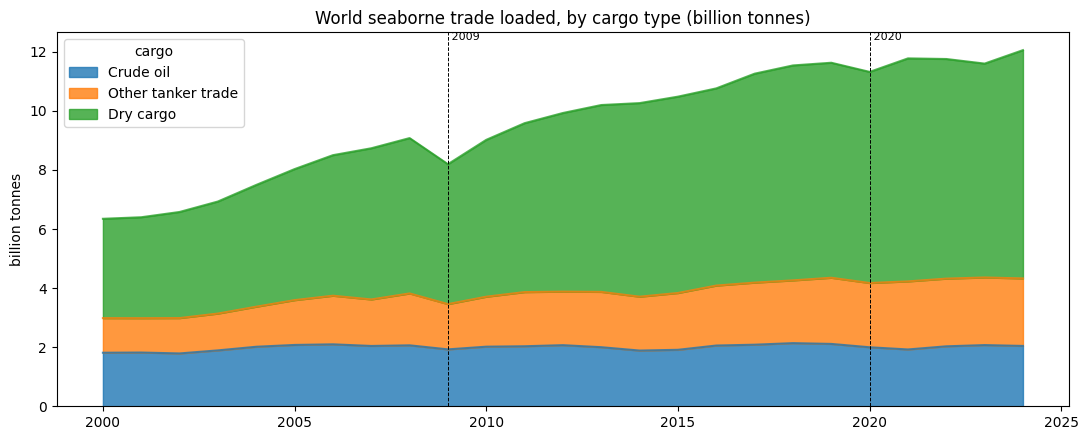

In [229]:
# World seaborne trade by cargo type
fig, ax = plt.subplots(figsize=(11, 4.5))
(world[["Crude oil", "Other tanker trade", "Dry cargo"]] / 1e3).plot.area(ax=ax, alpha=.8)
ax.set_title("World seaborne trade loaded, by cargo type (billion tonnes)"); ax.set_xlabel(""); ax.set_ylabel("billion tonnes")
for y in (2009, 2020):
    ax.axvline(y, color="k", ls="--", lw=.7); ax.text(y, ax.get_ylim()[1], f" {y}", va="top", fontsize=8)
plt.tight_layout(); plt.show()

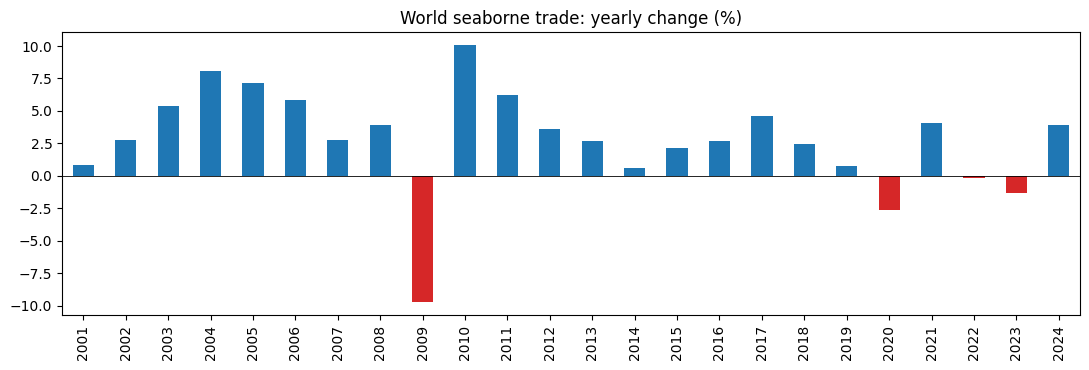

years with a fall: {2009: -9.7, 2020: -2.7, 2022: -0.2, 2023: -1.3}


In [230]:
# Year-on-year growth: when did world trade fall?
yoy = world["Total goods"].pct_change() * 100
fig, ax = plt.subplots(figsize=(11, 3.8))
yoy.dropna().plot.bar(ax=ax, color=["tab:red" if v < 0 else "tab:blue" for v in yoy.dropna()])
ax.axhline(0, color="k", lw=.6); ax.set_title("World seaborne trade: yearly change (%)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print("years with a fall:", yoy[yoy < 0].round(1).to_dict())

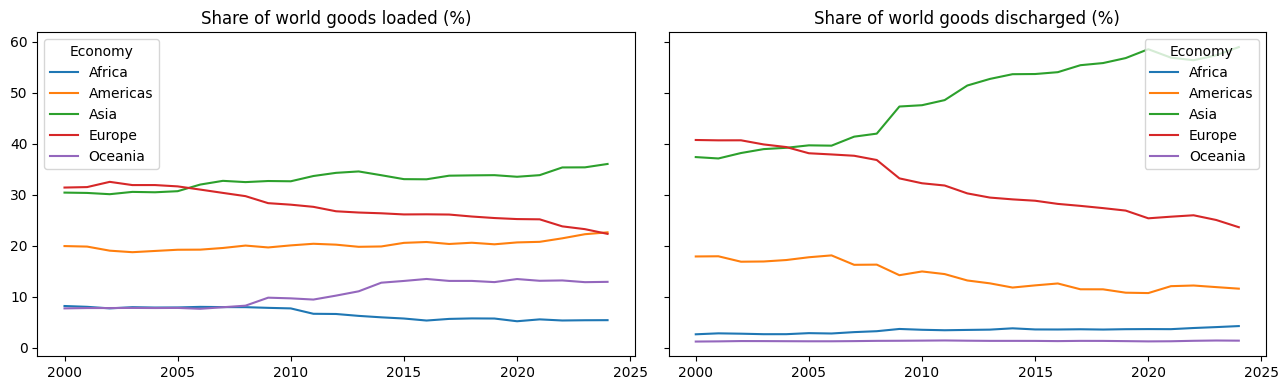

In [231]:
# Continents: who loads and who discharges (shares of the world total)
def share(flow):
    t = sb[(sb.cargo == "Total goods") & (sb.flow == flow) & sb.Economy.isin(CONT + ["World"])].pivot(index="Year", columns="Economy", values="Mt")
    return t[CONT].div(t["World"], axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
share("loaded").plot(ax=axes[0]); axes[0].set_title("Share of world goods loaded (%)")
share("discharged").plot(ax=axes[1]); axes[1].set_title("Share of world goods discharged (%)")
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()

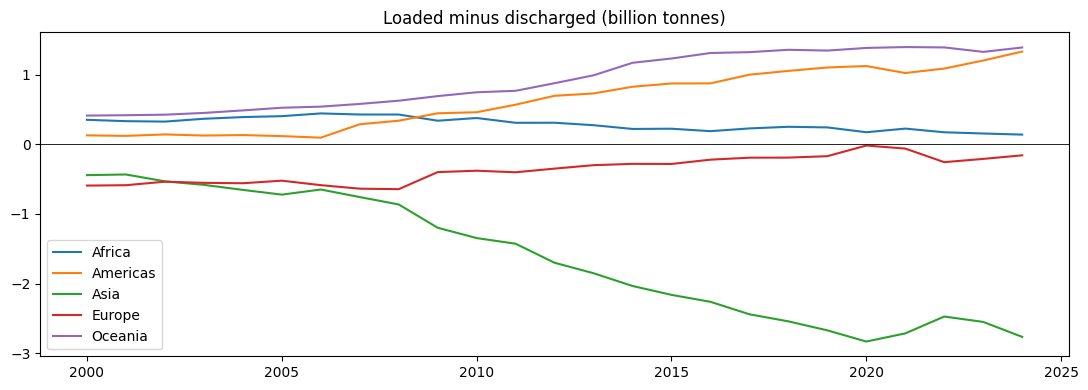

      Africa  Americas  Asia  Europe  Oceania
Year                                         
2000    0.35      0.13 -0.44   -0.59     0.41
2010    0.38      0.46 -1.35   -0.38     0.75
2020    0.17      1.13 -2.83   -0.02     1.38
2024    0.14      1.33 -2.77   -0.16     1.39


In [232]:
# Net position: loaded minus discharged (above 0 = net exporter of seaborne cargo)
net = sb[(sb.cargo == "Total goods") & sb.Economy.isin(CONT)].pivot_table(index="Year", columns=["Economy", "flow"], values="Mt")
net_pos = pd.DataFrame({c: net[(c, "loaded")] - net[(c, "discharged")] for c in CONT}) / 1e3
fig, ax = plt.subplots(figsize=(11, 4)); net_pos.plot(ax=ax)
ax.axhline(0, color="k", lw=.6); ax.set_title("Loaded minus discharged (billion tonnes)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(net_pos.loc[[2000, 2010, 2020, 2024]].round(2).to_string())

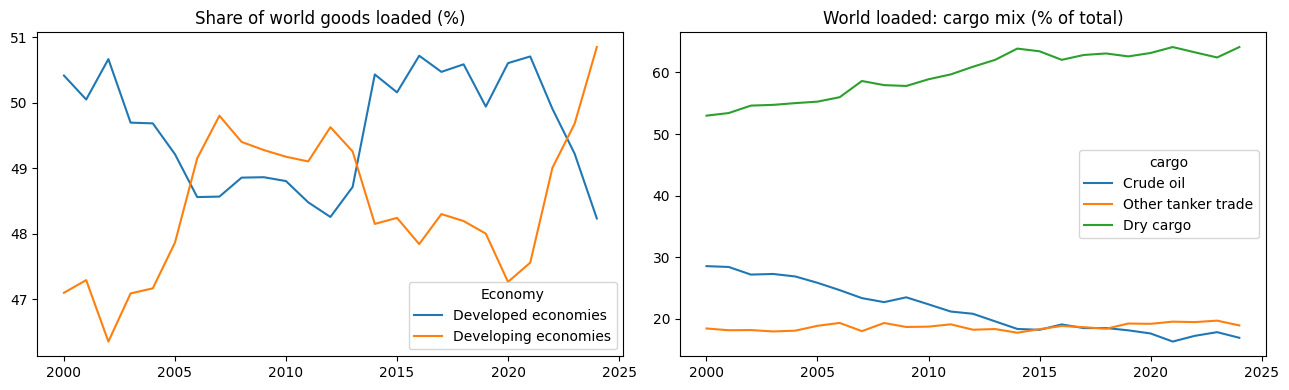

In [233]:
# Developed vs developing economies, and the cargo mix
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
g = sb[(sb.cargo == "Total goods") & (sb.flow == "loaded") & sb.Economy.isin(["Developed economies", "Developing economies", "World"])].pivot(index="Year", columns="Economy", values="Mt")
(g[["Developed economies", "Developing economies"]].div(g["World"], axis=0) * 100).plot(ax=axes[0]); axes[0].set_title("Share of world goods loaded (%)")
mix = world[["Crude oil", "Other tanker trade", "Dry cargo"]].div(world["Total goods"], axis=0) * 100
mix.plot(ax=axes[1]); axes[1].set_title("World loaded: cargo mix (% of total)")
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()

In [234]:
# Average yearly growth 2010 to 2024 (%), by continent and cargo type
rows = {}
for cargo in ["Crude oil", "Other tanker trade", "Dry cargo", "Total goods"]:
    p = sb[(sb.flow == "loaded") & (sb.cargo == cargo) & sb.Economy.isin(CONT)].pivot(index="Year", columns="Economy", values="Mt")
    rows[cargo] = ((p.loc[2024] / p.loc[2010]) ** (1 / 14) - 1) * 100
print(pd.DataFrame(rows).round(1).to_string())

          Crude oil  Other tanker trade  Dry cargo  Total goods
Economy                                                        
Africa         -3.7                -0.6        3.9         -0.5
Americas        4.4                 4.9        2.3          3.0
Asia            0.3                 3.8        3.7          2.8
Europe         -0.7                -0.2        1.0          0.4
Oceania        -4.2                 9.0        4.1          4.2


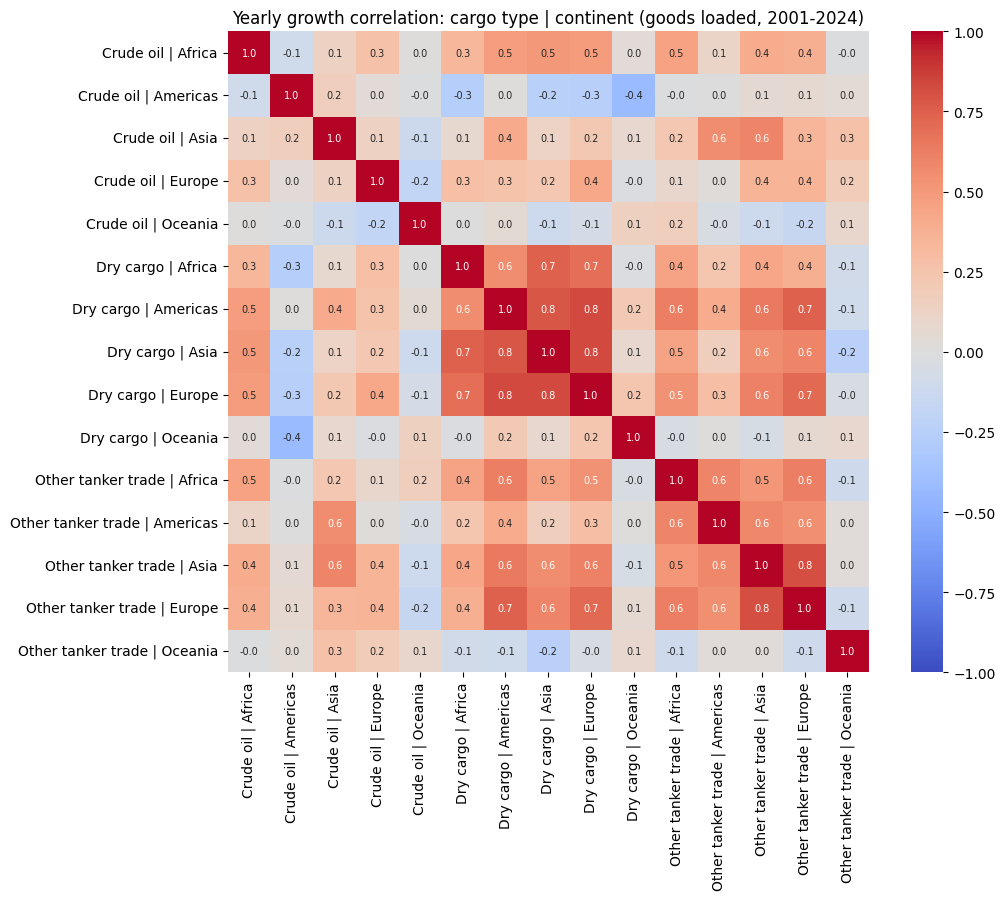

In [235]:
# Correlation heatmap: yearly growth of goods loaded, cargo type x continent
CARGO = ["Crude oil", "Other tanker trade", "Dry cargo"]
cc = (sb[(sb.flow == "loaded") & sb.cargo.isin(CARGO) & sb.Economy.isin(CONT)]
      .pivot_table(index="Year", columns=["cargo", "Economy"], values="Mt"))
cc.columns = [f"{c} | {e}" for c, e in cc.columns]
gcc = cc.pct_change().dropna() * 100

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(gcc.corr(), annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax, annot_kws={"size": 7})
ax.set_title("Yearly growth correlation: cargo type | continent (goods loaded, 2001-2024)")
plt.tight_layout(); plt.show()

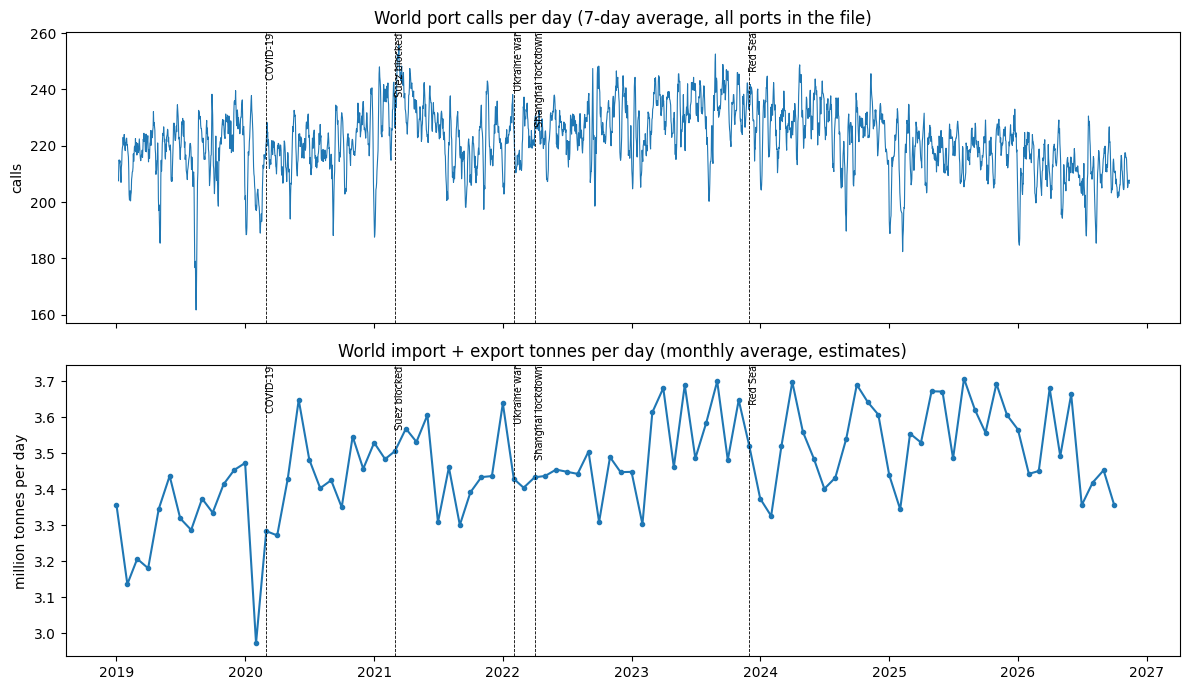

complete months: 94 | 2019-01 to 2026-10
calls per day  - highest: 2021-03 243 | lowest: 2020-02 206
      calls_per_day  tonnes_per_day  months  calls_change_%  tonnes_change_%
date                                                                        
2019          218.2             3.3      12             NaN              NaN
2020          217.7             3.4      12            -0.3              2.3
2021          226.1             3.5      12             3.9              2.0
2022          225.8             3.5      12            -0.1             -0.3
2023          231.2             3.6      12             2.4              2.8
2024          227.0             3.5      12            -1.8             -0.8
2025          217.6             3.6      12            -4.1              1.4
2026          211.1             3.5      10            -3.0             -2.4


In [236]:
# IMF Portwatch
# IMF PortWatch: world activity over time
pw = portwatch_clean
daily = pw.groupby("date").agg(calls=("portcalls", "sum"), imp=("import", "sum"), exp=("export", "sum"))
daily["tonnes_Mt"] = (daily.imp + daily.exp) / 1e6                   # million tonnes (modelled estimates)

monthly = daily.resample("MS").agg(calls=("calls", "sum"), tonnes_Mt=("tonnes_Mt", "sum"), days=("calls", "size"))
monthly = monthly[monthly.days == monthly.index.days_in_month]        # drop the incomplete last month
monthly["calls_per_day"] = monthly.calls / monthly.days
monthly["tonnes_per_day"] = monthly.tonnes_Mt / monthly.days

EVENTS = {"2020-03": "COVID-19", "2021-03": "Suez blocked", "2022-02": "Ukraine war", "2022-04": "Shanghai lockdown", "2023-12": "Red Sea"}
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(daily.index, daily.calls.rolling(7).mean(), lw=.8)
axes[0].set_title("World port calls per day (7-day average, all ports in the file)"); axes[0].set_ylabel("calls")
axes[1].plot(monthly.index, monthly.tonnes_per_day, "o-", ms=3)
axes[1].set_title("World import + export tonnes per day (monthly average, estimates)"); axes[1].set_ylabel("million tonnes per day")
for ax in axes:
    for d, label in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color="k", ls="--", lw=.6)
        ax.text(pd.Timestamp(d), ax.get_ylim()[1], " " + label, rotation=90, va="top", fontsize=7)
plt.tight_layout(); plt.show()

print("complete months:", len(monthly), "|", monthly.index.min().strftime("%Y-%m"), "to", monthly.index.max().strftime("%Y-%m"))
print("calls per day  - highest:", monthly.calls_per_day.idxmax().strftime("%Y-%m"), round(monthly.calls_per_day.max()),
      "| lowest:", monthly.calls_per_day.idxmin().strftime("%Y-%m"), round(monthly.calls_per_day.min()))
yearly = monthly.groupby(monthly.index.year).agg(calls_per_day=("calls_per_day", "mean"), tonnes_per_day=("tonnes_per_day", "mean"), months=("calls", "size"))
yearly["calls_change_%"] = yearly.calls_per_day.pct_change() * 100
yearly["tonnes_change_%"] = yearly.tonnes_per_day.pct_change() * 100
print(yearly.round(1))

In [237]:
# IMF Portwatch
# one monthly table per port
TYPES = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]
cols = ["portid", "date", "portcalls", "import", "export"] + [f"portcalls_{t}" for t in TYPES] + [f"import_{t}" for t in TYPES] + [f"export_{t}" for t in TYPES]
d = portwatch_clean[cols].copy()
d["active"] = (d.portcalls > 0).astype("int8"); d["days"] = 1
d["year"], d["month"] = d.date.dt.year, d.date.dt.month
agg = {"calls": ("portcalls", "sum"), "imp": ("import", "sum"), "exp": ("export", "sum"), "days": ("days", "sum"), "active": ("active", "sum")}
for t in TYPES:
    agg[f"calls_{t}"] = (f"portcalls_{t}", "sum"); agg[f"imp_{t}"] = (f"import_{t}", "sum"); agg[f"exp_{t}"] = (f"export_{t}", "sum")
pm = d.groupby(["portid", "year", "month"]).agg(**agg).reset_index()
del d
pm["date"] = pd.to_datetime(dict(year=pm.year, month=pm.month, day=1)); pm["dim"] = pm.date.dt.days_in_month
n0 = len(pm); pm = pm[pm.days == pm.dim].copy()                                   # keep complete months only
pm["tonnes"] = pm.imp + pm.exp
meta = portwatch_clean.drop_duplicates("portid")[["portid", "portname", "country", "ISO3"]]
pm = pm.merge(meta, on="portid", how="left")
yrs = pm.groupby("year").month.nunique(); LASTY = int(yrs[yrs == 12].index.max())          # last full calendar year
print(f"port-months: {n0} -> {len(pm)} complete | ports: {pm.portid.nunique()} | {pm.date.min():%Y-%m} to {pm.date.max():%Y-%m} | last full year: {LASTY}")

port-months: 3863 -> 3816 complete | ports: 42 | 2019-01 to 2026-10 | last full year: 2025


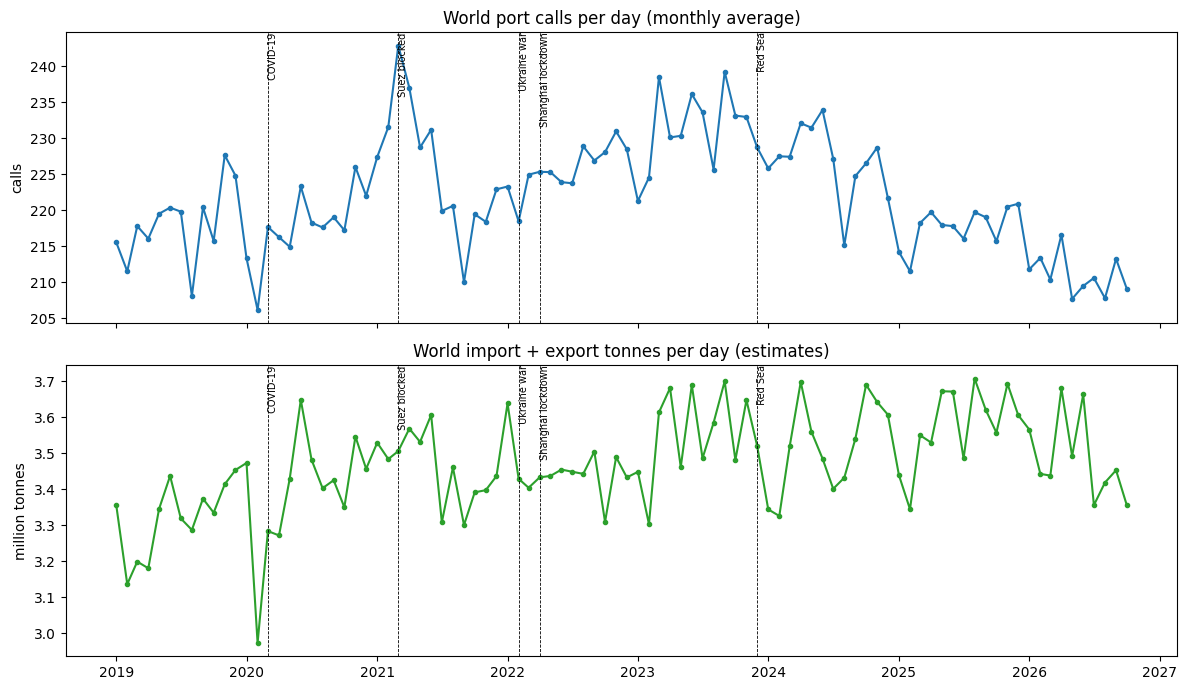

     calls_per_day  tonnes_Mt_per_day
min          206.2                3.0
max          242.8                3.7
lowest month: 2020-02 | highest: 2021-03


In [238]:
# World activity over time
wm = pm.groupby("date").agg(calls=("calls", "sum"), tonnes=("tonnes", "sum"), dim=("dim", "first"))
wm["calls_per_day"], wm["tonnes_Mt_per_day"] = wm.calls / wm.dim, wm.tonnes / wm.dim / 1e6
EVENTS = {"2020-03": "COVID-19", "2021-03": "Suez blocked", "2022-02": "Ukraine war", "2022-04": "Shanghai lockdown", "2023-12": "Red Sea"}
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(wm.index, wm.calls_per_day, "o-", ms=3); axes[0].set_title("World port calls per day (monthly average)"); axes[0].set_ylabel("calls")
axes[1].plot(wm.index, wm.tonnes_Mt_per_day, "o-", ms=3, color="tab:green"); axes[1].set_title("World import + export tonnes per day (estimates)"); axes[1].set_ylabel("million tonnes")
for ax in axes:
    for dt, label in EVENTS.items():
        ax.axvline(pd.Timestamp(dt), color="k", ls="--", lw=.6); ax.text(pd.Timestamp(dt), ax.get_ylim()[1], " " + label, rotation=90, va="top", fontsize=7)
plt.tight_layout(); plt.show()
print(wm[["calls_per_day", "tonnes_Mt_per_day"]].agg(["min", "max"]).round(1)); print("lowest month:", wm.calls_per_day.idxmin().strftime("%Y-%m"), "| highest:", wm.calls_per_day.idxmax().strftime("%Y-%m"))

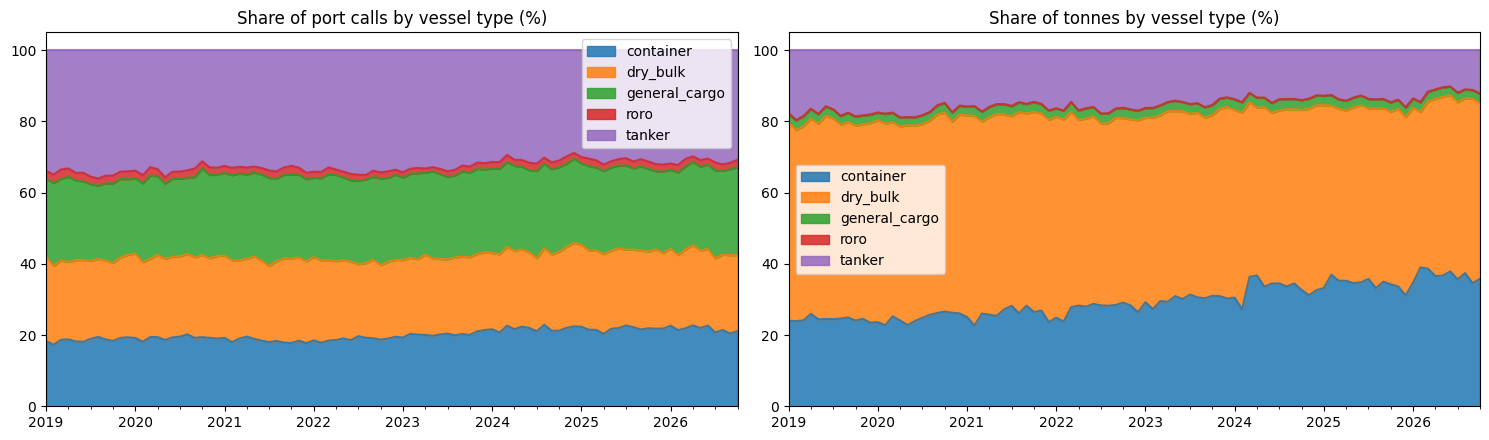

               calls %  tonnes %
container         21.8      34.4
dry_bulk          22.0      49.1
general_cargo     23.2       2.6
roro               2.0       0.1
tanker            31.1      13.8


In [239]:
# Which vessel types make the activity? (share of calls and of tonnes)
cm = pm.groupby("date")[[f"calls_{t}" for t in TYPES]].sum(); cm.columns = TYPES
tm = pd.DataFrame({t: pm.groupby("date")[f"imp_{t}"].sum() + pm.groupby("date")[f"exp_{t}"].sum() for t in TYPES})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
(cm.div(cm.sum(axis=1), axis=0) * 100).plot.area(ax=axes[0], alpha=.85); axes[0].set_title("Share of port calls by vessel type (%)"); axes[0].set_xlabel("")
(tm.div(tm.sum(axis=1), axis=0) * 100).plot.area(ax=axes[1], alpha=.85); axes[1].set_title("Share of tonnes by vessel type (%)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"calls %": cm.loc[cm.index.year == LASTY].sum() / cm.loc[cm.index.year == LASTY].sum().sum() * 100, "tonnes %": tm.loc[tm.index.year == LASTY].sum() / tm.loc[tm.index.year == LASTY].sum().sum() * 100}).round(1))

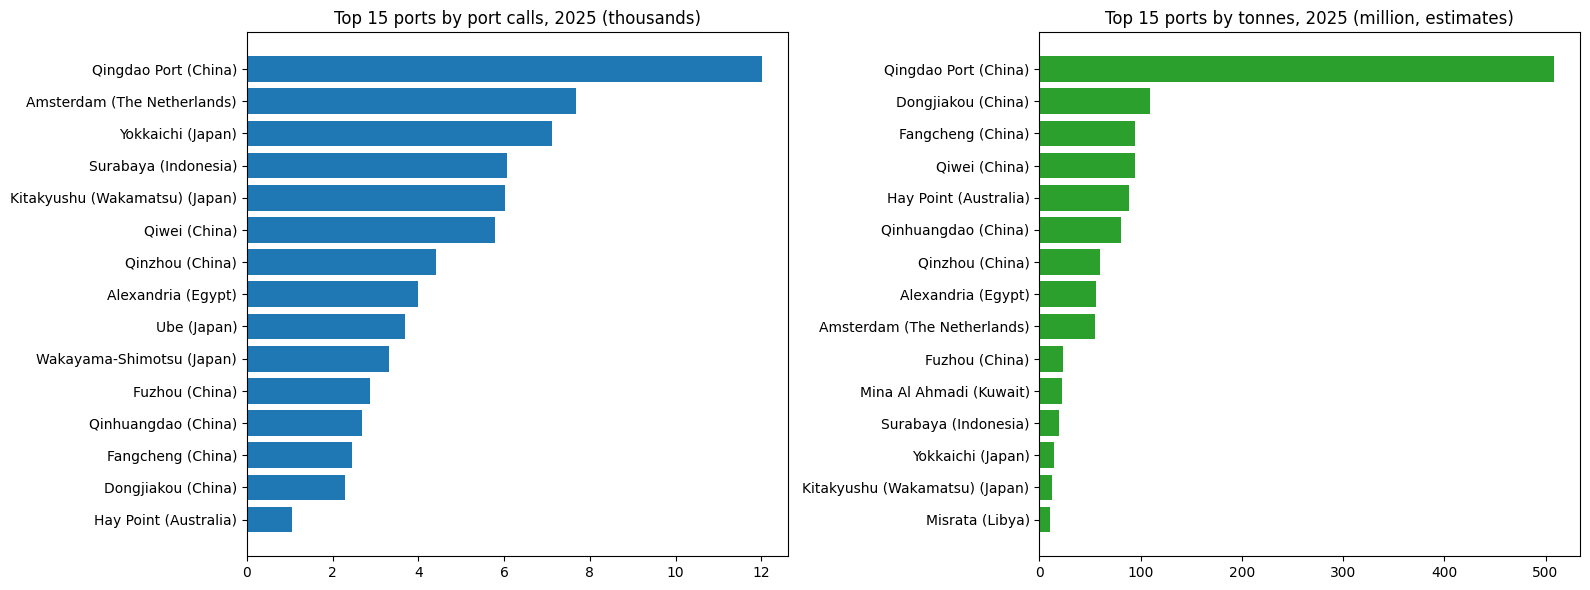

top 15 ports = 89.9% of calls and 95.9% of tonnes


In [240]:
# Busiest ports in the last full year (calls and tonnes)
py = pm[pm.year == LASTY].groupby(["portid", "portname", "country"]).agg(calls=("calls", "sum"), tonnes=("tonnes", "sum")).reset_index()
py["label"] = py.portname + " (" + py.country + ")"
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
a = py.nlargest(15, "calls").iloc[::-1]; axes[0].barh(a.label, a.calls / 1e3, color="tab:blue"); axes[0].set_title(f"Top 15 ports by port calls, {LASTY} (thousands)")
b = py.nlargest(15, "tonnes").iloc[::-1]; axes[1].barh(b.label, b.tonnes / 1e6, color="tab:green"); axes[1].set_title(f"Top 15 ports by tonnes, {LASTY} (million, estimates)")
plt.tight_layout(); plt.show()
print(f"top 15 ports = {py.nlargest(15, 'calls').calls.sum() / py.calls.sum():.1%} of calls and {py.nlargest(15, 'tonnes').tonnes.sum() / py.tonnes.sum():.1%} of tonnes")

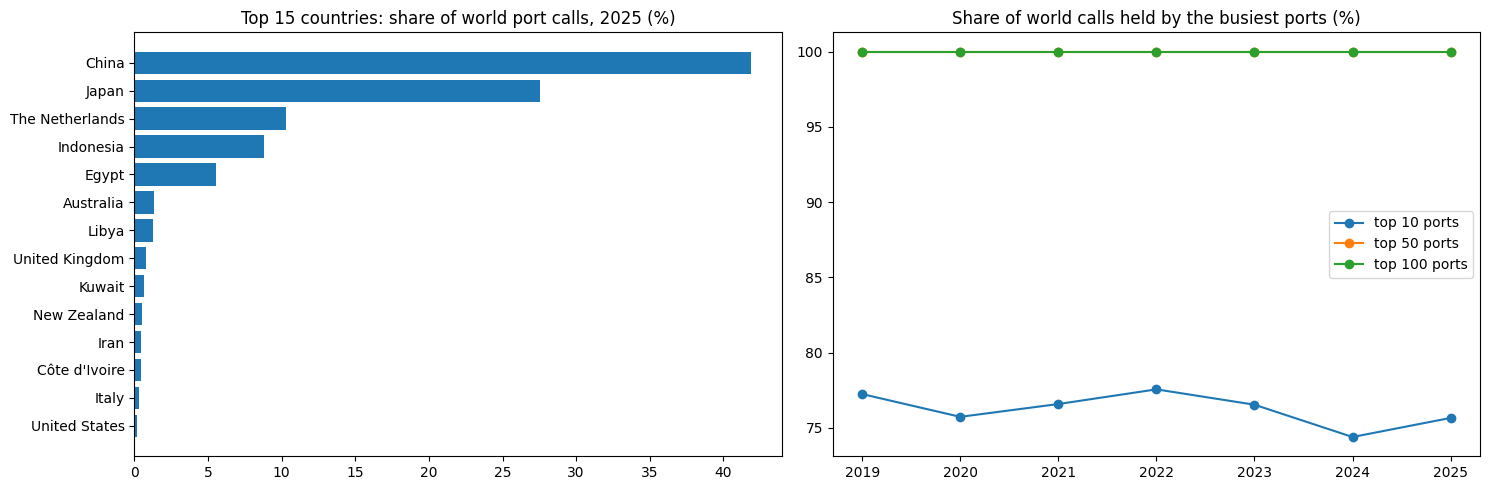

      top 10 ports  top 50 ports  top 100 ports
year                                           
2019          77.3         100.0          100.0
2020          75.7         100.0          100.0
2021          76.6         100.0          100.0
2022          77.6         100.0          100.0
2023          76.5         100.0          100.0
2024          74.4         100.0          100.0
2025          75.7         100.0          100.0


In [241]:
# Countries and concentration
cy = pm[pm.year == LASTY].groupby("country").agg(calls=("calls", "sum"), tonnes=("tonnes", "sum"), ports=("portid", "nunique")).sort_values("calls", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
t15 = cy.head(15).iloc[::-1]; axes[0].barh(t15.index, t15.calls / cy.calls.sum() * 100); axes[0].set_title(f"Top 15 countries: share of world port calls, {LASTY} (%)")
pc = pm.groupby(["year", "portid"]).calls.sum().reset_index()
conc = pd.DataFrame({f"top {k} ports": pc.groupby("year").calls.apply(lambda s, k=k: s.nlargest(k).sum() / s.sum() * 100) for k in (10, 50, 100)})
conc = conc[conc.index <= LASTY]; conc.plot(ax=axes[1], marker="o"); axes[1].set_title("Share of world calls held by the busiest ports (%)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show(); print(conc.round(1))

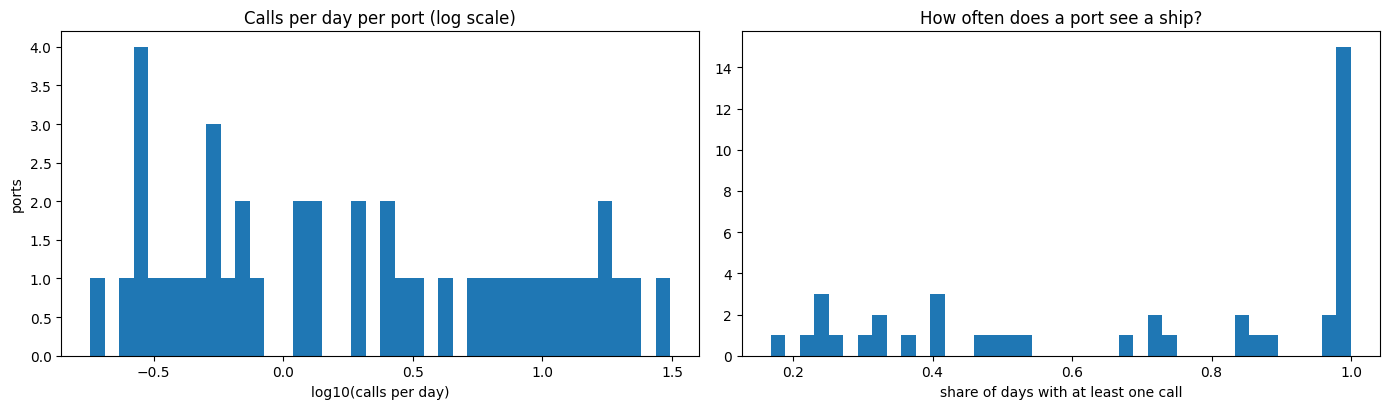

ports: 42 | with no calls at all: 0 | calls on under 25% of days: 4 | calls every day: 11
count    42.00
mean      5.40
std       7.42
min       0.18
25%       0.51
50%       1.67
75%       8.12
max      31.16
Name: calls_per_day, dtype: float64


In [242]:
# How active are the ports? (many are nearly idle)
pa = pm.groupby("portid").agg(calls=("calls", "sum"), days=("days", "sum"), active=("active", "sum"))
pa["calls_per_day"], pa["active_share"] = pa.calls / pa.days, pa.active / pa.days
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].hist(np.log10(pa.calls_per_day[pa.calls_per_day > 0]), bins=40); axes[0].set_xlabel("log10(calls per day)"); axes[0].set_ylabel("ports"); axes[0].set_title("Calls per day per port (log scale)")
axes[1].hist(pa.active_share, bins=40); axes[1].set_xlabel("share of days with at least one call"); axes[1].set_title("How often does a port see a ship?")
plt.tight_layout(); plt.show()
print(f"ports: {len(pa)} | with no calls at all: {(pa.calls == 0).sum()} | calls on under 25% of days: {(pa.active_share < .25).sum()} | calls every day: {(pa.active_share > .99).sum()}")
print(pa.calls_per_day.describe().round(2))

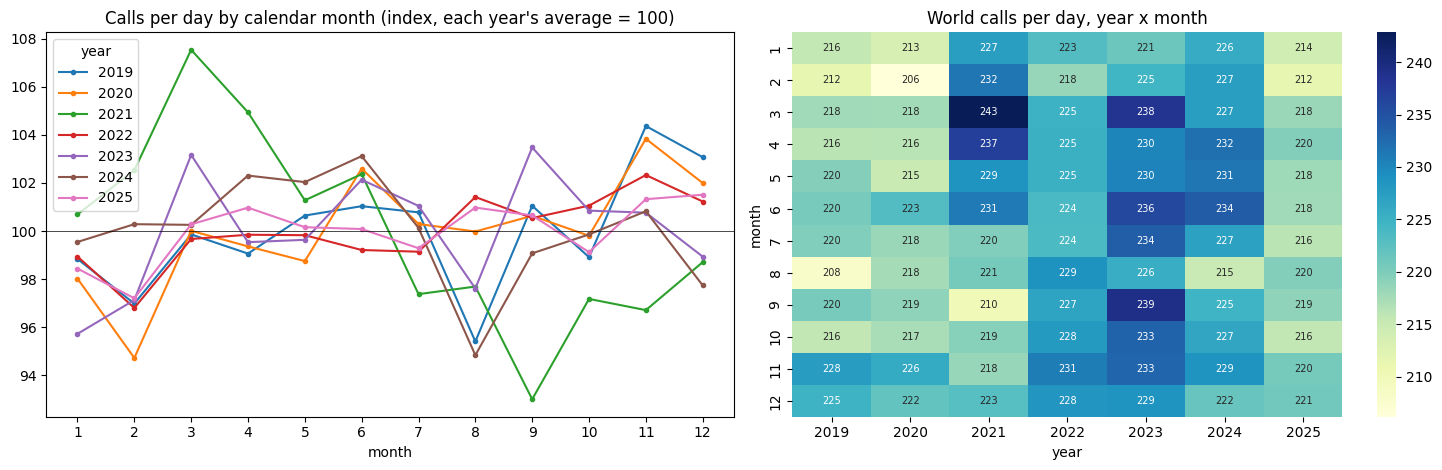

typical seasonal swing (max - min of the monthly index, per year):
{2019: 9.0, 2020: 9.1, 2021: 14.5, 2022: 5.5, 2023: 7.7, 2024: 8.3, 2025: 4.3}


In [243]:
# Seasonality: is there a yearly pattern?
x = wm.assign(year=wm.index.year, month=wm.index.month); x = x[x.year <= LASTY]
piv = x.pivot(index="month", columns="year", values="calls_per_day")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
(piv / piv.mean() * 100).plot(ax=axes[0], marker="o", ms=3); axes[0].set_title("Calls per day by calendar month (index, each year's average = 100)"); axes[0].set_xticks(range(1, 13)); axes[0].axhline(100, color="k", lw=.5)
sns.heatmap(piv, cmap="YlGnBu", annot=True, fmt=".0f", annot_kws={"size": 7}, ax=axes[1]); axes[1].set_title("World calls per day, year x month")
plt.tight_layout(); plt.show()
idx = (piv / piv.mean() * 100); print("typical seasonal swing (max - min of the monthly index, per year):"); print((idx.max() - idx.min()).round(1).to_dict())

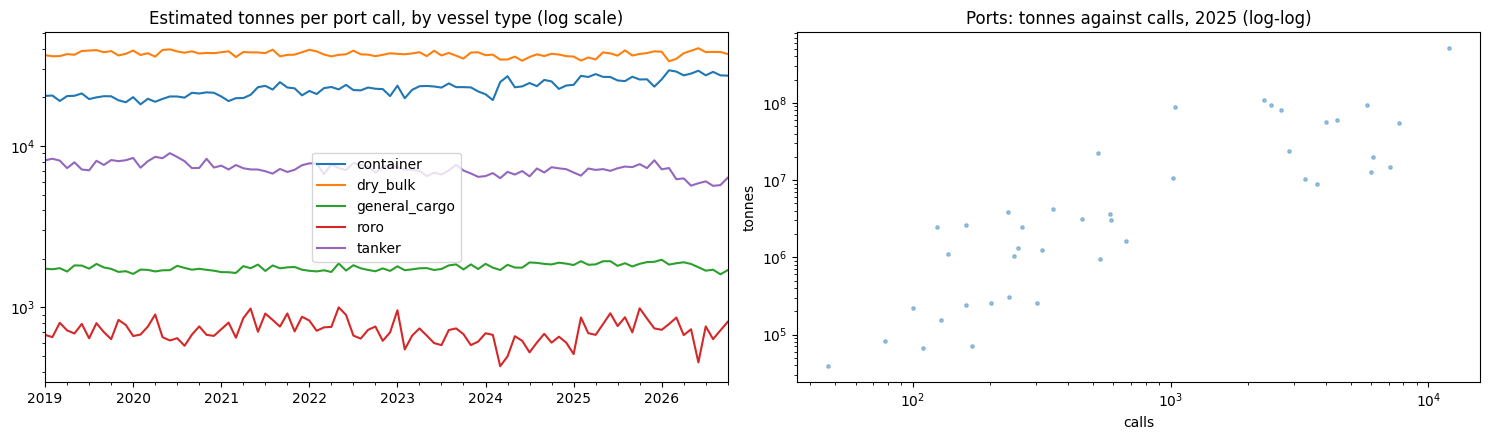

tonnes per call, last full year: {'container': 25956.0, 'dry_bulk': 36610.0, 'general_cargo': 1872.0, 'roro': 781.0, 'tanker': 7264.0}
correlation of log calls and log tonnes across ports: 0.87


In [244]:
# Tonnes per call by vessel type
tpc = pd.DataFrame({t: tm[t] / cm[t].replace(0, np.nan) for t in TYPES})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
tpc.plot(ax=axes[0], logy=True); axes[0].set_title("Estimated tonnes per port call, by vessel type (log scale)"); axes[0].set_xlabel("")
sizes = pm[pm.year == LASTY].groupby("portid").agg(calls=("calls", "sum"), tonnes=("tonnes", "sum")); sizes = sizes[(sizes.calls > 0)]
axes[1].scatter(sizes.calls, sizes.tonnes, s=6, alpha=.4); axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("calls"); axes[1].set_ylabel("tonnes")
axes[1].set_title(f"Ports: tonnes against calls, {LASTY} (log-log)")
plt.tight_layout(); plt.show()
print("tonnes per call, last full year:", tpc[tpc.index.year == LASTY].mean().round(0).to_dict())
print("correlation of log calls and log tonnes across ports:", round(float(np.log10(sizes.calls).corr(np.log10(sizes.tonnes.replace(0, np.nan)))), 2))

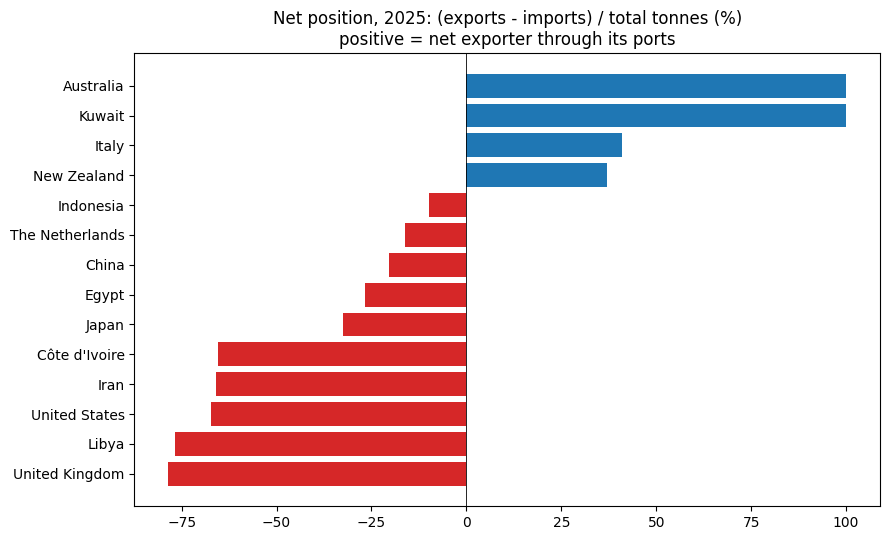

In [245]:
#%% PW 9. Exporters and importers: net position of the 15 largest countries by tonnes
cb = pm[pm.year == LASTY].groupby("country").agg(imp=("imp", "sum"), exp=("exp", "sum")); cb["tonnes"] = cb.imp + cb.exp
cb = cb.nlargest(15, "tonnes"); cb["net_export_share"] = (cb.exp - cb.imp) / cb.tonnes * 100
fig, ax = plt.subplots(figsize=(9, 5.5)); s = cb.net_export_share.sort_values()
ax.barh(s.index, s.values, color=["tab:red" if v < 0 else "tab:blue" for v in s]); ax.axvline(0, color="k", lw=.6)
ax.set_title(f"Net position, {LASTY}: (exports - imports) / total tonnes (%)\npositive = net exporter through its ports")
plt.tight_layout(); plt.show()

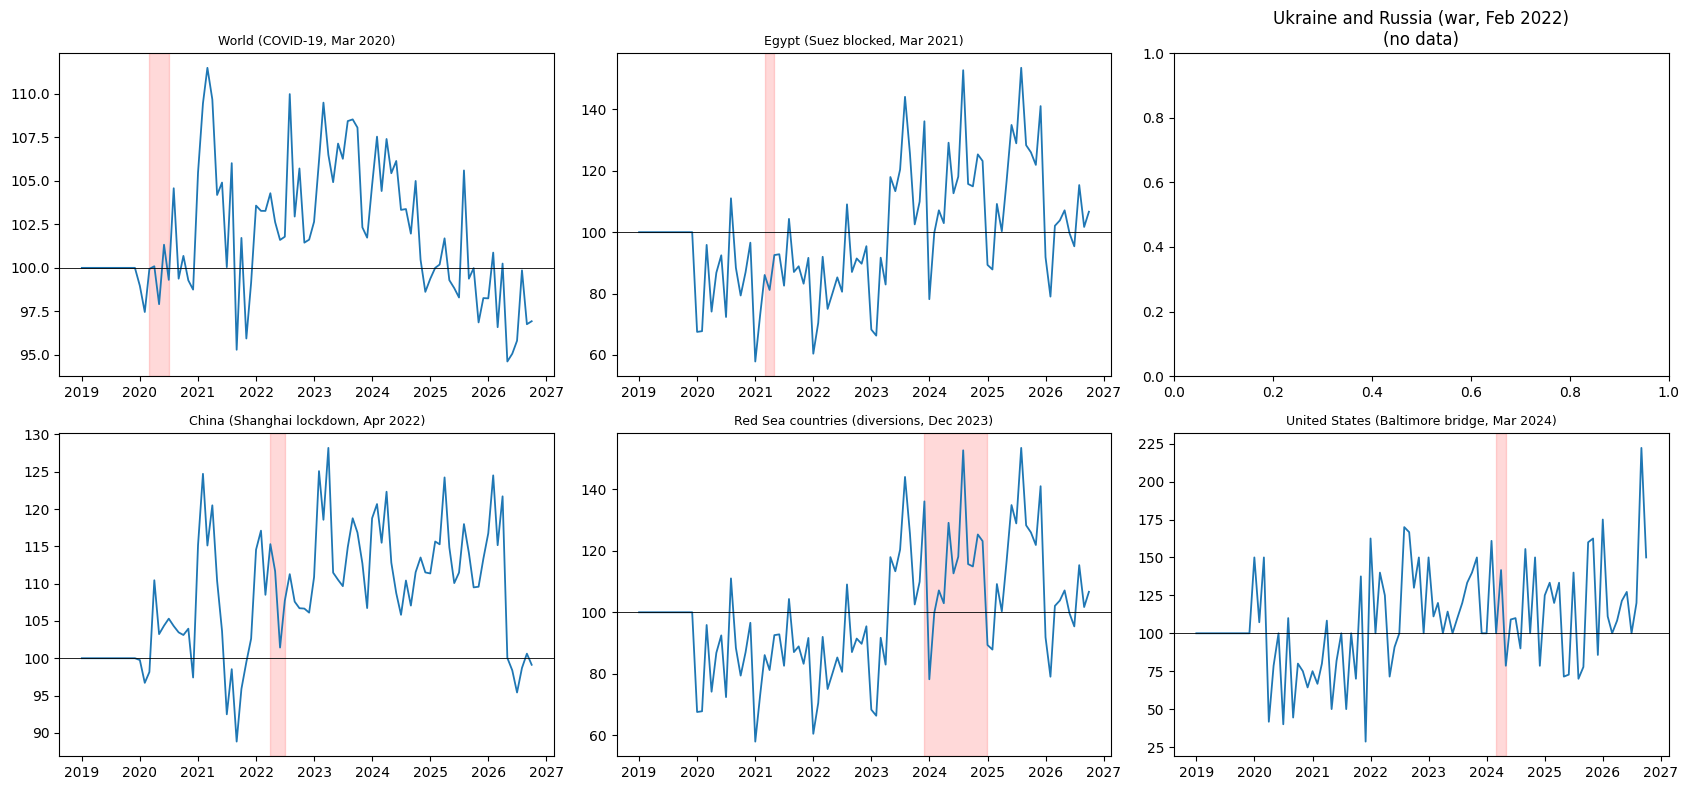

,lowest index in window,month,months below 90 after start
case,,,
"World (COVID-19, Mar 2020)",97.9,2020-05,0
"Egypt (Suez blocked, Mar 2021)",81.2,2021-04,21
"China (Shanghai lockdown, Apr 2022)",101.4,2022-06,0
"Red Sea countries (diversions, Dec 2023)",78.2,2024-01,4
"United States (Baltimore bridge, Mar 2024)",100.0,2024-03,7


In [246]:
# Disruptions: calls per day against the same month of 2019 (2019 = 100)
RED = ["EGY", "YEM", "SAU", "DJI", "JOR", "ERI"]
CASES = [("World (COVID-19, Mar 2020)", None, "2020-03", "2020-06"), ("Egypt (Suez blocked, Mar 2021)", ["EGY"], "2021-03", "2021-04"),
         ("Ukraine and Russia (war, Feb 2022)", ["UKR", "RUS"], "2022-02", "2022-06"), ("China (Shanghai lockdown, Apr 2022)", ["CHN"], "2022-04", "2022-06"),
         ("Red Sea countries (diversions, Dec 2023)", RED, "2023-12", "2024-12"), ("United States (Baltimore bridge, Mar 2024)", ["USA"], "2024-03", "2024-04")]
fig, axes = plt.subplots(2, 3, figsize=(17, 8)); summary = []
for ax, (name, iso, s0, s1) in zip(axes.ravel(), CASES):
    sub = pm if iso is None else pm[pm.ISO3.isin(iso)]
    if sub.empty: ax.set_title(name + "\n(no data)"); continue
    m = sub.groupby("date").agg(calls=("calls", "sum"), dim=("dim", "first")); m["cpd"] = m.calls / m.dim
    base = m[m.index.year == 2019].set_index(m[m.index.year == 2019].index.month).cpd
    m["index"] = [v / base.get(dt.month, np.nan) * 100 for dt, v in m.cpd.items()]
    ax.plot(m.index, m["index"], lw=1.3); ax.axhline(100, color="k", lw=.6); ax.axvspan(pd.Timestamp(s0), pd.Timestamp(s1) + pd.offsets.MonthEnd(0), color="red", alpha=.15); ax.set_title(name, fontsize=9)
    w = m.loc[s0:s1, "index"]; summary.append({"case": name, "lowest index in window": round(float(w.min()), 1), "month": w.idxmin().strftime("%Y-%m"), "months below 90 after start": int((m.loc[s0:, "index"] < 90).sum())})
plt.tight_layout(); plt.show(); display(pd.DataFrame(summary).set_index("case"))

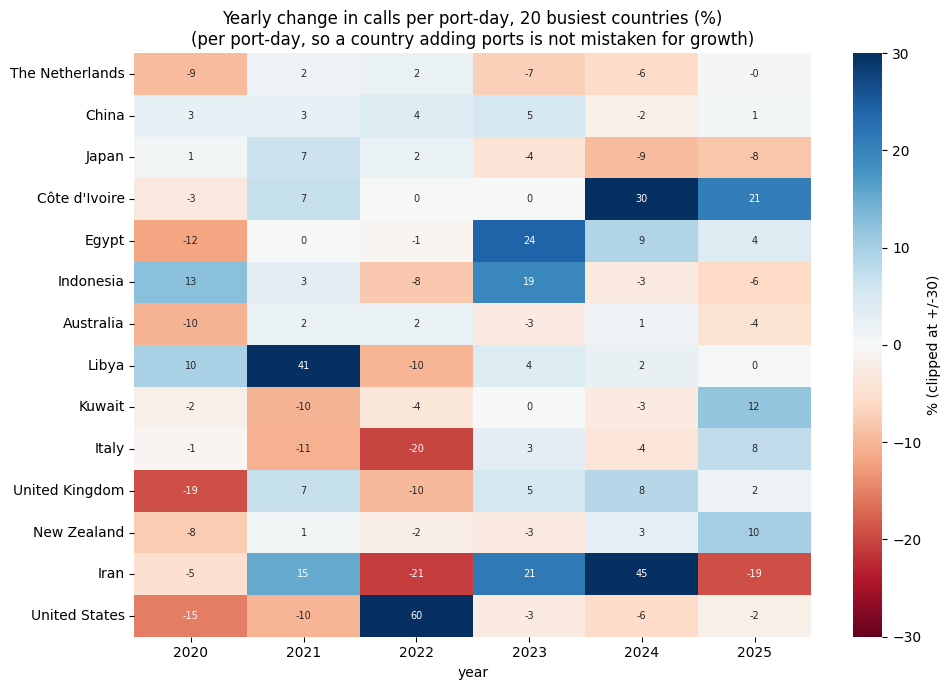

In [247]:
# Heatmap: yearly change in calls per day, 20 busiest countries (full years only)
fy = pm[pm.year <= LASTY].groupby(["country", "year"]).agg(calls=("calls", "sum"), days=("days", "sum")); fy["cpd"] = fy.calls / fy.days
tab = fy.cpd.unstack("year"); top20 = tab[LASTY].nlargest(20).index
gr = tab.loc[top20].pct_change(axis=1).drop(columns=tab.columns.min()) * 100
fig, ax = plt.subplots(figsize=(10, 7)); sns.heatmap(gr, cmap="RdBu", center=0, vmin=-30, vmax=30, annot=True, fmt=".0f", annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "% (clipped at +/-30)"})
ax.set_title("Yearly change in calls per port-day, 20 busiest countries (%)\n(per port-day, so a country adding ports is not mistaken for growth)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Text(0.5, 1.0, 'Without Mar 2020 to Dec 2021')

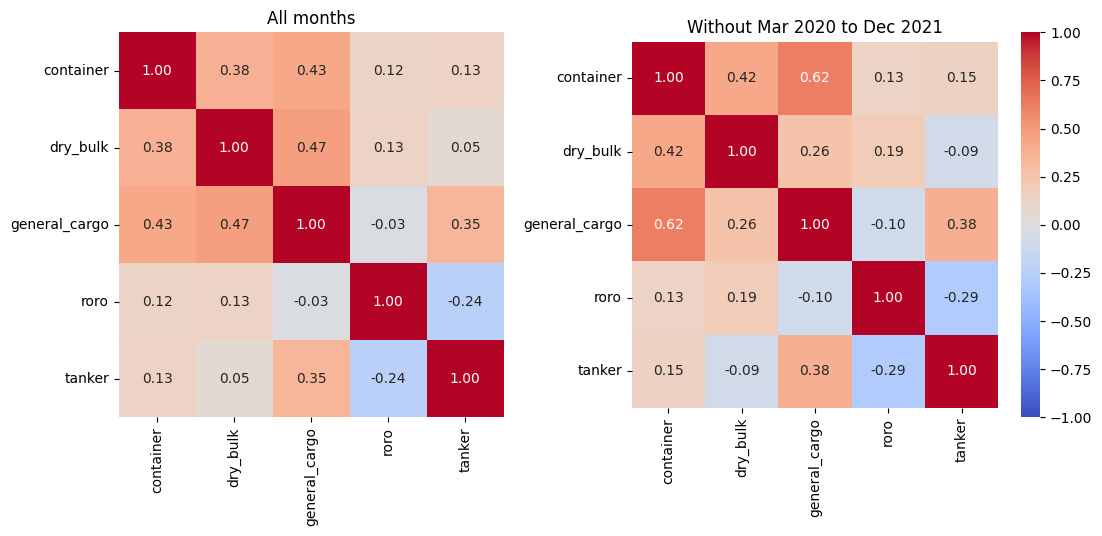

In [248]:
# Do vessel types move together? Correlation of yearly growth by month
gy = cm.pct_change(12).dropna() * 100
calm = gy.drop(gy.loc["2020-03":"2021-12"].index, errors="ignore")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(gy.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[0], cbar=False); axes[0].set_title("All months")
sns.heatmap(calm.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[1]); axes[1].set_title("Without Mar 2020 to Dec 2021")

In [249]:
# Container port throuhout
# TEU: world, countries, groupings
tc = teu_clean[teu_clean.level == "country"].dropna(subset=["TEU"]).copy()
world_teu = teu_clean[teu_clean.level == "world"].set_index("Year").TEU / 1e6          # million TEU
LATEST = int(tc.Year.max())
wide = tc.pivot(index="Year", columns="Economy", values="TEU")                          # years x countries
print("countries:", wide.shape[1], "| years:", wide.index.min(), "-", wide.index.max(), "| latest:", LATEST)

countries: 136 | years: 2010 - 2024 | latest: 2024


In [250]:
# colour palette used by every chart below
NAVY, BLUE, TEAL, SAND, ORANGE, CORAL, PURPLE = "#0B3C5D", "#328CC1", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51", "#8E7DBE"
POS, NEG = TEAL, CORAL                                              # growth up / down
CONT_COLORS = {"Asia": CORAL, "Americas": TEAL, "Europe": BLUE, "Africa": SAND, "Oceania": PURPLE}
sns.set_theme(style="whitegrid", palette=[BLUE, CORAL, TEAL, SAND, PURPLE, NAVY, ORANGE])
plt.rcParams.update({"axes.edgecolor": "#B0B7BF", "grid.color": "#E5E8EB", "axes.titleweight": "bold", "axes.titlesize": 11, "figure.facecolor": "white"})

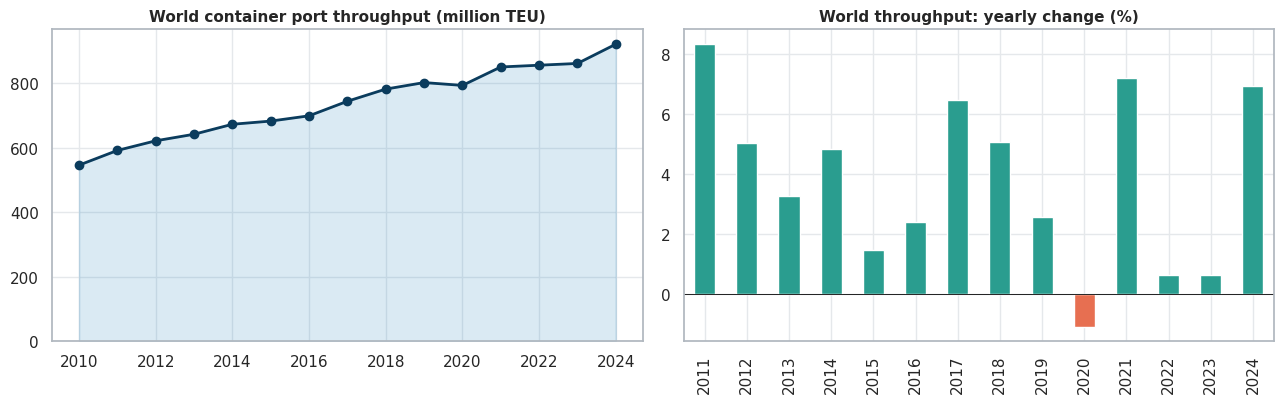

years with a fall: {2020: -1.1} | growth 2010 to 2024 : x 1.69


In [251]:
# World throughput and yearly growth
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].fill_between(world_teu.index, world_teu.values, color=BLUE, alpha=.18); world_teu.plot(ax=axes[0], marker="o", color=NAVY, lw=2); axes[0].set_title("World container port throughput (million TEU)"); axes[0].set_xlabel(""); axes[0].set_ylim(0)
yoy = world_teu.pct_change().dropna() * 100
yoy.plot.bar(ax=axes[1], color=[NEG if v < 0 else POS for v in yoy]); axes[1].axhline(0, color="k", lw=.6)
axes[1].set_title("World throughput: yearly change (%)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
print("years with a fall:", yoy[yoy < 0].round(1).to_dict(), "| growth 2010 to", LATEST, ": x", round(world_teu[LATEST] / world_teu[2010], 2))

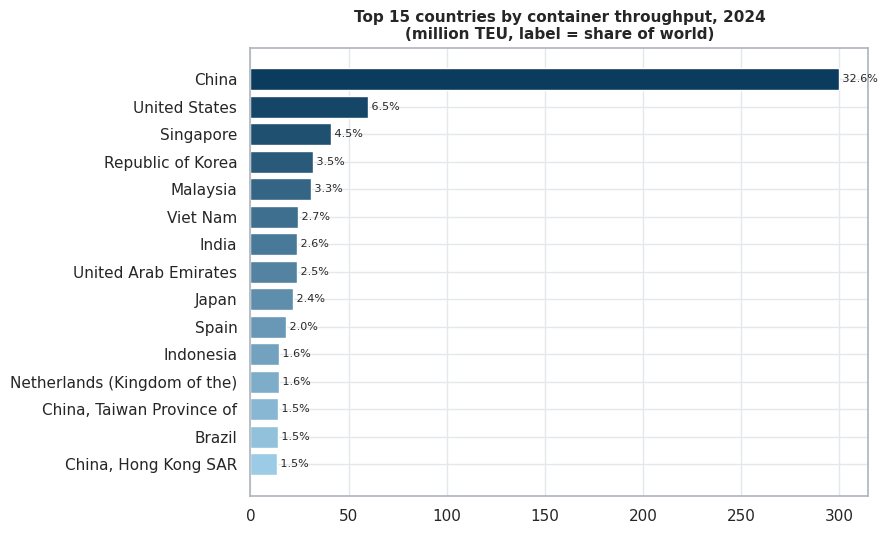

top 15 = 70.1% of world | top 1: China 32.6%


In [252]:
# Top 15 countries in the latest year
top = tc[tc.Year == LATEST].nlargest(15, "TEU")[["Economy", "TEU"]].set_index("Economy").TEU / 1e6
share = top / (world_teu[LATEST]) * 100
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index[::-1], top.values[::-1], color=sns.color_palette("blend:#9CCBE6,#0B3C5D", len(top))[::-1][::-1])
for i, (v, s) in enumerate(zip(top.values[::-1], share.values[::-1])): ax.text(v, i, f" {s:.1f}%", va="center", fontsize=8)
ax.set_title(f"Top 15 countries by container throughput, {LATEST}\n(million TEU, label = share of world)")
plt.tight_layout(); plt.show()
print(f"top 15 = {share.sum():.1f}% of world | top 1: {top.index[0]} {share.iloc[0]:.1f}%")

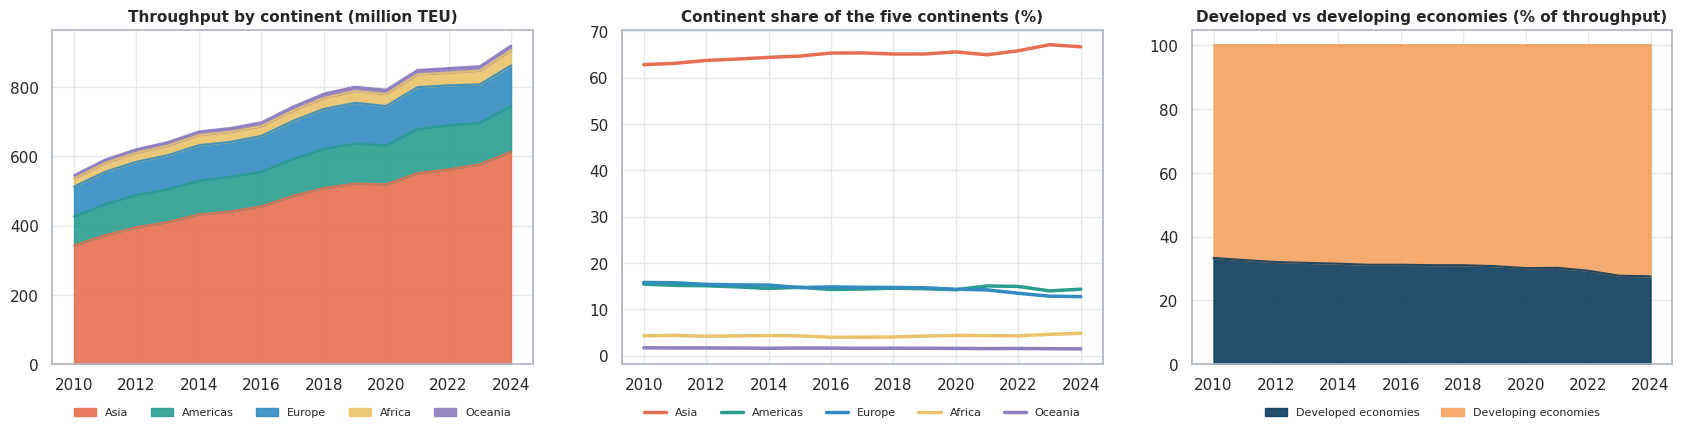

Economy  Asia  Americas  Europe  Africa  Oceania
Year                                            
2010     62.8      15.4    15.8     4.3      1.7
2024     66.6      14.3    12.7     4.8      1.5


In [253]:
# Continents and development status over time
CONT = ["Asia", "Americas", "Europe", "Africa", "Oceania"]
g = teu_clean[teu_clean.level == "grouping"].pivot(index="Year", columns="Economy", values="TEU") / 1e6
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
g[CONT].plot.area(ax=axes[0], alpha=.9, color=[CONT_COLORS[c] for c in CONT]); axes[0].set_title("Throughput by continent (million TEU)"); axes[0].set_xlabel("")
(g[CONT].div(g[CONT].sum(axis=1), axis=0) * 100).plot(ax=axes[1], color=[CONT_COLORS[c] for c in CONT], lw=2.5); axes[1].set_title("Continent share of the five continents (%)"); axes[1].set_xlabel("")
dev = g[["Developed economies", "Developing economies"]]
(dev.div(dev.sum(axis=1), axis=0) * 100).plot.area(ax=axes[2], alpha=.9, color=[NAVY, ORANGE]); axes[2].set_title("Developed vs developing economies (% of throughput)"); axes[2].set_xlabel("")
for ax in axes: ax.legend(loc="upper center", bbox_to_anchor=(.5, -.1), ncol=5, fontsize=8, frameon=False, title="")
plt.tight_layout(); plt.show()
print((g[CONT].loc[[2010, LATEST]].div(g[CONT].loc[[2010, LATEST]].sum(axis=1), axis=0) * 100).round(1))

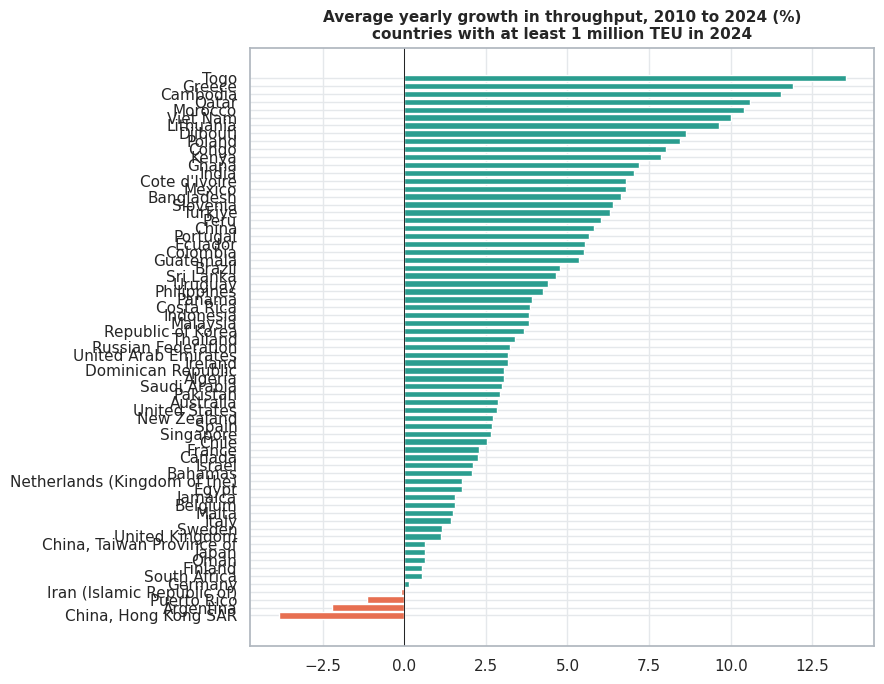

fastest: {'Togo': 13.5, 'Greece': 11.9, 'Cambodia': 11.6, 'Qatar': 10.6, 'Morocco': 10.4}
slowest: {'China, Hong Kong SAR': -3.8, 'Argentina': -2.2, 'Puerto Rico': -1.1, 'Iran (Islamic Republic of)': -0.1, 'Germany': 0.1}


In [254]:
# Who grew: average yearly growth 2010 to latest (countries above 1 million TEU)
first, last = wide.loc[2010], wide.loc[LATEST]
big = last[last >= 1e6].index.intersection(first[first > 0].index)
cagr = ((last[big] / first[big]) ** (1 / (LATEST - 2010)) - 1) * 100
fig, ax = plt.subplots(figsize=(9, 7))
c = cagr.sort_values(); colors = [NEG if v < 0 else POS for v in c]
ax.barh(c.index, c.values, color=colors); ax.axvline(0, color="k", lw=.6)
ax.set_title(f"Average yearly growth in throughput, 2010 to {LATEST} (%)\ncountries with at least 1 million TEU in {LATEST}")
plt.tight_layout(); plt.show()
print("fastest:", cagr.nlargest(5).round(1).to_dict()); print("slowest:", cagr.nsmallest(5).round(1).to_dict())

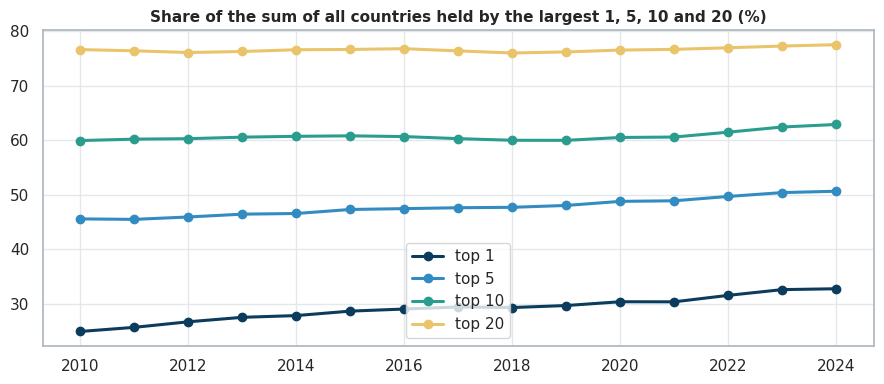

      top 1  top 5  top 10  top 20
Year                              
2010   25.0   45.6    59.9    76.6
2024   32.8   50.7    62.9    77.5


In [255]:
# Concentration: do a few countries dominate?
tcw = tc.groupby("Year").TEU.sum()
conc = pd.DataFrame({f"top {k}": tc.groupby("Year").TEU.apply(lambda s, k=k: s.nlargest(k).sum()) / tcw * 100 for k in (1, 5, 10, 20)})
fig, ax = plt.subplots(figsize=(9, 4)); conc.plot(ax=ax, marker="o", color=[NAVY, BLUE, TEAL, SAND], lw=2.2); ax.set_title("Share of the sum of all countries held by the largest 1, 5, 10 and 20 (%)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(conc.loc[[2010, LATEST]].round(1))

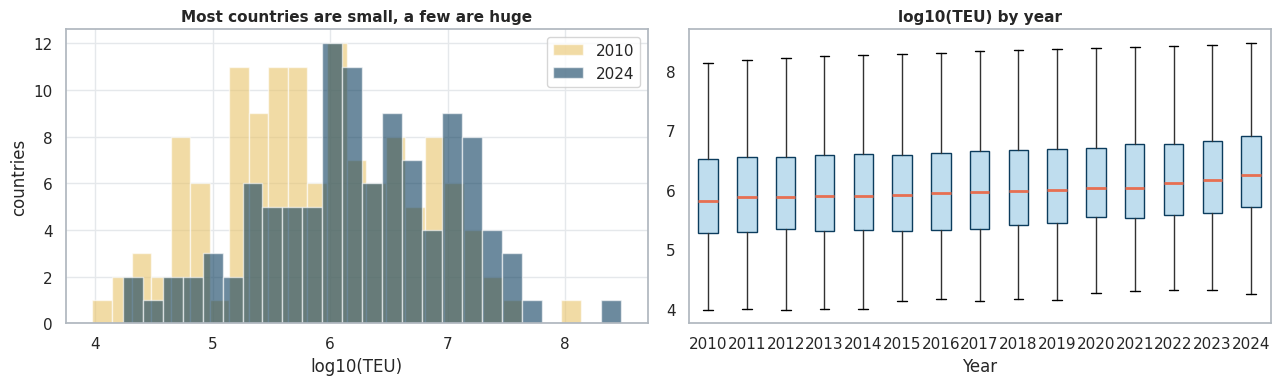

countries by size in 2024: {'< 100k': 9, '100k to 1M': 30, '1M to 10M': 48, '> 10M': 21} | median: 1759720


In [256]:
# Size distribution of countries (log scale)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for y, col in ((2010, SAND), (LATEST, NAVY)):
    axes[0].hist(np.log10(tc[tc.Year == y].TEU), bins=25, alpha=.6, label=str(y), color=col)
axes[0].set_xlabel("log10(TEU)"); axes[0].set_ylabel("countries"); axes[0].legend(); axes[0].set_title("Most countries are small, a few are huge")
tc.assign(logTEU=np.log10(tc.TEU)).boxplot(column="logTEU", by="Year", ax=axes[1], grid=False, patch_artist=True, boxprops=dict(facecolor="#BFDDEE", color=NAVY), medianprops=dict(color=CORAL, lw=2)); axes[1].set_title("log10(TEU) by year"); plt.suptitle("")
plt.tight_layout(); plt.show()
sz = pd.cut(tc[tc.Year == LATEST].TEU, [0, 1e5, 1e6, 1e7, 1e9], labels=["< 100k", "100k to 1M", "1M to 10M", "> 10M"]).value_counts().sort_index()
print(f"countries by size in {LATEST}:", sz.to_dict(), "| median:", round(tc[tc.Year == LATEST].TEU.median()))

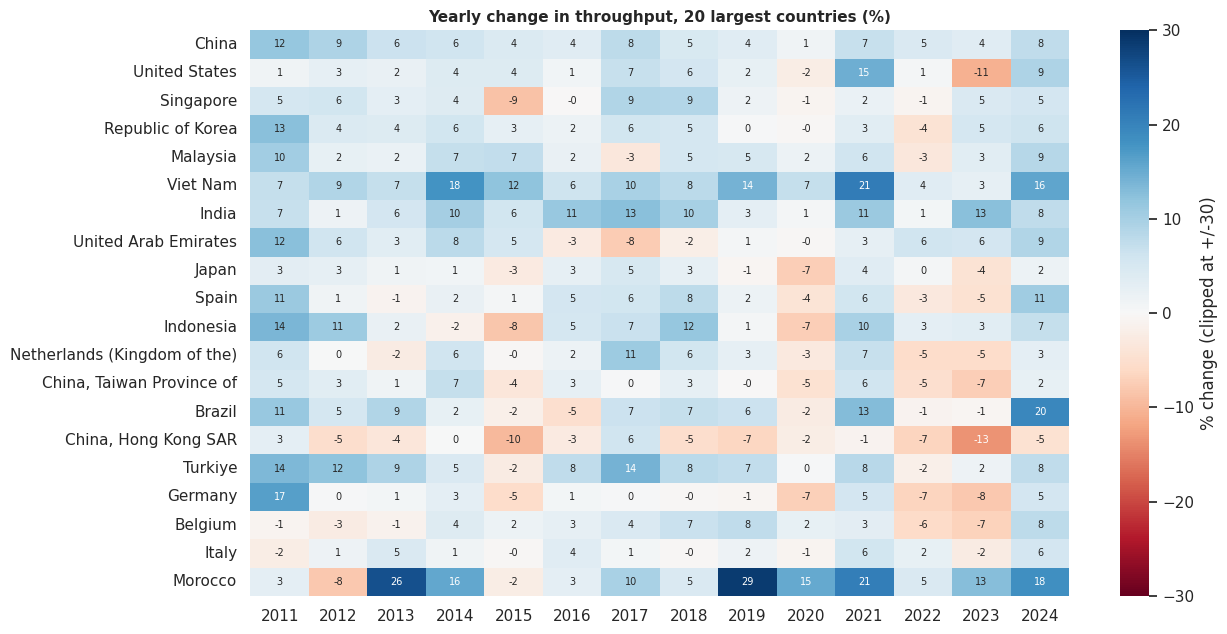

In [257]:
# Heatmap: yearly growth of the 20 largest countries
top20 = tc[tc.Year == LATEST].nlargest(20, "TEU").Economy
gr = wide[top20].pct_change().dropna() * 100
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(gr.T, cmap="RdBu", center=0, vmin=-30, vmax=30, annot=True, fmt=".0f", annot_kws={"size": 7}, cbar_kws={"label": "% change (clipped at +/-30)"}, ax=ax)
ax.set_title("Yearly change in throughput, 20 largest countries (%)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [258]:
# lsci
# Setup
ls = lsci_clean.dropna(subset=["LSCI"]).copy()
wide = ls.pivot(index="Date", columns="Economy", values="LSCI")                      # quarters x economies
LATEST = wide.index.max(); FIRST = wide.index.min()
full = wide.columns[wide.notna().all()]                                              # economies with every quarter: a fair panel over time
EVENTS = {"2008-10": "Financial crisis", "2020-03": "COVID-19", "2021-03": "Suez blocked", "2022-02": "Ukraine war", "2023-12": "Red Sea"}
print(f"economies: {wide.shape[1]} | quarters: {wide.shape[0]} ({FIRST:%Y-Q}{(FIRST.month - 1) // 3 + 1} to {LATEST:%Y-Q}{(LATEST.month - 1) // 3 + 1}) | with every quarter: {len(full)}")

economies: 191 | quarters: 83 (2006-Q1 to 2026-Q3) | with every quarter: 157


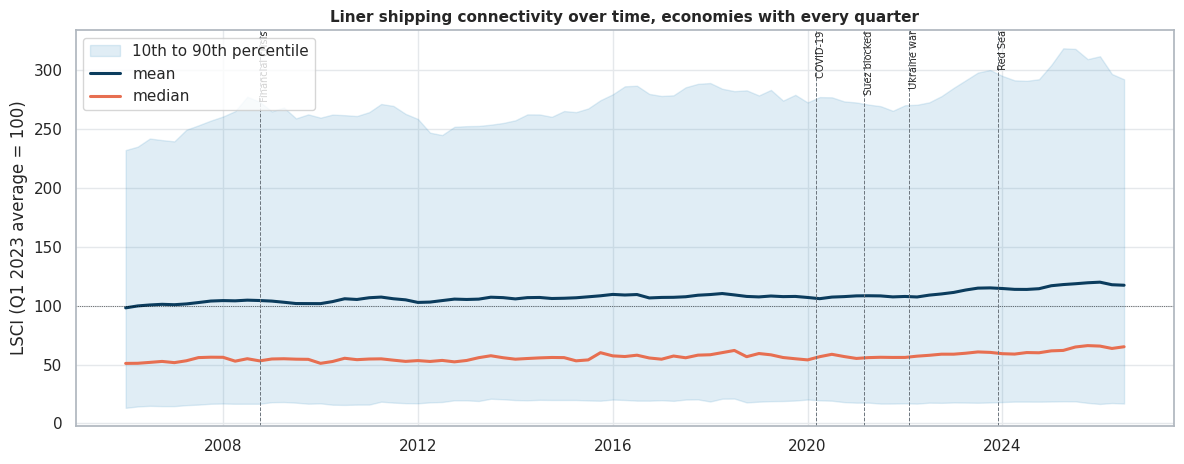

mean index: first 98.0 | lowest 98.0 2006-01 | highest 119.8 2026-01 | latest 117.2
median / mean gap shows how skewed it is: 65.1 vs 117.2


In [259]:
# Global connectivity over time (the 157 economies present in every quarter)
b = wide[full]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.fill_between(b.index, b.quantile(.1, axis=1), b.quantile(.9, axis=1), color=BLUE, alpha=.15, label="10th to 90th percentile")
ax.plot(b.index, b.mean(axis=1), color=NAVY, lw=2.2, label="mean"); ax.plot(b.index, b.median(axis=1), color=CORAL, lw=2.2, label="median")
ax.axhline(100, color="k", lw=.5, ls=":"); ax.set_ylabel("LSCI (Q1 2023 average = 100)")
for d, label in EVENTS.items():
    ax.axvline(pd.Timestamp(d + "-01"), color="#6C757D", ls="--", lw=.7); ax.text(pd.Timestamp(d + "-01"), ax.get_ylim()[1], " " + label, rotation=90, va="top", fontsize=7)
ax.set_title("Liner shipping connectivity over time, economies with every quarter"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
m = b.mean(axis=1); print("mean index: first", round(m.iloc[0], 1), "| lowest", round(m.min(), 1), m.idxmin().strftime("%Y-%m"), "| highest", round(m.max(), 1), m.idxmax().strftime("%Y-%m"), "| latest", round(m.iloc[-1], 1))
print("median / mean gap shows how skewed it is:", round(b.median(axis=1).iloc[-1], 1), "vs", round(m.iloc[-1], 1))

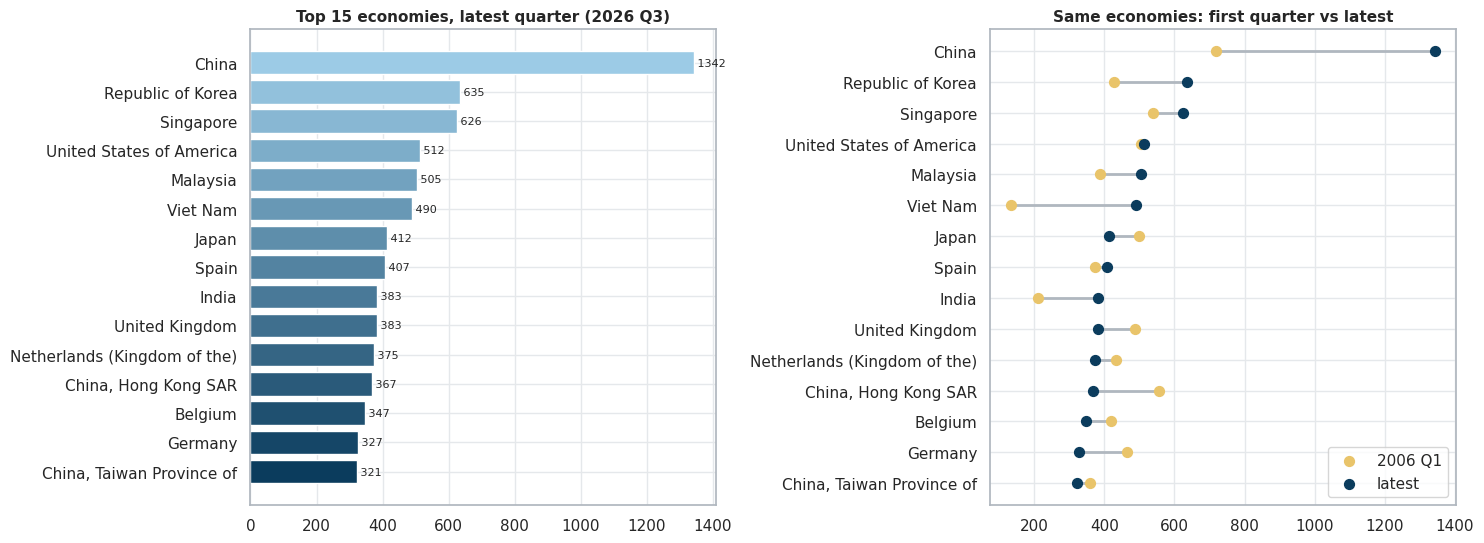

China is 7.2% of the sum of all indices | top 10 hold 30.5%


In [262]:
# Best-connected economies now, and how far they moved
top = wide.loc[LATEST].nlargest(15); first_val = wide.loc[FIRST, top.index]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
axes[0].barh(top.index[::-1], top.values[::-1], color=sns.color_palette("blend:#9CCBE6,#0B3C5D", len(top))[::-1]); axes[0].set_title(f"Top 15 economies, latest quarter ({LATEST:%Y} Q{(LATEST.month - 1) // 3 + 1})")
for i, (e, v) in enumerate(top[::-1].items()): axes[0].text(v, i, f" {v:.0f}", va="center", fontsize=8)
y = np.arange(len(top))[::-1]
axes[1].hlines(y, first_val.values, top.values, color="#B0B7BF", lw=2); axes[1].scatter(first_val.values, y, color=SAND, s=50, label=f"{FIRST:%Y} Q1", zorder=3); axes[1].scatter(top.values, y, color=NAVY, s=50, label="latest", zorder=3)
axes[1].set_yticks(y); axes[1].set_yticklabels(top.index); axes[1].set_title("Same economies: first quarter vs latest"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"China is {wide.loc[LATEST, 'China'] / wide.loc[LATEST].sum() * 100:.1f}% of the sum of all indices | top 10 hold {wide.loc[LATEST].nlargest(10).sum() / wide.loc[LATEST].sum() * 100:.1f}%")

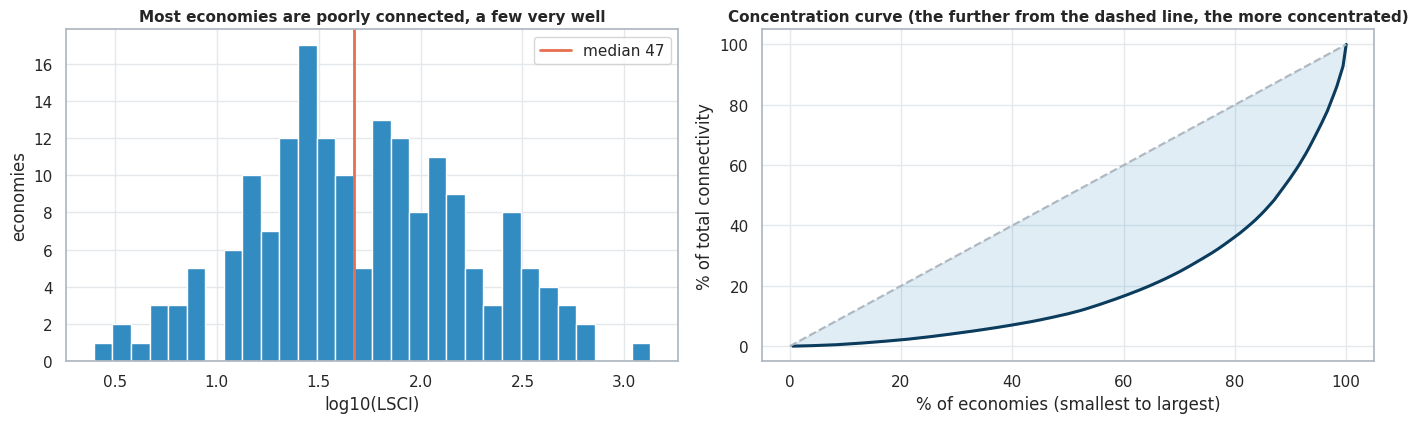

economies: 178 | median 47 | mean 105 | below 25: 50 | above 100: 54
the smallest half of economies holds 10.7% of total connectivity


In [261]:
# How unequal is connectivity? (latest quarter)
v = wide.loc[LATEST].dropna().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].hist(np.log10(v), bins=30, color=BLUE, edgecolor="white"); axes[0].set_xlabel("log10(LSCI)"); axes[0].set_ylabel("economies"); axes[0].axvline(np.log10(v.median()), color=CORAL, lw=2, label=f"median {v.median():.0f}"); axes[0].legend(); axes[0].set_title("Most economies are poorly connected, a few very well")
cum = v.cumsum() / v.sum() * 100; axes[1].plot(np.arange(1, len(v) + 1) / len(v) * 100, cum.values, color=NAVY, lw=2.2); axes[1].plot([0, 100], [0, 100], color="#B0B7BF", ls="--")
axes[1].fill_between(np.arange(1, len(v) + 1) / len(v) * 100, cum.values, np.arange(1, len(v) + 1) / len(v) * 100, color=BLUE, alpha=.15)
axes[1].set_xlabel("% of economies (smallest to largest)"); axes[1].set_ylabel("% of total connectivity"); axes[1].set_title("Concentration curve (the further from the dashed line, the more concentrated)")
plt.tight_layout(); plt.show()
print(f"economies: {len(v)} | median {v.median():.0f} | mean {v.mean():.0f} | below 25: {(v < 25).sum()} | above 100: {(v > 100).sum()}")
print(f"the smallest half of economies holds {cum.iloc[len(v) // 2 - 1]:.1f}% of total connectivity")

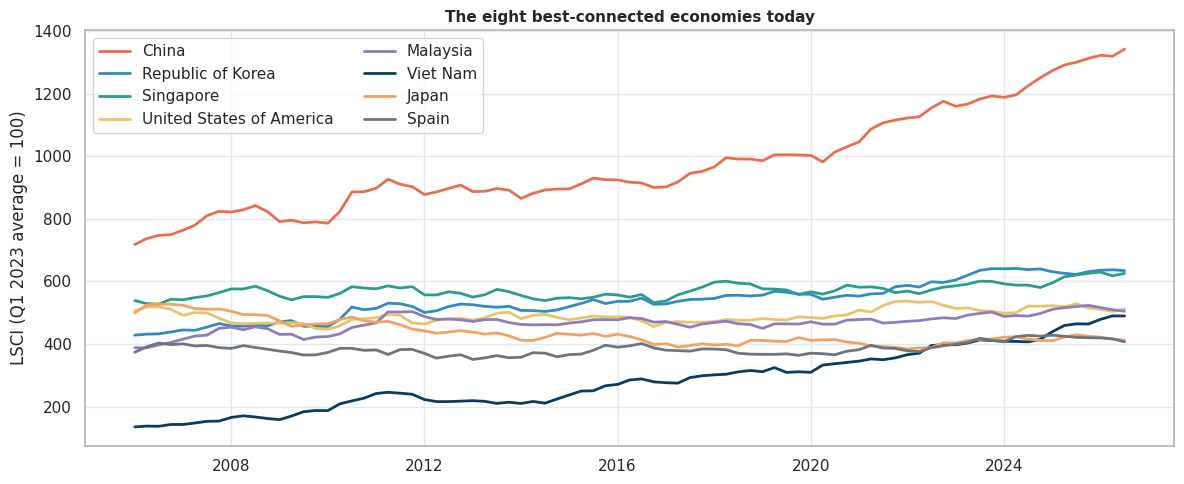

Date                      2006-01-01  2019-01-01  2026-07-01
Economy                                                     
China                          718.0       986.0      1342.0
Republic of Korea              428.0       556.0       635.0
Singapore                      539.0       576.0       626.0
United States of America       506.0       482.0       512.0
Malaysia                       388.0       450.0       505.0
Viet Nam                       135.0       311.0       490.0
Japan                          499.0       412.0       412.0
Spain                          374.0       367.0       407.0


In [263]:
# Leading economies over time
lead = wide.loc[LATEST].nlargest(8).index
fig, ax = plt.subplots(figsize=(12, 5))
for e, col in zip(lead, [CORAL, BLUE, TEAL, SAND, PURPLE, NAVY, ORANGE, "#6C757D"]): ax.plot(wide.index, wide[e], color=col, lw=2, label=e)
ax.set_ylabel("LSCI (Q1 2023 average = 100)"); ax.set_title("The eight best-connected economies today"); ax.legend(ncol=2, loc="upper left")
plt.tight_layout(); plt.show()
print((wide.loc[[FIRST, wide.index[wide.index.get_indexer([pd.Timestamp('2019-01-01')], method='nearest')[0]], LATEST], lead].T.round(0)))

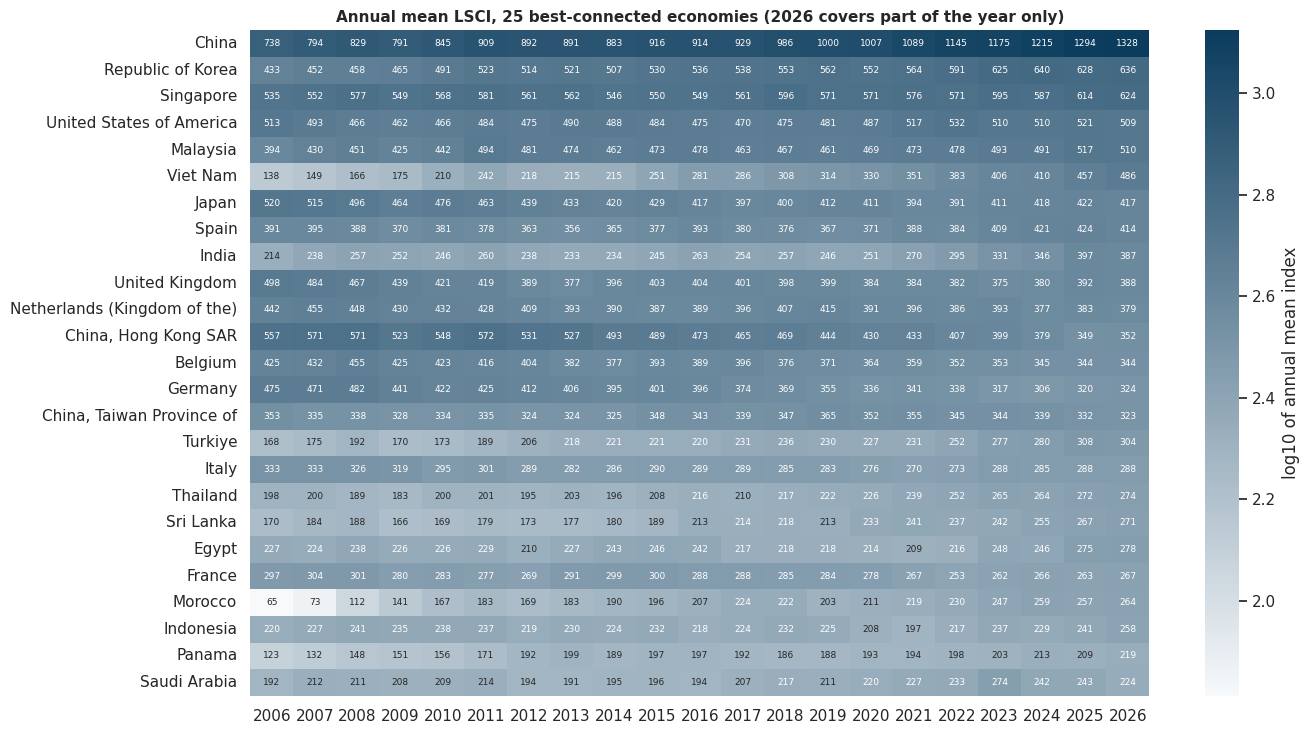

In [265]:
# Heatmap: annual average index of the 25 best-connected economies
ann = wide.groupby(wide.index.year).mean(); last_full = int(LATEST.year) if LATEST.month >= 10 else int(LATEST.year) - 1
top25 = wide.loc[LATEST].nlargest(25).index
fig, ax = plt.subplots(figsize=(14, 7.5))
# Define a sequential color palette since SEQ was not defined
SEQ = sns.color_palette("blend:#F7F9FB,#0B3C5D", as_cmap=True)
sns.heatmap(np.log10(ann[top25].T), cmap=SEQ, annot=ann[top25].T.round(0), fmt=".0f", annot_kws={"size": 6.5}, cbar_kws={"label": "log10 of annual mean index"}, ax=ax)
ax.set_title(f"Annual mean LSCI, 25 best-connected economies ({int(LATEST.year)} covers part of the year only)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

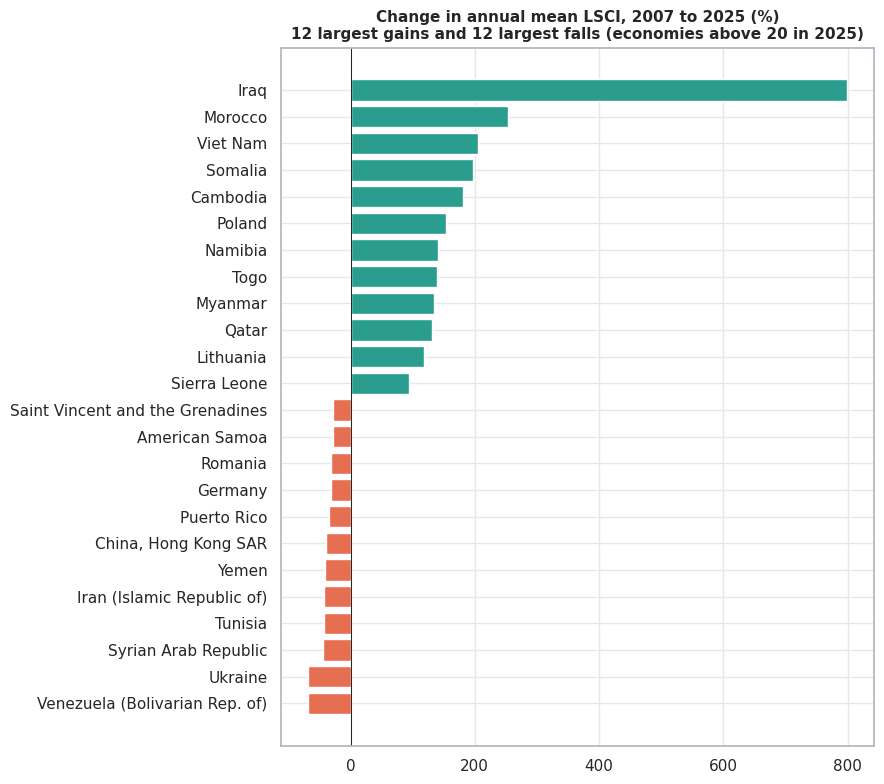

economies that gained: 69% (n=141) | median change 16%


In [266]:
# Who gained and who lost: annual mean, first full year vs last full year
y0, y1 = 2007, 2025
chg = ((ann.loc[y1] / ann.loc[y0] - 1) * 100).dropna(); chg = chg[ann.loc[y1, chg.index] >= 20]          # economies with a meaningful index
sel = pd.concat([chg.nlargest(12), chg.nsmallest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 8)); ax.barh(sel.index, sel.values, color=[NEG if x < 0 else POS for x in sel]); ax.axvline(0, color="k", lw=.6)
ax.set_title(f"Change in annual mean LSCI, {y0} to {y1} (%)\n12 largest gains and 12 largest falls (economies above 20 in {y1})")
plt.tight_layout(); plt.show()
print(f"economies that gained: {(chg > 0).mean():.0%} (n={len(chg)}) | median change {chg.median():.0f}%")

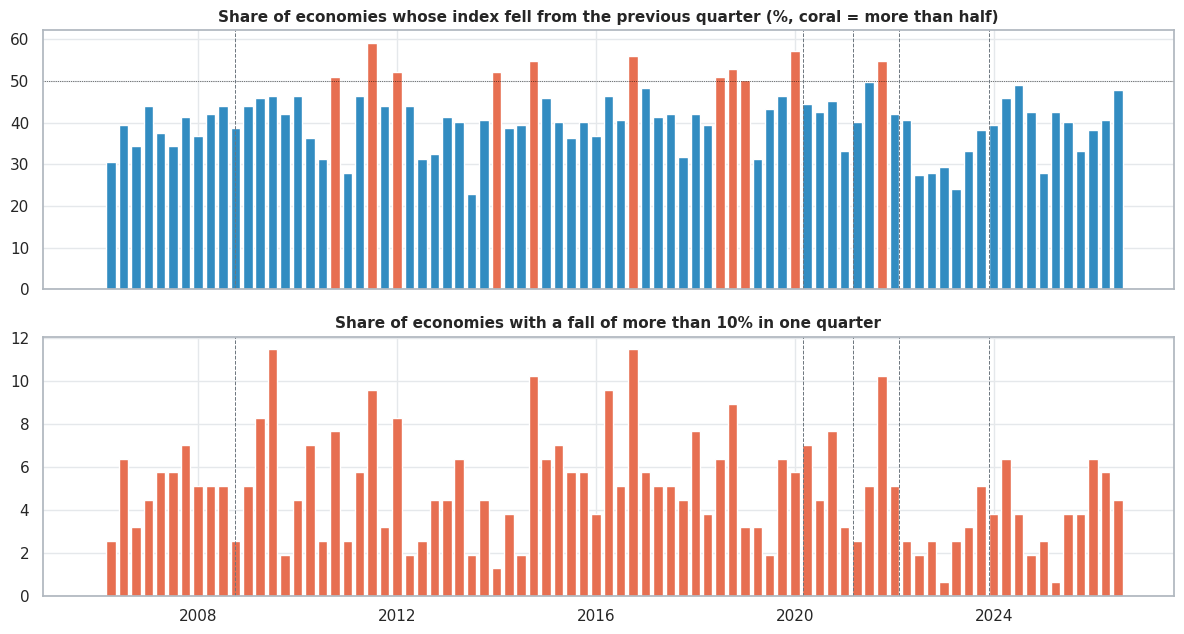

quarters with the most widespread falls:
{'2011-07': 59.0, '2020-01': 57.0, '2016-10': 56.0, '2014-10': 55.0, '2021-10': 55.0}


In [267]:
# Shocks: how many economies lost connectivity each quarter?
qoq = wide[full].pct_change() * 100
share_down = (qoq < 0).mean(axis=1) * 100; big_drop = (qoq < -10).mean(axis=1) * 100
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].bar(share_down.index, share_down.values, width=70, color=[NEG if v > 50 else BLUE for v in share_down]); axes[0].axhline(50, color="k", lw=.5, ls=":")
axes[0].set_title("Share of economies whose index fell from the previous quarter (%, coral = more than half)")
axes[1].bar(big_drop.index, big_drop.values, width=70, color=CORAL); axes[1].set_title("Share of economies with a fall of more than 10% in one quarter")
for ax in axes:
    for d, label in EVENTS.items(): ax.axvline(pd.Timestamp(d + "-01"), color="#6C757D", ls="--", lw=.7)
plt.tight_layout(); plt.show()
print("quarters with the most widespread falls:"); print(share_down.nlargest(5).round(0).rename(lambda d: f"{d:%Y-%m}").to_dict())

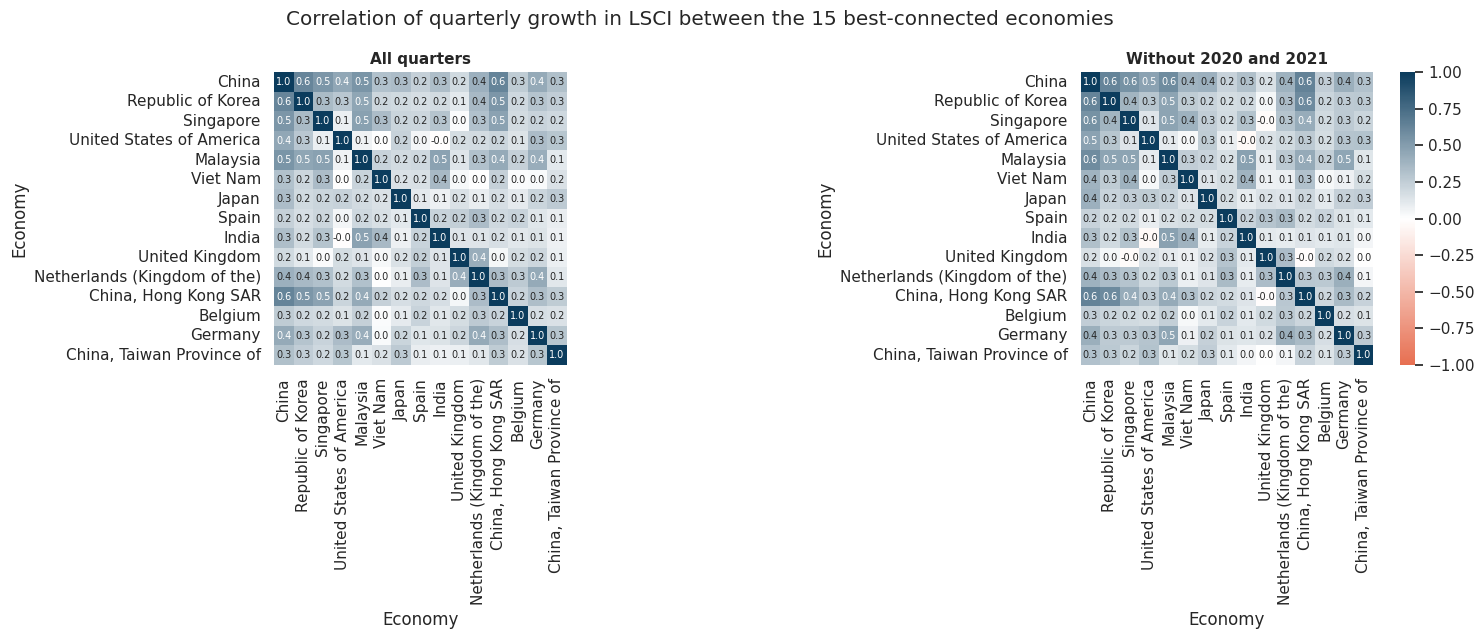

In [269]:
# Do economies move together? Quarterly growth, 15 best-connected
from matplotlib.colors import LinearSegmentedColormap

# Define the missing diverging colormap
DIV = LinearSegmentedColormap.from_list("div", [CORAL, "white", NAVY])

t15 = wide.loc[LATEST].nlargest(15).index
cq = wide[t15].pct_change().dropna() * 100
calm = cq.drop(cq.loc["2020-01-01":"2021-12-31"].index, errors="ignore")
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(cq.corr(), annot=True, fmt=".1f", cmap=DIV, vmin=-1, vmax=1, square=True, annot_kws={"size": 7}, cbar=False, ax=axes[0]); axes[0].set_title("All quarters")
sns.heatmap(calm.corr(), annot=True, fmt=".1f", cmap=DIV, vmin=-1, vmax=1, square=True, annot_kws={"size": 7}, ax=axes[1]); axes[1].set_title("Without 2020 and 2021")
plt.suptitle("Correlation of quarterly growth in LSCI between the 15 best-connected economies"); plt.tight_layout(); plt.show()

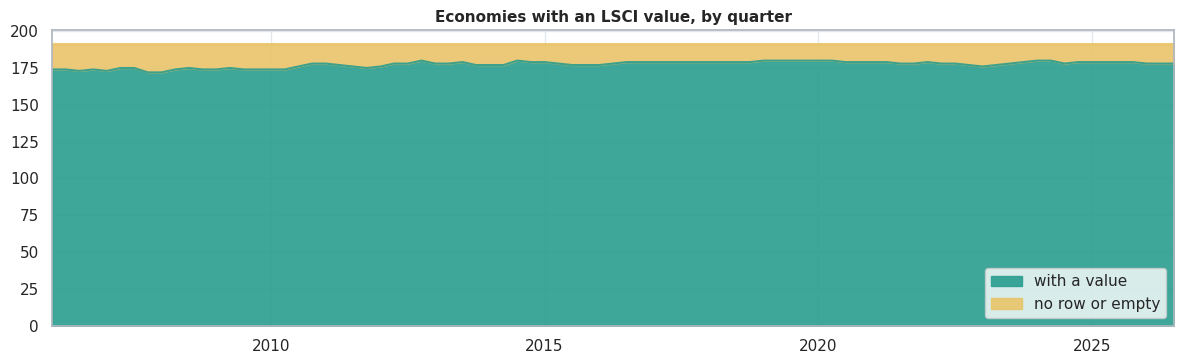

economies in total: 191 | with every quarter: 157 | empty values (all 'Not applicable'): 289 | economies that appear or end part-way: 34


In [270]:
# Data coverage: how many economies have a value each quarter?
cov = pd.DataFrame({"with a value": wide.notna().sum(axis=1), "no row or empty": wide.shape[1] - wide.notna().sum(axis=1)})
fig, ax = plt.subplots(figsize=(12, 3.8)); cov.plot.area(ax=ax, color=[TEAL, SAND], alpha=.9); ax.set_title("Economies with an LSCI value, by quarter"); ax.set_xlabel(""); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
na = lsci_clean.LSCI_missing.eq("Not applicable").sum(); print(f"economies in total: {wide.shape[1]} | with every quarter: {len(full)} | empty values (all 'Not applicable'): {na} | economies that appear or end part-way: {(wide.notna().sum() < len(wide)).sum()}")

In [271]:
# US.Merchantfleet
from matplotlib.colors import LinearSegmentedColormap
NAVY, BLUE, TEAL, SAND, PURPLE, GREY, CORAL = "#0B3C5D", "#328CC1", "#2A9D8F", "#E9C46A", "#8E7DBE", "#8A939B", "#E76F51"
POS, NEG = TEAL, CORAL                                                      # growth up / down
CONT_COLORS = {"Asia": CORAL, "Americas": TEAL, "Europe": BLUE, "Africa": SAND, "Oceania": PURPLE}
DIV = LinearSegmentedColormap.from_list("div", [CORAL, "white", NAVY])

In [272]:
# US.Merchantfleet
# Load the cleaned fleet files (saved in Data Preparation)
fleet = pd.read_csv(PROC / "fleet_clean.csv", low_memory=False)          # all levels: world, groupings, countries
fc = pd.read_csv(PROC / "fleet_country.csv", low_memory=False)           # countries only, with ISO3
FT = ["Oil tankers", "Bulk carriers", "General cargo", "Container ships", "Other types of ships"]
FLEET_COLORS = {"Container ships": NAVY, "Oil tankers": BLUE, "Bulk carriers": TEAL, "General cargo": SAND, "Other types of ships": GREY}
FORDER = ["Container ships", "Oil tankers", "Bulk carriers", "General cargo", "Other types of ships"]
F_LAST = int(fleet.Year.max()); F_FIRST = int(fleet.Year.min())

fw = fleet[fleet.level == "world"]
fw_total = fw[fw.ShipType == "Total fleet"].set_index("Year")
fw_dwt = fw[fw.ShipType != "Total fleet"].pivot(index="Year", columns="ShipType", values="DWT_k")[FORDER] / 1e6     # billion dwt
print(f"years {F_FIRST}-{F_LAST} | countries: {fc.Economy.nunique()} | world fleet {F_FIRST}: {fw_total.DWT_k[F_FIRST] / 1e6:.2f} bn dwt -> {F_LAST}: {fw_total.DWT_k[F_LAST] / 1e6:.2f} bn dwt")

years 1980-2026 | countries: 209 | world fleet 1980: 0.67 bn dwt -> 2026: 2.53 bn dwt


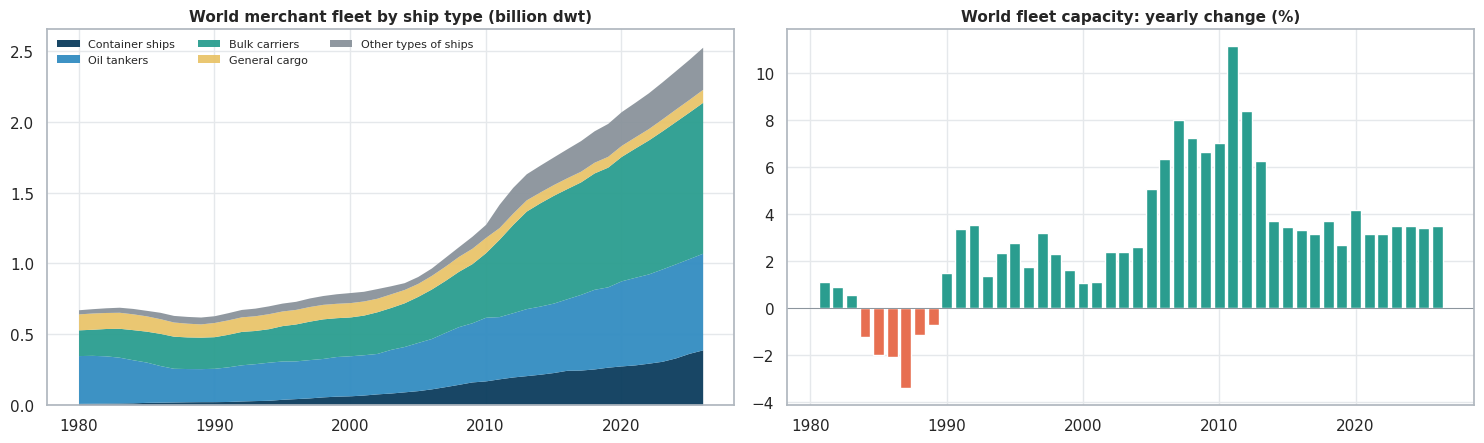

years with a fall: {1984: -1.2, 1985: -2.0, 1986: -2.1, 1987: -3.4, 1988: -1.1, 1989: -0.7}
growth 1980 to 2026: x3.8 | average yearly growth: 2.9%


In [273]:
# world fleet and yearly growth
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
fw_dwt.plot.area(ax=axes[0], color=[FLEET_COLORS[t] for t in FORDER], alpha=.95, lw=0); axes[0].set_title("World merchant fleet by ship type (billion dwt)"); axes[0].set_xlabel("")
axes[0].legend(ncol=3, loc="upper left", frameon=False, fontsize=8)
yoy = fw_total.DWT_k.pct_change().dropna() * 100
axes[1].bar(yoy.index, yoy.values, color=[NEG if v < 0 else POS for v in yoy]); axes[1].axhline(0, color=GREY, lw=.7); axes[1].set_title("World fleet capacity: yearly change (%)")
plt.tight_layout(); plt.show()
print("years with a fall:", yoy[yoy < 0].round(1).to_dict())
print(f"growth {F_FIRST} to {F_LAST}: x{fw_total.DWT_k[F_LAST] / fw_total.DWT_k[F_FIRST]:.1f} | average yearly growth: {((fw_total.DWT_k[F_LAST] / fw_total.DWT_k[F_FIRST]) ** (1 / (F_LAST - F_FIRST)) - 1) * 100:.1f}%")

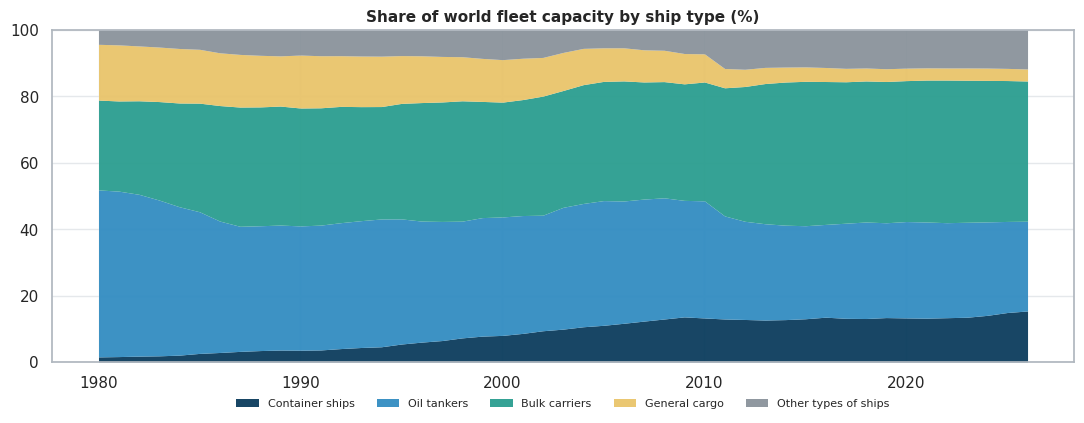

ShipType  Container ships  Oil tankers  Bulk carriers  General cargo  Other types of ships
Year                                                                                      
1980                  1.5         50.3           27.1           16.8                   4.3
1990                  3.5         37.4           35.5           15.9                   7.6
2000                  8.0         35.7           34.6           12.8                   9.0
2010                 13.3         35.3           35.8            8.5                   7.2
2020                 13.3         29.0           42.4            3.8                  11.5
2026                 15.4         27.0           42.2            3.6                  11.8


In [274]:
# fleet mix
mix = fw_dwt.div(fw_dwt.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(11, 4.4))
mix.plot.area(ax=ax, color=[FLEET_COLORS[t] for t in FORDER], alpha=.95, lw=0); ax.set_ylim(0, 100); ax.set_xlabel(""); ax.set_title("Share of world fleet capacity by ship type (%)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.08), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(mix.loc[[F_FIRST, 1990, 2000, 2010, 2020, F_LAST]].round(1).to_string())

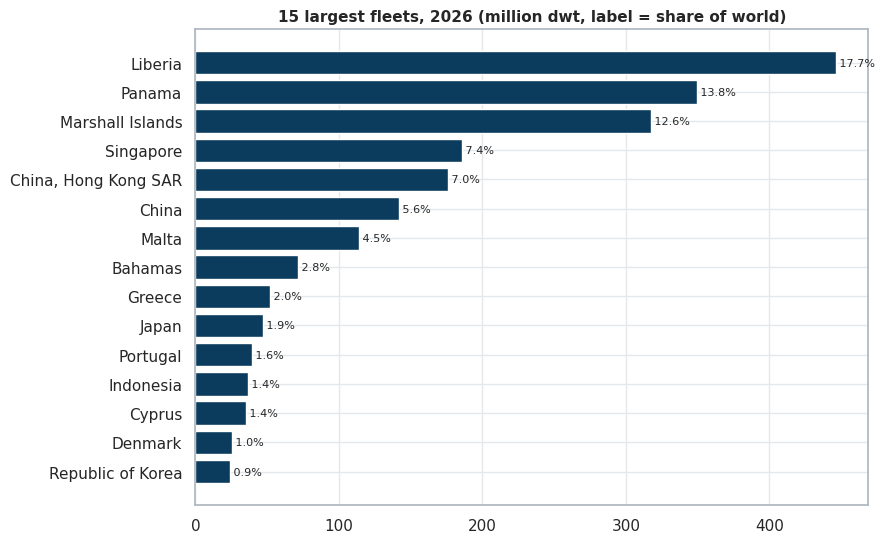

top 15 = 81.5% of world | top 1: Liberia 17.7%


In [275]:
# largest fleets
ct = fc[(fc.ShipType == "Total fleet") & (fc.Year == F_LAST)].dropna(subset=["DWT_k"]).nlargest(15, "DWT_k")
shr = ct.DWT_k / fw_total.DWT_k[F_LAST] * 100
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(ct.Economy[::-1], ct.DWT_k[::-1] / 1e3, color=NAVY)
for i, (v, s) in enumerate(zip(ct.DWT_k[::-1] / 1e3, shr[::-1])): ax.text(v, i, f" {s:.1f}%", va="center", fontsize=8)
ax.set_title(f"15 largest fleets, {F_LAST} (million dwt, label = share of world)")
plt.tight_layout(); plt.show()
print(f"top 15 = {shr.sum():.1f}% of world | top 1: {ct.Economy.iloc[0]} {shr.iloc[0]:.1f}%")

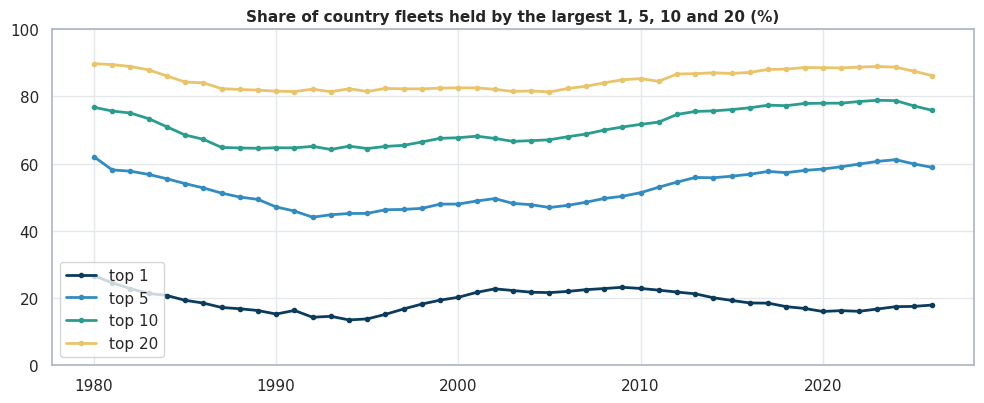

      top 1  top 5  top 10  top 20
Year                              
1980   26.5   62.0    76.8    89.8
2000   20.1   47.9    67.7    82.6
2010   22.8   51.3    71.7    85.3
2026   17.8   58.9    75.9    86.2


In [276]:
# concentration over time
tot = fc[fc.ShipType == "Total fleet"].dropna(subset=["DWT_k"])
cs_ = tot.groupby("Year").DWT_k.sum()
conc = pd.DataFrame({f"top {k}": tot.groupby("Year").DWT_k.apply(lambda s, k=k: s.nlargest(k).sum()) / cs_ * 100 for k in (1, 5, 10, 20)})
fig, ax = plt.subplots(figsize=(10, 4.2)); conc.plot(ax=ax, marker="o", ms=3, color=[NAVY, BLUE, TEAL, SAND], lw=2); ax.set_xlabel(""); ax.set_ylim(0, 100)
ax.set_title("Share of country fleets held by the largest 1, 5, 10 and 20 (%)"); plt.tight_layout(); plt.show()
print(conc.loc[[F_FIRST, 2000, 2010, F_LAST]].round(1).to_string())

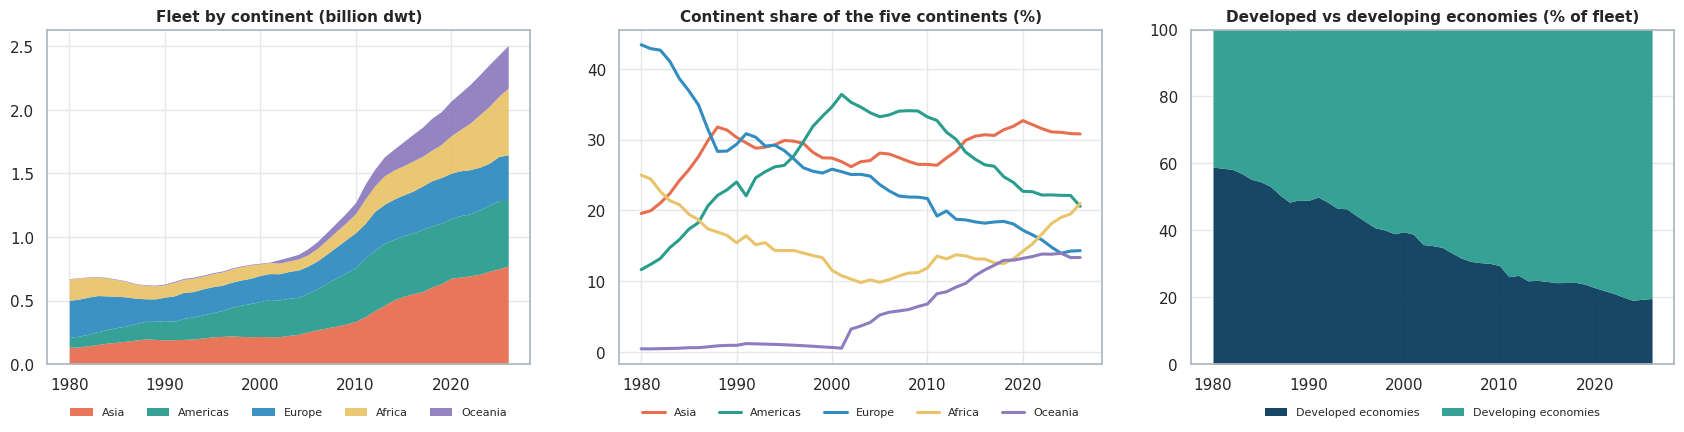

Economy  Asia  Americas  Europe  Africa  Oceania
Year                                            
1980     19.6      11.6    43.4    25.0      0.4
2000     27.4      34.6    25.8    11.5      0.6
2026     30.8      20.6    14.3    21.0     13.3


In [277]:
# continents and development status
gt = fleet[(fleet.level == "grouping") & (fleet.ShipType == "Total fleet")].pivot(index="Year", columns="Economy", values="DWT_k") / 1e6
CONTS = ["Asia", "Americas", "Europe", "Africa", "Oceania"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
gt[CONTS].plot.area(ax=axes[0], color=[CONT_COLORS[c] for c in CONTS], alpha=.95, lw=0); axes[0].set_title("Fleet by continent (billion dwt)")
(gt[CONTS].div(gt[CONTS].sum(axis=1), axis=0) * 100).plot(ax=axes[1], color=[CONT_COLORS[c] for c in CONTS], lw=2.2); axes[1].set_title("Continent share of the five continents (%)")
dev = gt[["Developed economies", "Developing economies"]]
(dev.div(dev.sum(axis=1), axis=0) * 100).plot.area(ax=axes[2], color=[NAVY, TEAL], alpha=.95, lw=0); axes[2].set_title("Developed vs developing economies (% of fleet)"); axes[2].set_ylim(0, 100)
for ax in axes: ax.set_xlabel(""); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.1), ncol=5, fontsize=8, frameon=False, title="")
plt.tight_layout(); plt.show()
print((gt[CONTS].loc[[F_FIRST, 2000, F_LAST]].div(gt[CONTS].loc[[F_FIRST, 2000, F_LAST]].sum(axis=1), axis=0) * 100).round(1).to_string())

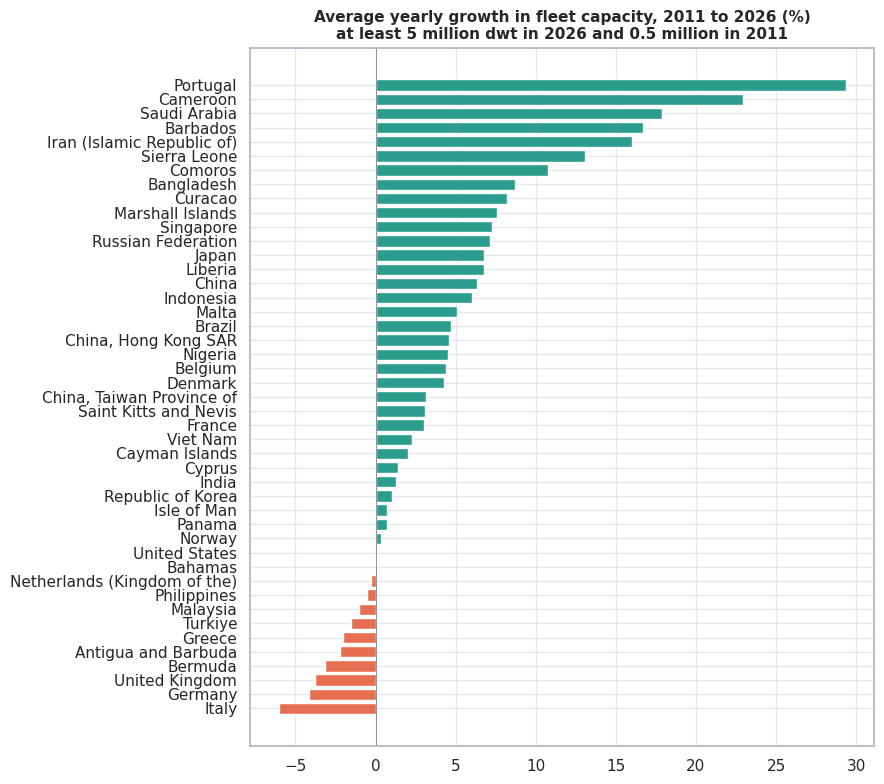

fastest: {'Portugal': 29.3, 'Cameroon': 22.9, 'Saudi Arabia': 17.9, 'Barbados': 16.7, 'Iran (Islamic Republic of)': 16.0}
slowest: {'Italy': -6.0, 'Germany': -4.2, 'United Kingdom': -3.8, 'Bermuda': -3.2, 'Antigua and Barbuda': -2.2}


In [278]:
# since 2011 what grew
wd = fc[fc.ShipType == "Total fleet"].pivot(index="Year", columns="Economy", values="DWT_k")     # years x countries
first, last = wd.loc[2011], wd.loc[F_LAST]
big = last[last >= 5e3].index.intersection(first[first >= 500].index)       # skip tiny 2011 bases that inflate growth
cagr = ((last[big] / first[big]) ** (1 / (F_LAST - 2011)) - 1) * 100
c = cagr.sort_values()
fig, ax = plt.subplots(figsize=(9, 8)); ax.barh(c.index, c.values, color=[NEG if v < 0 else POS for v in c]); ax.axvline(0, color=GREY, lw=.7)
ax.set_title(f"Average yearly growth in fleet capacity, 2011 to {F_LAST} (%)\nat least 5 million dwt in {F_LAST} and 0.5 million in 2011")
plt.tight_layout(); plt.show()
print("fastest:", cagr.nlargest(5).round(1).to_dict()); print("slowest:", cagr.nsmallest(5).round(1).to_dict())

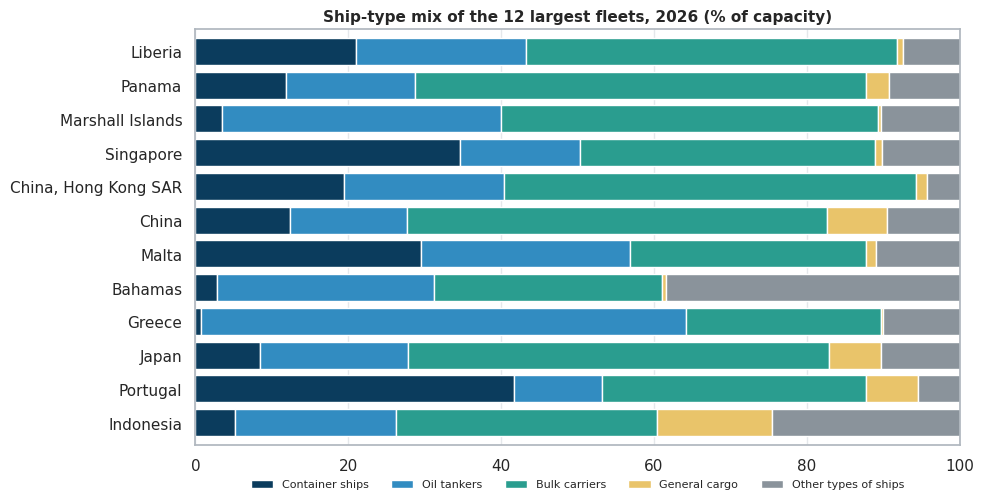

In [279]:
# what the big fleets specialise in
top12 = fc[(fc.ShipType == "Total fleet") & (fc.Year == F_LAST)].nlargest(12, "DWT_k").Economy
ts = fc[(fc.Year == F_LAST) & fc.Economy.isin(top12) & (fc.ShipType != "Total fleet")].pivot(index="Economy", columns="ShipType", values="DWT_k")[FORDER].loc[top12]
fig, ax = plt.subplots(figsize=(10, 5.2))
(ts.div(ts.sum(axis=1), axis=0) * 100).iloc[::-1].plot.barh(stacked=True, ax=ax, color=[FLEET_COLORS[t] for t in FORDER], width=.8)
ax.set_xlim(0, 100); ax.set_ylabel(""); ax.set_title(f"Ship-type mix of the 12 largest fleets, {F_LAST} (% of capacity)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.06), frameon=False, fontsize=8); plt.tight_layout(); plt.show()

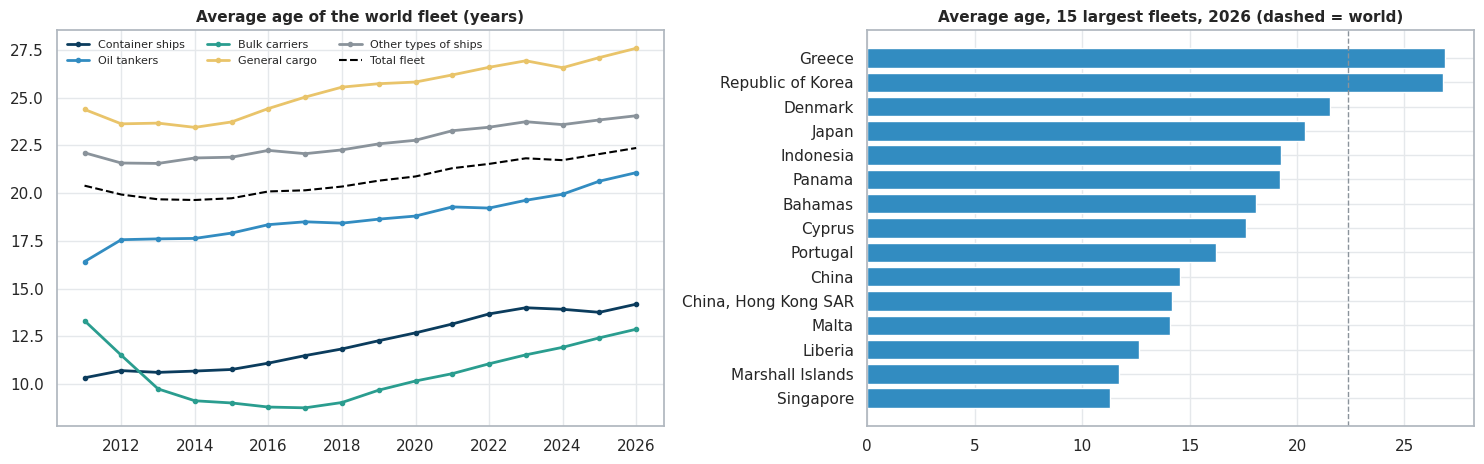

world average age by ship type, latest: {'Container ships': 14.2, 'Oil tankers': 21.1, 'Bulk carriers': 12.9, 'General cargo': 27.6, 'Other types of ships': 24.1} | total: 22.4


In [280]:
# fleet age from 2011
ag = fw[fw.ShipType != "Total fleet"].pivot(index="Year", columns="ShipType", values="Age").dropna(how="all")[FORDER]
aw = fw_total.Age.dropna()
ac = fc[(fc.ShipType == "Total fleet") & (fc.Year == F_LAST) & ~fc.age_small_fleet].nlargest(15, "DWT_k").set_index("Economy").Age.sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for t in FORDER: axes[0].plot(ag.index, ag[t], color=FLEET_COLORS[t], lw=2, marker="o", ms=3, label=t)
axes[0].plot(aw.index, aw.values, color="k", lw=1.5, ls="--", label="Total fleet"); axes[0].set_title("Average age of the world fleet (years)"); axes[0].legend(ncol=3, frameon=False, fontsize=8)
axes[1].barh(ac.index, ac.values, color=BLUE); axes[1].axvline(aw[F_LAST], color=GREY, ls="--", lw=1); axes[1].set_title(f"Average age, 15 largest fleets, {F_LAST} (dashed = world)")
plt.tight_layout(); plt.show()
print("world average age by ship type, latest:", ag.iloc[-1].round(1).to_dict(), "| total:", round(float(aw.iloc[-1]), 1))

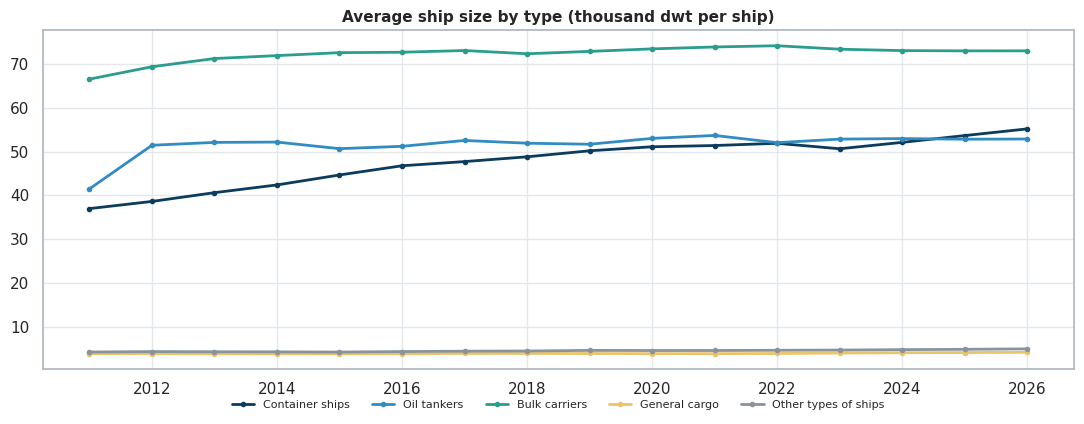

ShipType  Container ships  Oil tankers  Bulk carriers  General cargo  Other types of ships
Year                                                                                      
2011                 37.0         41.5           66.5            3.9                   4.3
2026                 55.2         52.9           73.0            4.2                   5.0


In [281]:
# average ship size
wt_ = fw[fw.ShipType != "Total fleet"]
sz = wt_.pivot(index="Year", columns="ShipType", values="DWT_k").div(wt_.pivot(index="Year", columns="ShipType", values="Ships")).dropna(how="all")[FORDER]    # thousand dwt per ship
fig, ax = plt.subplots(figsize=(11, 4.4))
for t in FORDER: ax.plot(sz.index, sz[t], color=FLEET_COLORS[t], lw=2, marker="o", ms=3, label=t)
ax.set_title("Average ship size by type (thousand dwt per ship)"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.06), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(sz.loc[[sz.index.min(), F_LAST]].round(1).to_string())

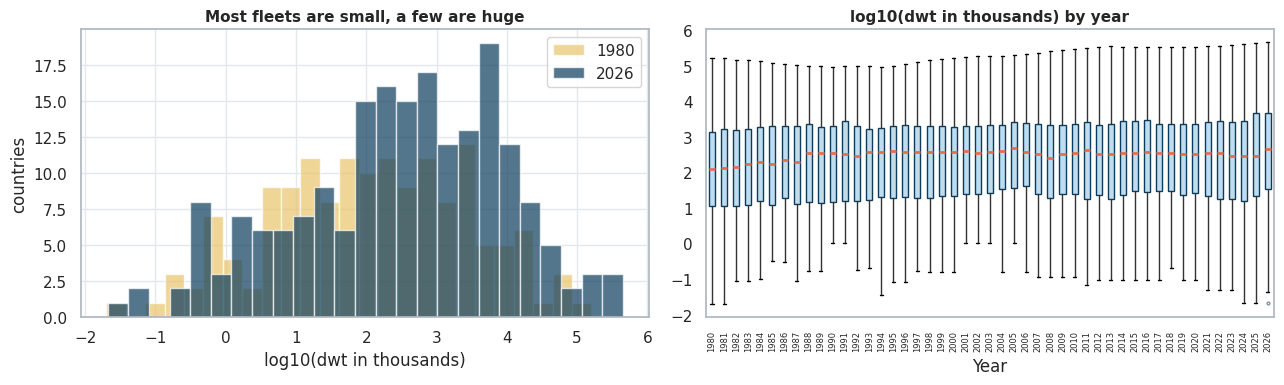

countries by fleet size in 2026 (dwt): {'< 0.1M': 66, '0.1M to 1M': 53, '1M to 10M': 51, '10M to 100M': 20, '> 100M': 7} | median (thousand dwt): 462


In [282]:
# size distribution
tc_ = fc[(fc.ShipType == "Total fleet") & fc.DWT_k.gt(0)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for yv, col in ((1980, SAND), (F_LAST, NAVY)): axes[0].hist(np.log10(tc_[tc_.Year == yv].DWT_k), bins=25, alpha=.7, color=col, label=str(yv))
axes[0].set_xlabel("log10(dwt in thousands)"); axes[0].set_ylabel("countries"); axes[0].legend(); axes[0].set_title("Most fleets are small, a few are huge")
tc_.assign(l=np.log10(tc_.DWT_k)).boxplot(column="l", by="Year", ax=axes[1], grid=False, patch_artist=True, boxprops=dict(facecolor="#BFDDEE", color=NAVY), medianprops=dict(color=CORAL, lw=2), flierprops=dict(markersize=2, markeredgecolor=GREY))
axes[1].set_title("log10(dwt in thousands) by year"); axes[1].tick_params(axis="x", labelrotation=90, labelsize=6); plt.suptitle("")
plt.tight_layout(); plt.show()
szb = pd.cut(tc_[tc_.Year == F_LAST].DWT_k, [0, 1e2, 1e3, 1e4, 1e5, 1e9], labels=["< 0.1M", "0.1M to 1M", "1M to 10M", "10M to 100M", "> 100M"]).value_counts().sort_index()
print(f"countries by fleet size in {F_LAST} (dwt):", szb.to_dict(), "| median (thousand dwt):", round(tc_[tc_.Year == F_LAST].DWT_k.median()))

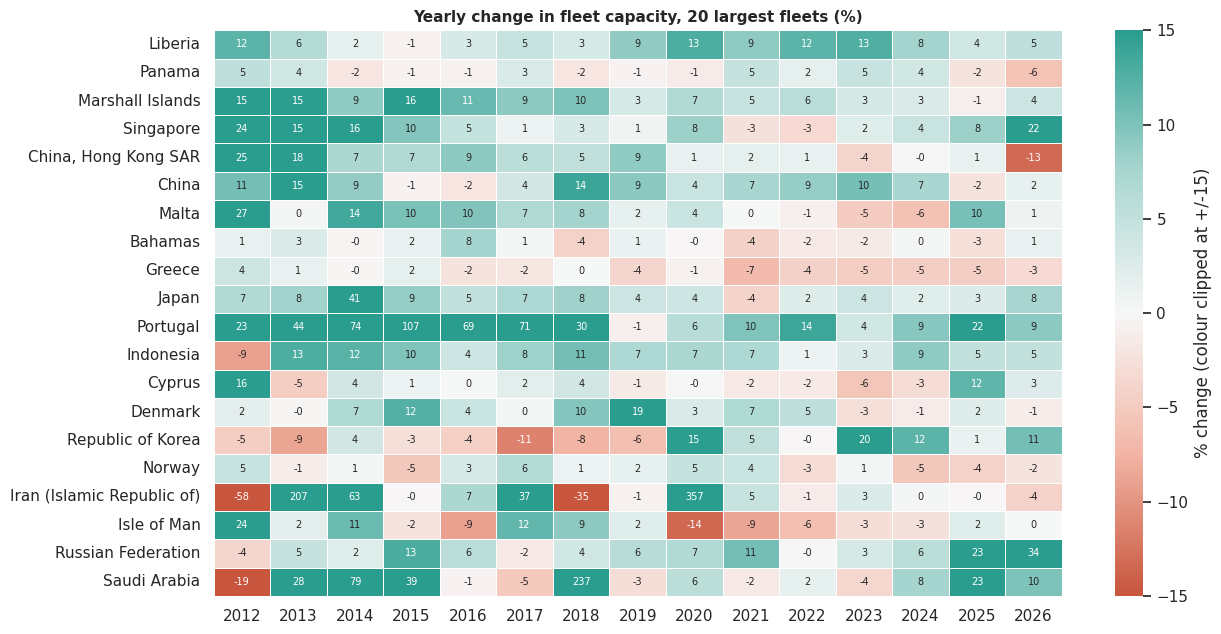

In [283]:
# growth heatmap
t20 = wd.loc[F_LAST].nlargest(20).index                  # uses wd from Cell 7
gr = wd[t20].loc[F_LAST - 15:].pct_change().dropna(how="all") * 100

growth_cmap = LinearSegmentedColormap.from_list("growth", ["#C8553D", "#F2B5A5", "#F7F7F7", "#A9D6D0", "#2A9D8F"])   # coral = fall, teal = rise

fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(gr.T, cmap=growth_cmap, center=0, vmin=-15, vmax=15, annot=True, fmt=".0f", annot_kws={"size": 7},
            linewidths=.5, linecolor="white", cbar_kws={"label": "% change (colour clipped at +/-15)"}, ax=ax)
ax.set_title("Yearly change in fleet capacity, 20 largest fleets (%)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [284]:
# Daily chokepoints
from matplotlib.colors import LinearSegmentedColormap
NAVY, BLUE, TEAL, SAND, PURPLE, GREY, CORAL = "#0B3C5D", "#328CC1", "#2A9D8F", "#E9C46A", "#8E7DBE", "#8A939B", "#E76F51"
TYPES = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]
ORDER = ["container", "tanker", "dry_bulk", "general_cargo", "roro"]
TYPE_COLORS = {"container": NAVY, "tanker": BLUE, "dry_bulk": TEAL, "general_cargo": SAND, "roro": GREY}
growth_cmap = LinearSegmentedColormap.from_list("growth", ["#C8553D", "#F2B5A5", "#F7F7F7", "#A9D6D0", "#2A9D8F"])   # coral = fall, teal = rise

ck = pd.read_csv(PROC / "chokepoints_cleaned.csv", parse_dates=["date"])
ck["year"], ck["month"] = ck.date.dt.year, ck.date.dt.month

# One monthly table per chokepoint, complete months only
agg = {"transits": ("n_total", "sum"), "capacity": ("capacity", "sum"), "days": ("n_total", "size")}
for t in TYPES:
    agg[f"n_{t}"] = (f"n_{t}", "sum"); agg[f"cap_{t}"] = (f"capacity_{t}", "sum")
cm = ck.groupby(["chokepoint", "year", "month"]).agg(**agg).reset_index()
cm["date"] = pd.to_datetime(dict(year=cm.year, month=cm.month, day=1))
n0 = len(cm); cm = cm[cm.days == cm.date.dt.days_in_month].copy()
cm["per_day"] = cm.transits / cm.days
yrs = cm.groupby("year").month.nunique(); LASTY = int(yrs[yrs == 12].index.max())
print(f"{ck.shape} | {ck.date.min().date()} to {ck.date.max().date()} | chokepoint-months: {n0} -> {len(cm)} complete | last full year: {LASTY}")

(80528, 22) | 2019-01-01 to 2026-11-15 | chokepoint-months: 2660 -> 2632 complete | last full year: 2025


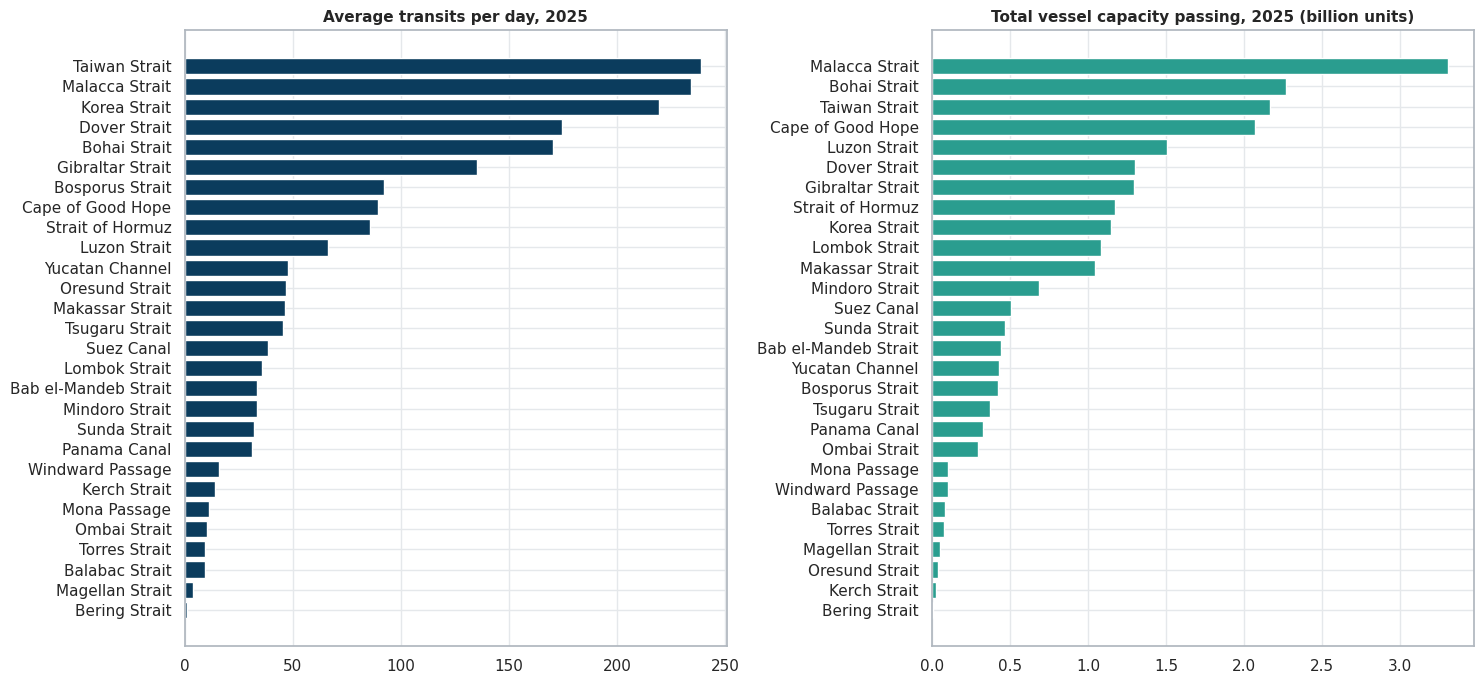

top 5 by transits: {'Taiwan Strait': 239.0, 'Malacca Strait': 234.0, 'Korea Strait': 219.0, 'Dover Strait': 175.0, 'Bohai Strait': 170.0}
top 5 chokepoints = 52.6% of all chokepoint transits | under 1 transit per day: 0 chokepoints


In [285]:
# busiest chokepoints
y = cm[cm.year == LASTY].groupby("chokepoint").agg(transits=("transits", "sum"), capacity=("capacity", "sum"), days=("days", "sum"))
y["per_day"] = y.transits / y.days
y = y.sort_values("per_day", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].barh(y.index[::-1], y.per_day[::-1], color=NAVY); axes[0].set_title(f"Average transits per day, {LASTY}")
b = y.capacity.sort_values()
axes[1].barh(b.index, b.values / 1e9, color=TEAL); axes[1].set_title(f"Total vessel capacity passing, {LASTY} (billion units)")
plt.tight_layout(); plt.show()
print("top 5 by transits:", y.per_day.head(5).round(0).to_dict())
print(f"top 5 chokepoints = {y.transits.head(5).sum() / y.transits.sum():.1%} of all chokepoint transits | under 1 transit per day: {(y.per_day < 1).sum()} chokepoints")

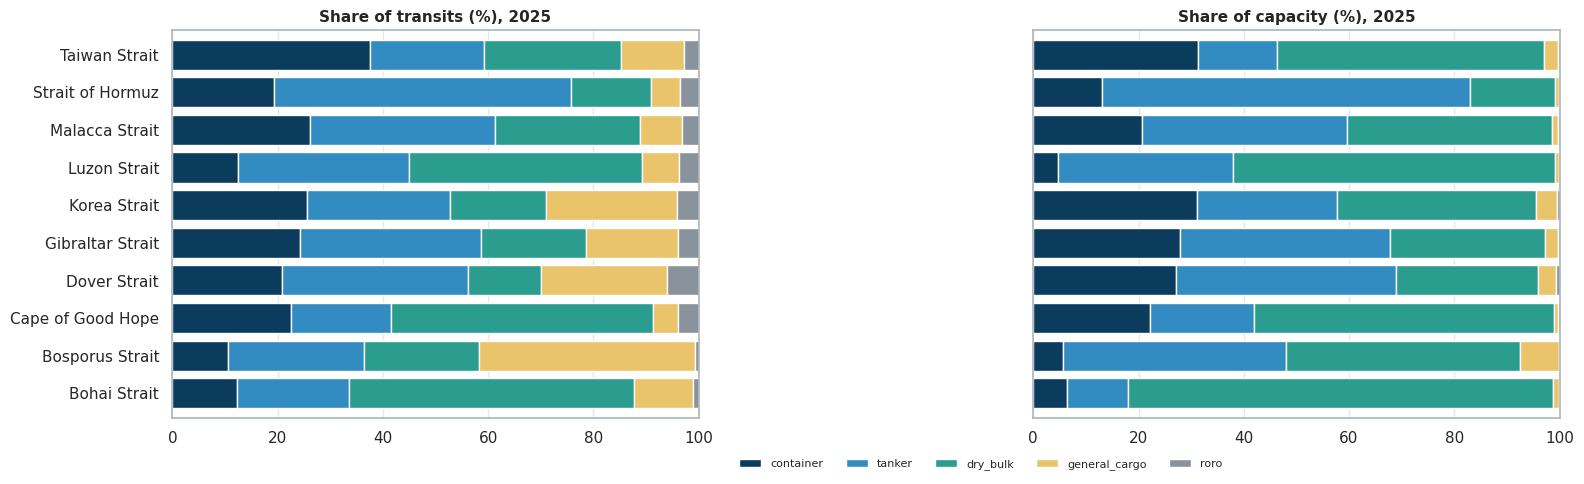

In [286]:
# vessel mix at the 10 busiest
top10 = y.index[:10]
sel = cm[(cm.year == LASTY) & cm.chokepoint.isin(top10)].groupby("chokepoint")
tt = sel[[f"n_{t}" for t in TYPES]].sum(); tt.columns = TYPES
cc = sel[[f"cap_{t}" for t in TYPES]].sum(); cc.columns = TYPES
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, df, title in ((axes[0], tt, "Share of transits (%)"), (axes[1], cc, "Share of capacity (%)")):
    (df.loc[top10[::-1], ORDER].div(df.sum(axis=1), axis=0) * 100).plot.barh(stacked=True, ax=ax, color=[TYPE_COLORS[t] for t in ORDER], width=.8, legend=False)
    ax.set_title(f"{title}, {LASTY}"); ax.set_ylabel(""); ax.set_xlim(0, 100)
axes[1].legend(ORDER, ncol=5, loc="upper center", bbox_to_anchor=(-.1, -.08), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

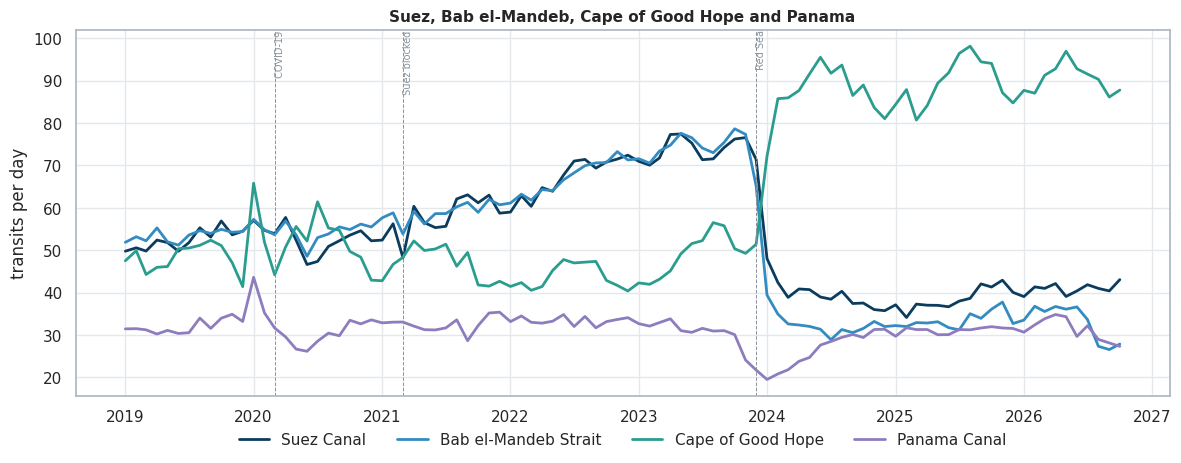

year                  2019  2020  2021  2022  2023  2024  2025  2026
chokepoint                                                          
Bab el-Mandeb Strait  53.5  54.5  58.8  67.1  74.0  32.5  33.5  33.0
Cape of Good Hope     48.1  52.8  46.9  43.8  49.1  87.0  89.5  90.5
Panama Canal          32.0  31.8  32.5  33.4  30.2  26.5  31.1  31.2
Suez Canal            52.5  52.8  57.7  67.1  73.7  39.6  38.5  40.9


In [287]:
# four corridors over time
CORR = {"Suez Canal": NAVY, "Bab el-Mandeb Strait": BLUE, "Cape of Good Hope": TEAL, "Panama Canal": PURPLE}
pv = cm.pivot(index="date", columns="chokepoint", values="per_day")
fig, ax = plt.subplots(figsize=(12, 4.8))
for c, col in CORR.items(): ax.plot(pv.index, pv[c], color=col, lw=2, label=c)
ax.set_ylabel("transits per day"); ax.set_title("Suez, Bab el-Mandeb, Cape of Good Hope and Panama")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(.5, -.06), frameon=False)
for d, label in {"2020-03": "COVID-19", "2021-03": "Suez blocked", "2023-12": "Red Sea"}.items():
    ax.axvline(pd.Timestamp(d), color=GREY, ls="--", lw=.7); ax.text(pd.Timestamp(d), ax.get_ylim()[1], " " + label, rotation=90, va="top", fontsize=7, color=GREY)
plt.tight_layout(); plt.show()
a = cm[cm.chokepoint.isin(CORR)].groupby(["chokepoint", "year"]).agg(t=("transits", "sum"), d=("days", "sum"))
print((a.t / a.d).unstack("year").round(1).to_string())

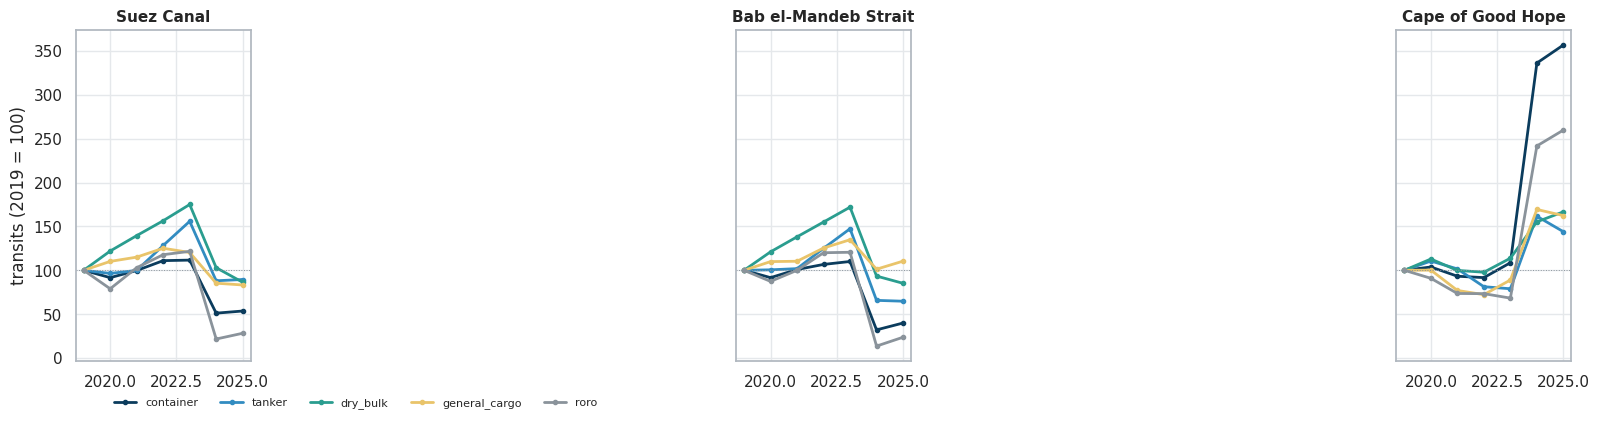

change 2023 to 2025 by vessel type (%):
                      container  dry_bulk  general_cargo   roro  tanker
Suez Canal                -52.0     -51.0          -31.0  -77.0   -43.0
Bab el-Mandeb Strait      -64.0     -50.0          -18.0  -80.0   -56.0
Cape of Good Hope         228.0      46.0           83.0  280.0    82.0


In [288]:
# Red sea diversion b vessel type
A, B, C_ = "Suez Canal", "Bab el-Mandeb Strait", "Cape of Good Hope"
yr = cm[cm.chokepoint.isin([A, B, C_]) & (cm.year <= LASTY)].groupby(["chokepoint", "year"])[[f"n_{t}" for t in TYPES]].sum()
yr.columns = TYPES
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, c in zip(axes, [A, B, C_]):
    r = yr.loc[c] / yr.loc[c].loc[2019] * 100
    for t in ORDER: ax.plot(r.index, r[t], color=TYPE_COLORS[t], lw=2, marker="o", ms=3, label=t)
    ax.axhline(100, color=GREY, lw=.7, ls=":"); ax.set_title(c)
axes[0].set_ylabel("transits (2019 = 100)"); axes[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(1.6, -.08), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(f"change 2023 to {LASTY} by vessel type (%):")
print(pd.DataFrame({c: (yr.loc[c].loc[LASTY] / yr.loc[c].loc[2023] - 1) * 100 for c in [A, B, C_]}).T.round(0).to_string())

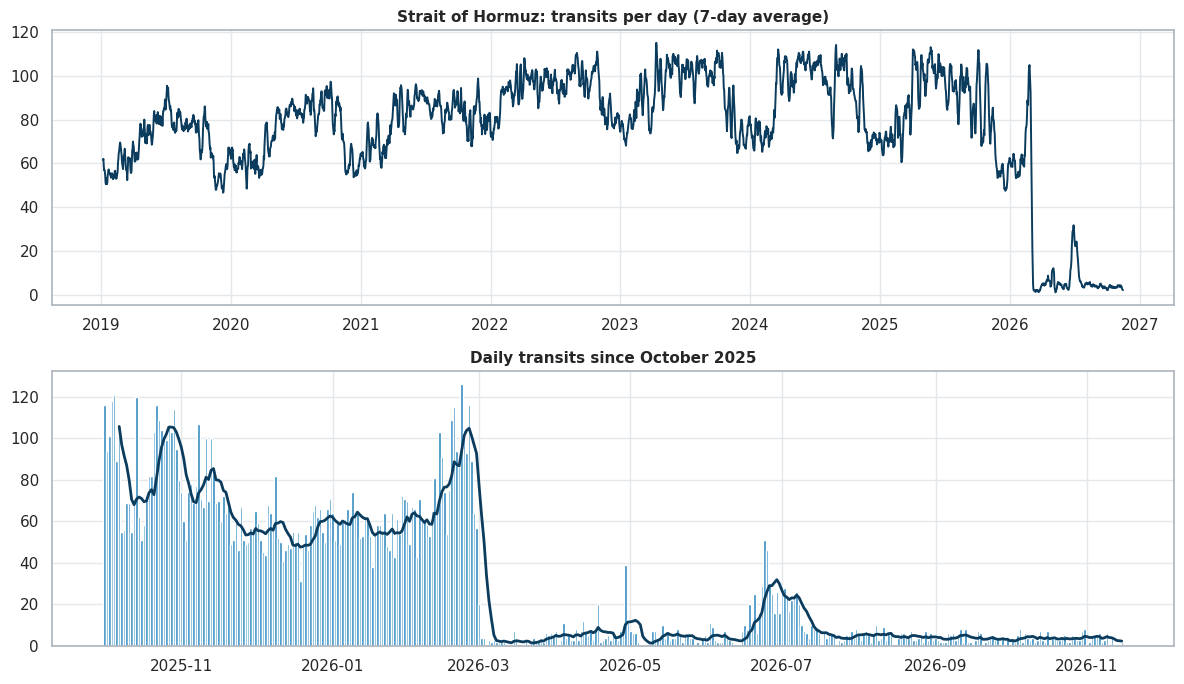

monthly average transits per day: {Period('2026-02', 'M'): 78.0, Period('2026-03', 'M'): 3.0, Period('2026-04', 'M'): 7.0, Period('2026-05', 'M'): 4.0, Period('2026-06', 'M'): 13.0, Period('2026-07', 'M'): 10.0, Period('2026-08', 'M'): 5.0, Period('2026-09', 'M'): 4.0, Period('2026-10', 'M'): 4.0, Period('2026-11', 'M'): 3.0}


In [289]:
# Strait of Hormuz
h = ck[ck.chokepoint == "Strait of Hormuz"].set_index("date").n_total
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(h.index, h.rolling(7).mean(), color=NAVY, lw=1.4); axes[0].set_title("Strait of Hormuz: transits per day (7-day average)")
r = h.loc["2025-10-01":]
axes[1].bar(r.index, r.values, color=BLUE, width=1); axes[1].plot(r.index, r.rolling(7).mean(), color=NAVY, lw=2); axes[1].set_title("Daily transits since October 2025")
plt.tight_layout(); plt.show()
print("monthly average transits per day:", h.groupby(h.index.to_period("M")).mean().round(0).tail(10).to_dict())

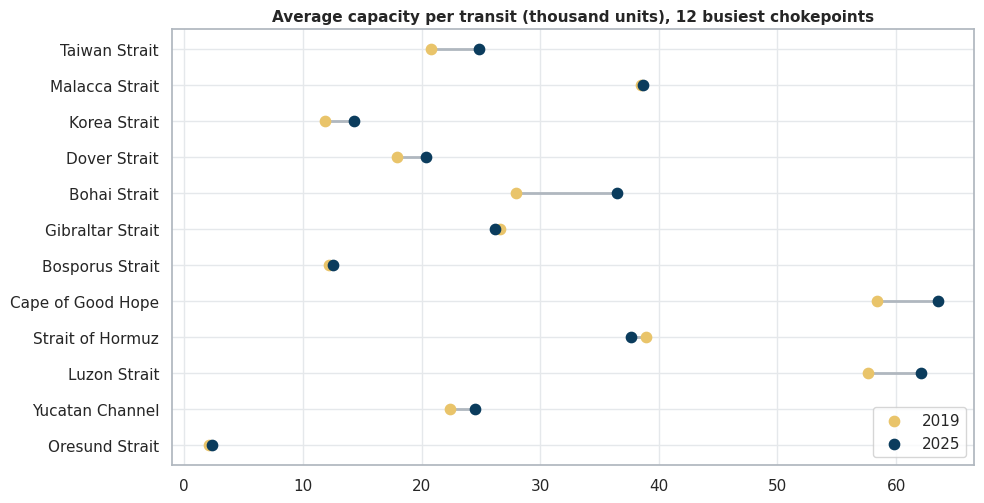

In [290]:
# average vessel size per transit
cs = cm[cm.year.isin([2019, LASTY])].groupby(["chokepoint", "year"]).agg(c=("capacity", "sum"), t=("transits", "sum"))
cs = (cs.c / cs.t.replace(0, np.nan) / 1e3).unstack("year").dropna().loc[y.index[:12]]
fig, ax = plt.subplots(figsize=(10, 5.2)); yy = np.arange(len(cs))[::-1]
ax.hlines(yy, cs[2019], cs[LASTY], color="#B0B7BF", lw=2)
ax.scatter(cs[2019], yy, color=SAND, s=55, label="2019", zorder=3); ax.scatter(cs[LASTY], yy, color=NAVY, s=55, label=str(LASTY), zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(cs.index); ax.set_title("Average capacity per transit (thousand units), 12 busiest chokepoints"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

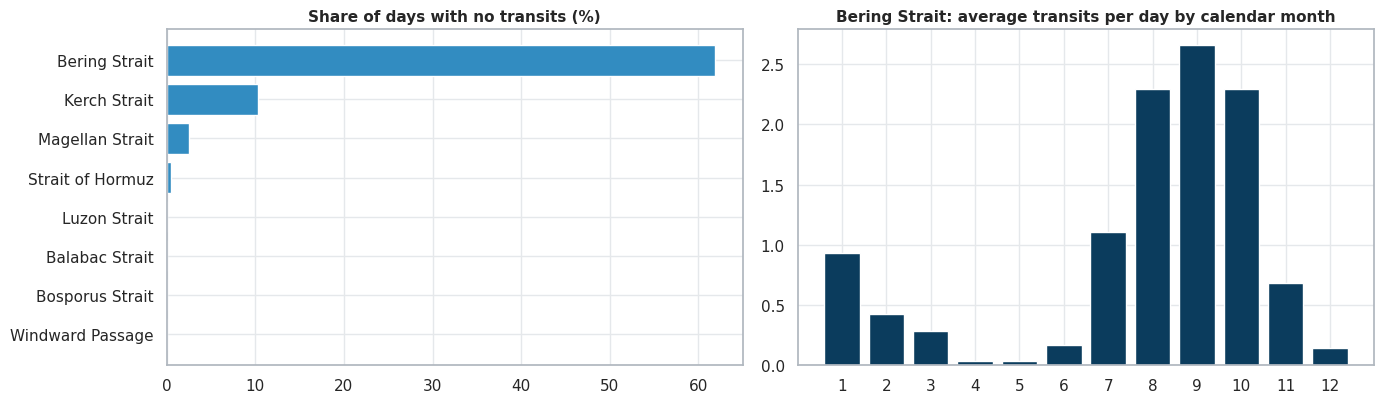

                  zero_share  zero_days
chokepoint                             
Bering Strait          0.619       1781
Kerch Strait           0.103        296
Magellan Strait        0.025         72
Strait of Hormuz       0.005         14
Luzon Strait           0.001          2
Balabac Strait         0.000          1


In [291]:
# quiet chokepoints
zd = ck.assign(zero=ck.n_total.eq(0)).groupby("chokepoint").agg(zero_share=("zero", "mean"), zero_days=("zero", "sum"))
zd = zd[zd.zero_days > 0].sort_values("zero_share", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].barh(zd.index[::-1], zd.zero_share[::-1] * 100, color=BLUE); axes[0].set_title("Share of days with no transits (%)")
b = ck[ck.chokepoint == "Bering Strait"].groupby("month").n_total.mean()
axes[1].bar(b.index, b.values, color=NAVY); axes[1].set_xticks(range(1, 13)); axes[1].set_title("Bering Strait: average transits per day by calendar month")
plt.tight_layout(); plt.show(); print(zd.head(6).round(3).to_string())

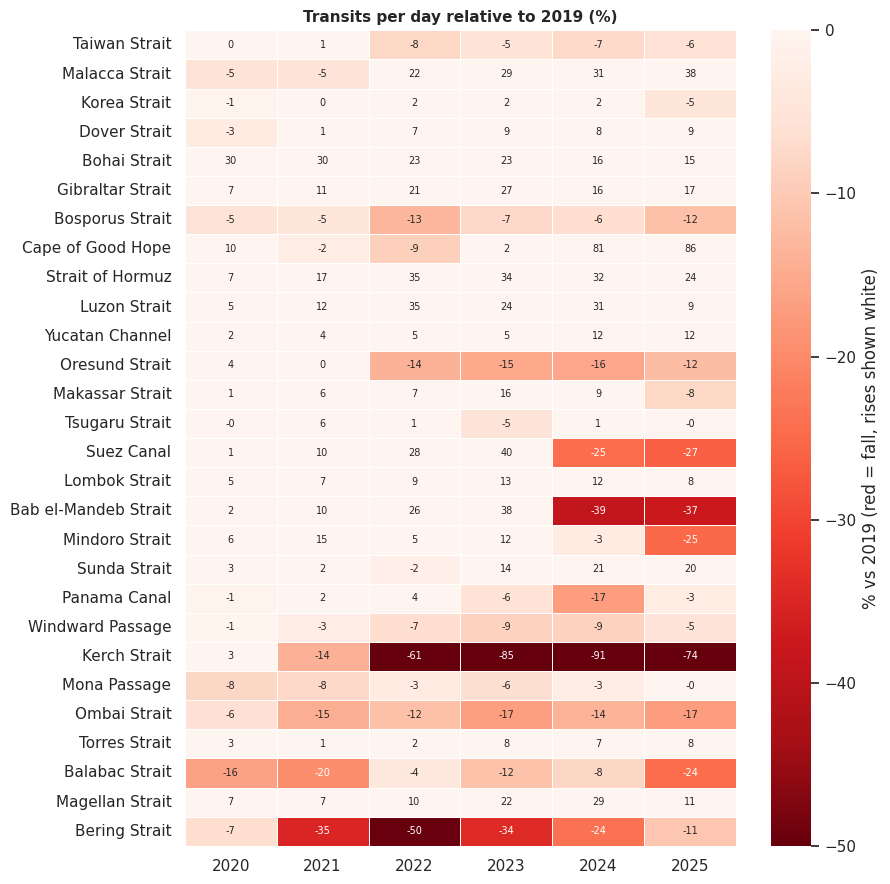

In [292]:
fy = cm[cm.year <= LASTY].groupby(["chokepoint", "year"]).agg(t=("transits", "sum"), d=("days", "sum"))
tab = (fy.t / fy.d).unstack("year"); tab = tab[tab[2019] >= 1]
rel = (tab.div(tab[2019], axis=0) * 100 - 100).drop(columns=2019).loc[tab[LASTY].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(rel, cmap="Reds_r", vmin=-50, vmax=0, annot=True, fmt=".0f", annot_kws={"size": 7}, linewidths=.5, linecolor="white", cbar_kws={"label": "% vs 2019 (red = fall, rises shown white)"}, ax=ax)
ax.set_title("Transits per day relative to 2019 (%)"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()

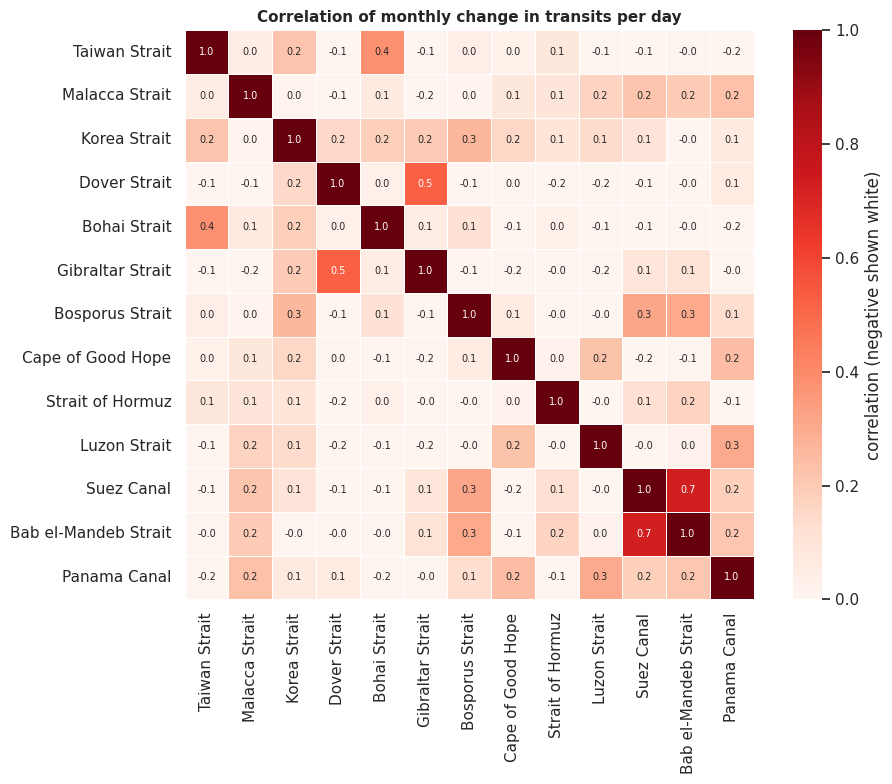

Suez vs Cape of Good Hope: -0.17 | Suez vs Bab el-Mandeb: 0.73


In [293]:
# do chokepoints move together
names = list(dict.fromkeys(list(y.index[:10]) + list(CORR)))
g = (pv[names].pct_change().dropna() * 100).replace([np.inf, -np.inf], np.nan).dropna(axis=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(g.corr(), cmap="Reds", vmin=0, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, square=True, linewidths=.5, linecolor="white", cbar_kws={"label": "correlation (negative shown white)"}, ax=ax)
ax.set_title("Correlation of monthly change in transits per day"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Suez vs Cape of Good Hope:", round(g["Suez Canal"].corr(g["Cape of Good Hope"]), 2), "| Suez vs Bab el-Mandeb:", round(g["Suez Canal"].corr(g["Bab el-Mandeb Strait"]), 2))

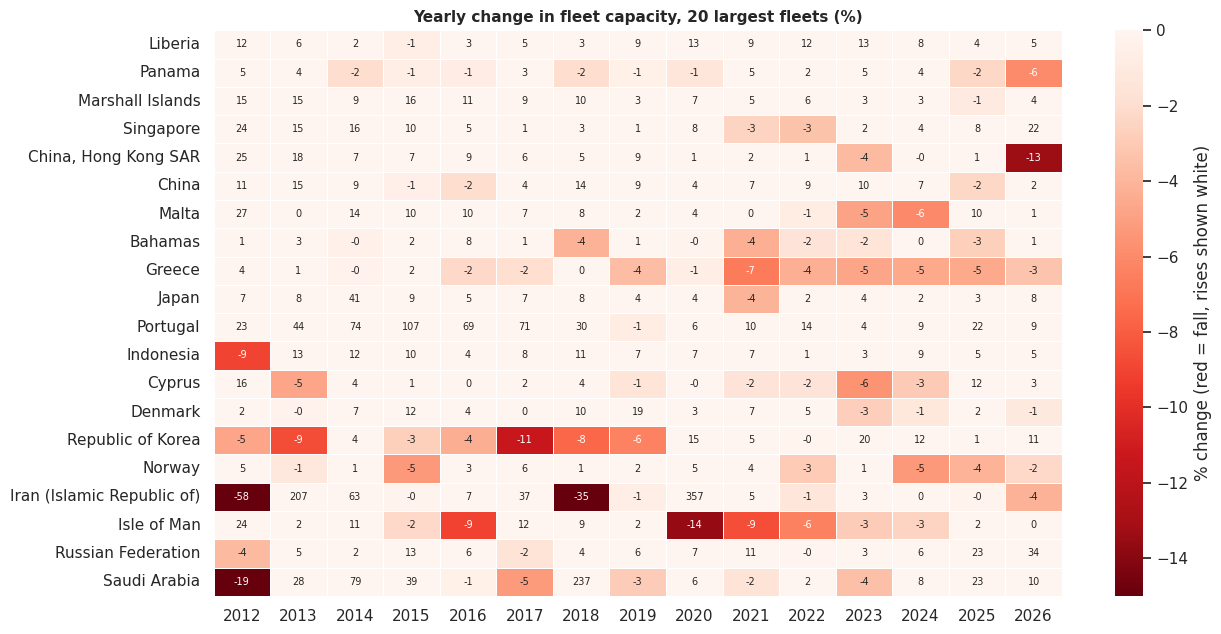

In [294]:
t20 = wd.loc[F_LAST].nlargest(20).index                  # uses wd from Cell 7
gr = wd[t20].loc[F_LAST - 15:].pct_change().dropna(how="all") * 100
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(gr.T, cmap="Reds_r", vmin=-15, vmax=0, annot=True, fmt=".0f", annot_kws={"size": 7},
            linewidths=.5, linecolor="white", cbar_kws={"label": "% change (red = fall, rises shown white)"}, ax=ax)
ax.set_title("Yearly change in fleet capacity, 20 largest fleets (%)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

# Modelling

Apply machine learning and time-series forecasting techniques to identify patterns, estimate future trade trends and detect unusual behaviour in the global maritime transport system.

Deliverables:

1. Develop a Multiple Linear Regression model to examine predictors of container port throughput.
2. Apply ARIMA to forecast global annual seaborne trade.
Use K-Means clustering to group ports based on activity profiles.
3. Apply Isolation Forest to detect unusual port activity patterns.
4. Establish suitable baseline models for comparison.
5. Evaluate model performance using appropriate metrics.
6. Interpret and document model findings and limitations.

In [297]:
### Regression
# Multiple Linear Regression
# Question: Do container ship calls and shipping connectivity help explain how many containers an economy handles each year? We match the datasets using ISO3 and Year because TEU figures are reported by economy.

# Helper function to compute error metrics
def model_errors(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

# Average the four quarterly connectivity scores for each year.
connectivity = lsci_clean.dropna(subset=["ISO3", "LSCI"])
connectivity = connectivity.groupby(["ISO3", "Year"]).agg(
    average_LSCI=("LSCI", "mean"),
    quarters=("Quarter", "nunique"),
).reset_index()
connectivity = connectivity[connectivity["quarters"] == 4]

# Add up container ship calls for each economy and year.
container_calls = pm.groupby(["ISO3", "year"]).agg(
    container_calls=("calls_container", "sum"),
    months=("date", "nunique"),
).reset_index()
container_calls = container_calls[container_calls["months"] == 12]
container_calls = container_calls.rename(columns={"year": "Year"})

# Prepare last year's throughput as a baseline.
throughput = teu_country[["ISO3", "Year", "TEU"]].dropna()
last_year = throughput.rename(columns={"TEU": "last_year_TEU"}).copy()
last_year["Year"] = last_year["Year"] + 1

# Keep the economy-years that are available in all three datasets.
regression_data = throughput.merge(connectivity, on=["ISO3", "Year"])
regression_data = regression_data.merge(container_calls, on=["ISO3", "Year"])
regression_data = regression_data.merge(last_year, on=["ISO3", "Year"])

# Use smaller units so the coefficients and errors are easier to read.
regression_data["calls_in_thousands"] = regression_data["container_calls"] / 1_000
regression_data["TEU_in_millions"] = regression_data["TEU"] / 1_000_000

training = regression_data[regression_data["Year"] <= 2022]
testing = regression_data[regression_data["Year"].between(2023, 2024)]

predictors = ["calls_in_thousands", "average_LSCI"]
target = "TEU_in_millions"

regression = LinearRegression()
regression.fit(training[predictors], training[target])

actual = testing[target]
predicted = regression.predict(testing[predictors])
median_baseline = np.repeat(training[target].median(), len(testing))
last_year_baseline = testing["last_year_TEU"] / 1_000_000

results = []
for name, values in {
    "Linear regression": predicted,
    "Training median": median_baseline,
    "Last year's TEU": last_year_baseline,
}.items():
    scores = model_errors(actual, values)
    scores["R²"] = r2_score(actual, values)
    scores["Model"] = name
    results.append(scores)

display(pd.DataFrame(results).set_index("Model").round(3))
display(pd.Series(regression.coef_, index=predictors, name= "Coefficient"))

,MAE,RMSE,MAPE (%),R²
Model,,,,
Linear regression,14.603,16.265,259.909,0.960
Training median,34.408,87.320,159.972,-0.144
Last year's TEU,2.403,5.399,5.357,0.996


,Coefficient
calls_in_thousands,13.986762
average_LSCI,0.125732



**Last year’s TEU was the best predictor.** Its average error was **2.40 million TEU**, compared with **14.60 million TEU** for linear regression. The regression had a high **R² of 0.960**, but its average percentage error was about **260%**. Percentage errors can be especially large for economies with low actual throughput.

Both predictors had positive coefficients. Holding shipping connectivity fixed, **1,000 additional container ship calls** were associated with **13.99 million more predicted TEU**. Holding ship calls fixed, a **one-point increase in average LSCI** was associated with about **126,000 more predicted TEU**.

These coefficients describe relationships in the data. The model uses ship calls and connectivity from the same year as throughput, so the results help explain differences across economies, while last year’s TEU gave more accurate predictions on the test data.

In [298]:
### Clustering
# K-Means Clustering
# Question: Which ports have similar activity? Use 2025 and describe each port by how busy it is and what kinds of ships visit it.

port_data = pm[pm["year"] == 2025]

port_profiles = port_data.groupby(["portid", "portname"]).agg(
    total_calls=("calls", "sum"),
    days=("days", "sum"),
    months=("date", "nunique"),
    container=("calls_container", "sum"),
    dry_bulk=("calls_dry_bulk", "sum"),
    general_cargo=("calls_general_cargo", "sum"),
    tanker=("calls_tanker", "sum"),
).reset_index()

# Keep ports that reported all year and received at least one ship.
full_year = port_profiles["months"] == 12
had_calls = port_profiles["total_calls"] > 0
port_profiles = port_profiles[full_year & had_calls].copy()

port_profiles["calls_per_day"] = port_profiles["total_calls"] / port_profiles["days"]
port_profiles["log_calls"] = np.log1p(port_profiles["calls_per_day"])

vessel_types = ["container", "dry_bulk", "general_cargo", "tanker"]
for vessel in vessel_types:
    port_profiles[vessel] = port_profiles[vessel] / port_profiles["total_calls"]

# The remaining share represents Ro-Ro vessels.
cluster_columns = ["log_calls"] + vessel_types
scaled_profiles = StandardScaler().fit_transform(port_profiles[cluster_columns])

cluster_results = []
labels_by_k = {}

# Start with two clusters as the baseline.
for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_profiles)
    labels_by_k[k] = labels

    cluster_results.append({
        "Clusters": k,
        "Silhouette": silhouette_score(scaled_profiles, labels),
        "Davies-Bouldin": davies_bouldin_score(scaled_profiles, labels),
    })

comparison = pd.DataFrame(cluster_results)
display(comparison.round(3))

best_row = comparison["Silhouette"].idxmax()
best_k = int(comparison.loc[best_row, "Clusters"])
port_profiles["cluster"] = labels_by_k[best_k]

summary = port_profiles.groupby("cluster")[["calls_per_day"] + vessel_types].median()
summary["ports"] = port_profiles.groupby("cluster").size()
summary[vessel_types] = summary[vessel_types] * 100

print("Selected number of clusters:", best_k)
print("Vessel shares are shown as percentages.")
display(summary.round(2))

,Clusters,Silhouette,Davies-Bouldin
0,2,0.237,1.158
1,3,0.263,1.228
2,4,0.335,1.024
3,5,0.326,1.049
4,6,0.351,0.928


Selected number of clusters: 6
Vessel shares are shown as percentages.


,calls_per_day,container,dry_bulk,general_cargo,tanker,ports
cluster,,,,,,
0,0.75,2.51,4.94,24.25,58.71,8
1,4.78,0.83,87.58,5.90,4.61,4
2,15.87,1.00,19.85,20.05,35.48,7
3,0.51,4.07,2.94,89.25,0.00,6
4,10.97,41.76,15.26,22.63,11.07,7
5,0.68,5.65,35.23,22.81,8.14,8



The six-cluster model performed best among the options tested. Compared with the two-cluster baseline, it had a higher **silhouette score** (0.351 vs. 0.237) and a lower **Davies–Bouldin score** (0.928 vs. 1.158). Both measures suggest the six groups were better defined, although some overlap likely remains.

| Cluster | Activity profile | Ports |
|---|---|---:|
| 0 | Quiet ports with mostly tanker calls | 8 |
| 1 | Dry bulk ports, with a typical dry bulk share of 88% | 4 |
| 2 | Busiest group, with about 16 calls per day and a mix of vessel types | 7 |
| 3 | Quiet ports focused on general cargo, with a typical share of 89% | 6 |
| 4 | Busy ports with the highest container share at 42% | 7 |
| 5 | Quiet ports with mixed activity, with dry bulk the largest of the vessel shares shown | 8 |

The groups show that ports differ in both **how busy they are** and **what types of vessels visit them**. These results describe the **40 ports included in the 2025 analysis** and depend on the activity measures used.

In [299]:
### Forecating
# ARIMA Forecasting
# Question: How might annual global seaborne trade change? Use the World total goods loaded series and keep the last five observations for testing.

world_rows = (
    (seaborne_clean["Economy"] == "World")
    & (seaborne_clean["Cargo_type"] == "Total goods loaded")
)
world_trade = seaborne_clean.loc[world_rows].sort_values("Year")

years = world_trade["Year"].astype(int).to_numpy()
if len(years) < 15 or not np.all(np.diff(years) == 1):
    raise ValueError("Check that the World series has one row for each consecutive year.")

# Convert thousand tonnes to million tonnes.
trade = pd.Series(
    world_trade["Trade_thousand_tonnes"].to_numpy() / 1_000,
    index=pd.PeriodIndex(years.astype(str), freq="Y"),
)

training_trade = trade.iloc[:-5]
testing_trade = trade.iloc[-5:]

arima = ARIMA(training_trade, order=(1, 1, 0), trend="t").fit()
arima_predictions = arima.forecast(steps=5)

# Baseline 1 keeps trade at the last known amount.
last_value = training_trade.iloc[-1]
flat_predictions = np.repeat(last_value, 5)

# Baseline 2 continues the average annual change.
first_value = training_trade.iloc[0]
average_change = (last_value - first_value) / (len(training_trade) - 1)
drift_predictions = last_value + average_change * np.arange(1, 6)

forecast_scores = pd.DataFrame({
    "ARIMA": model_errors(testing_trade, arima_predictions),
    "Last known value": model_errors(testing_trade, flat_predictions),
    "Average yearly change": model_errors(testing_trade, drift_predictions),
}).T

display(forecast_scores.round(2))

# Refit on the full history for the five-year projection.
final_arima = ARIMA(trade, order=(1, 1, 0), trend="t").fit()
next_five_years = final_arima.get_forecast(steps=5)

forecast_table = next_five_years.conf_int()
forecast_table.columns = ["Lower 95%", "Upper 95%"]
forecast_table["Forecast"] = next_five_years.predicted_mean
print("Holdout fit converged:", arima.mle_retvals["converged"])
print("Final fit converged:", final_arima.mle_retvals["converged"])
display(forecast_table[["Forecast", "Lower 95%", "Upper 95%"]].round(2))

,MAE,RMSE,MAPE (%)
ARIMA,820.00,863.39,7.00
Last known value,207.88,251.66,1.77
Average yearly change,761.40,805.09,6.50


Holdout fit converged: True
Final fit converged: True


,Forecast,Lower 95%,Upper 95%
2025,12258.60,11601.86,12915.34
2026,12504.34,11648.46,13360.21
2027,12743.30,11716.89,13769.71
2028,12983.38,11812.39,14154.37
2029,13223.27,11923.48,14523.07



The **last known value** gave the best predictions on the five test years. Its average error was **208 million tonnes (1.77% MAPE)**, compared with **820 million tonnes (7.00% MAPE)** for ARIMA. It also had the lowest RMSE. Both ARIMA fits converged, meaning the fitting process finished successfully.

ARIMA projects global seaborne trade to rise from **12.26 billion tonnes in 2025** to **13.22 billion tonnes in 2029**. The 95% prediction interval widens over time, reaching **11.92 to 14.52 billion tonnes** in 2029. This shows greater uncertainty further into the future. The upward forecast should be interpreted cautiously because the simple baseline performed better on the test years.

In [300]:
### Anomaly detection
# Isolation Forest
# Question: Which port-months look unusual compared with the same month a year earlier? Average daily rates account for differences in month length.

activity = pm[[
    "portid", "portname", "date", "days",
    "calls", "calls_container", "calls_tanker",
]].copy()

activity["total_rate"] = activity["calls"] / activity["days"]
activity["container_rate"] = activity["calls_container"] / activity["days"]
activity["tanker_rate"] = activity["calls_tanker"] / activity["days"]

rates = ["total_rate", "container_rate", "tanker_rate"]

# Move last year's dates forward to match each month with the current year.
previous = activity[["portid", "date"] + rates].copy()
previous["date"] = previous["date"] + pd.DateOffset(years=1)

activity = activity.merge(
    previous, on=["portid", "date"], suffixes=("", "_last_year"),
    validate="one_to_one",
)

# Log changes keep very large ports from dominating the comparison.
change_columns = []
for rate in rates:
    column = rate + "_change"
    current_rate = np.log1p(activity[rate])
    previous_rate = np.log1p(activity[rate + "_last_year"])
    activity[column] = current_rate - previous_rate
    change_columns.append(column)

past = activity[activity["date"].dt.year <= 2024]
check_2025 = activity[activity["date"].dt.year == 2025].copy()

forest = IsolationForest(random_state=42, n_jobs=-1)
forest.fit(past[change_columns])

# Reverse the sign so a larger score means a more unusual month.
past_scores = -forest.score_samples(past[change_columns])
check_2025["unusual_score"] = -forest.score_samples(check_2025[change_columns])

forest_cutoff = np.quantile(past_scores, 0.98)
check_2025["forest_flag"] = check_2025["unusual_score"] >= forest_cutoff

# The baseline looks only at the size of the change in total calls.
baseline_cutoff = past["total_rate_change"].abs().quantile(0.98)
check_2025["baseline_flag"] = check_2025["total_rate_change"].abs() >= baseline_cutoff

both_methods = check_2025["forest_flag"] & check_2025["baseline_flag"]
print("Months checked:", len(check_2025))
print("Isolation Forest flags:", check_2025["forest_flag"].sum())
print("Baseline flags:", check_2025["baseline_flag"].sum())
print("Flagged by both:", both_methods.sum())

for percentile in [0.99, 0.98, 0.95]:
    cutoff = np.quantile(past_scores, percentile)
    flags = check_2025["unusual_score"] >= cutoff
    print(f"Flags using the {percentile:.0%} training percentile:", flags.sum())

flagged_months = check_2025[check_2025["forest_flag"]]
top_months = flagged_months.nlargest(10, "unusual_score")

display(top_months[[
    "portname", "date", "total_rate", "total_rate_last_year",
    "container_rate_change", "tanker_rate_change", "unusual_score", "baseline_flag",
]].round(2))

Months checked: 481
Isolation Forest flags: 2
Baseline flags: 2
Flagged by both: 0
Flags using the 99% training percentile: 0
Flags using the 98% training percentile: 2
Flags using the 95% training percentile: 18


,portname,date,total_rate,total_rate_last_year,container_rate_change,tanker_rate_change,unusual_score,baseline_flag
1785,Yatsushiro,2025-04-01,2.07,3.37,-0.11,-0.44,0.66,False
1787,Yatsushiro,2025-06-01,1.93,3.20,-0.10,-0.39,0.65,False



Isolation Forest flagged **2 of 481 port-months (0.42%)** at the 98th-percentile cutoff. Both were at **Yatsushiro**, where average daily vessel calls fell by **39% in April** and **40% in June** compared with the same months in 2024. Container and tanker activity also fell in both months.

The baseline flagged two different port-months. It looks only at changes in total calls, while Isolation Forest also considers changes in container and tanker calls.

The number of flags depended on the cutoff. The 99th percentile flagged **0** records, while the 95th percentile flagged **18**. Without verified anomaly labels, the two Yatsushiro months are candidates for review, and the cause of the declines remains unknown.

In [302]:

model_comparison = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "ARIMA",
        "K-Means",
        "Isolation Forest",
    ],
    "Model result": [
        "MAE: 14.60 million TEU",
        "MAE: 820.00 million tonnes",
        "6 clusters, silhouette: 0.351",
        "2 port-months flagged",
    ],
    "Baseline result": [
        "Last year's TEU, MAE: 2.40 million TEU",
        "Last known value, MAE: 207.88 million tonnes",
        "2 clusters, silhouette: 0.237",
        "Simple threshold flagged 2 different port-months",
    ],
    "Verdict": [
        "Last year's TEU performed better",
        "Last known value performed better",
        "6-cluster K-Means performed better",
        "Accuracy cannot be compared without verified labels",
    ],
})

display(model_comparison.set_index("Model"))

,Model result,Baseline result,Verdict
Model,,,
Multiple Linear Regression,MAE: 14.60 million TEU,"Last year's TEU, MAE: 2.40 million TEU",Last year's TEU performed better
ARIMA,MAE: 820.00 million tonnes,"Last known value, MAE: 207.88 million tonnes",Last known value performed better
K-Means,"6 clusters, silhouette: 0.351","2 clusters, silhouette: 0.237",6-cluster K-Means performed better
Isolation Forest,2 port-months flagged,Simple threshold flagged 2 different port-months,Accuracy cannot be compared without verified l...


# Evaluation

# Deployment